## LaDe 22: Regular Aoi Work Pattern (Flag 22)

### Dataset Overview

Constructed LaDe-style courier data on archived Shanghai WGS84 OSM roads. Task IDs, schedules, movement speeds, delivery windows, AOIs and regions are synthetic extensions, not original LaDe observations. Native fclass, oneway, bridge and tunnel attributes are copied from OSM; absence of a tag is encoded no, not independent confirmation that a structure is absent. GPS retains all road vertices; spatial spacing is at most 22 m, stationary intervals at most 55 s. Each travelling row and its road_segment_id describe the immediately preceding GPS interval; stationary rows have no road attribution. Speed is distance divided by time, excluding service/waiting. Route directness ratio means travelled distance divided by straight-line task-endpoint distance. One-way share is distance weighted (0–1), not percent. Movement phases label ordered workday route periods, not fixed clock bins. Directions are checked but OSM turn restrictions are not modeled. Tunnel coordinates are constructed map interpolation, not authentic underground GPS fixes. All times are local Shanghai time. Pending tasks intentionally have no completion time or arrival leg; other task completions coincide with stationary GPS fixes. Service visits are recorded intervals at roadside task sites, not official AOI boundaries. Repositioning and return legs remain visible but are excluded where an insight concerns task-to-task legs. Schema word "recipe" is interpreted as receipt; fixed receipt events are supplied separately. AOI spend-time ratio is visit duration / full observed workday, averaged across days.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Identify the regular work pattern of the courier and find potential deviations from it.

Role: Last-mile logistics analyst


Category: regular_aoi_work_pattern


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "delivery_tasks.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: What CSV-derived evidence supports insight 1?

#### Analysis action

Interpret the constructed descriptive association, not an estimated causal effect.

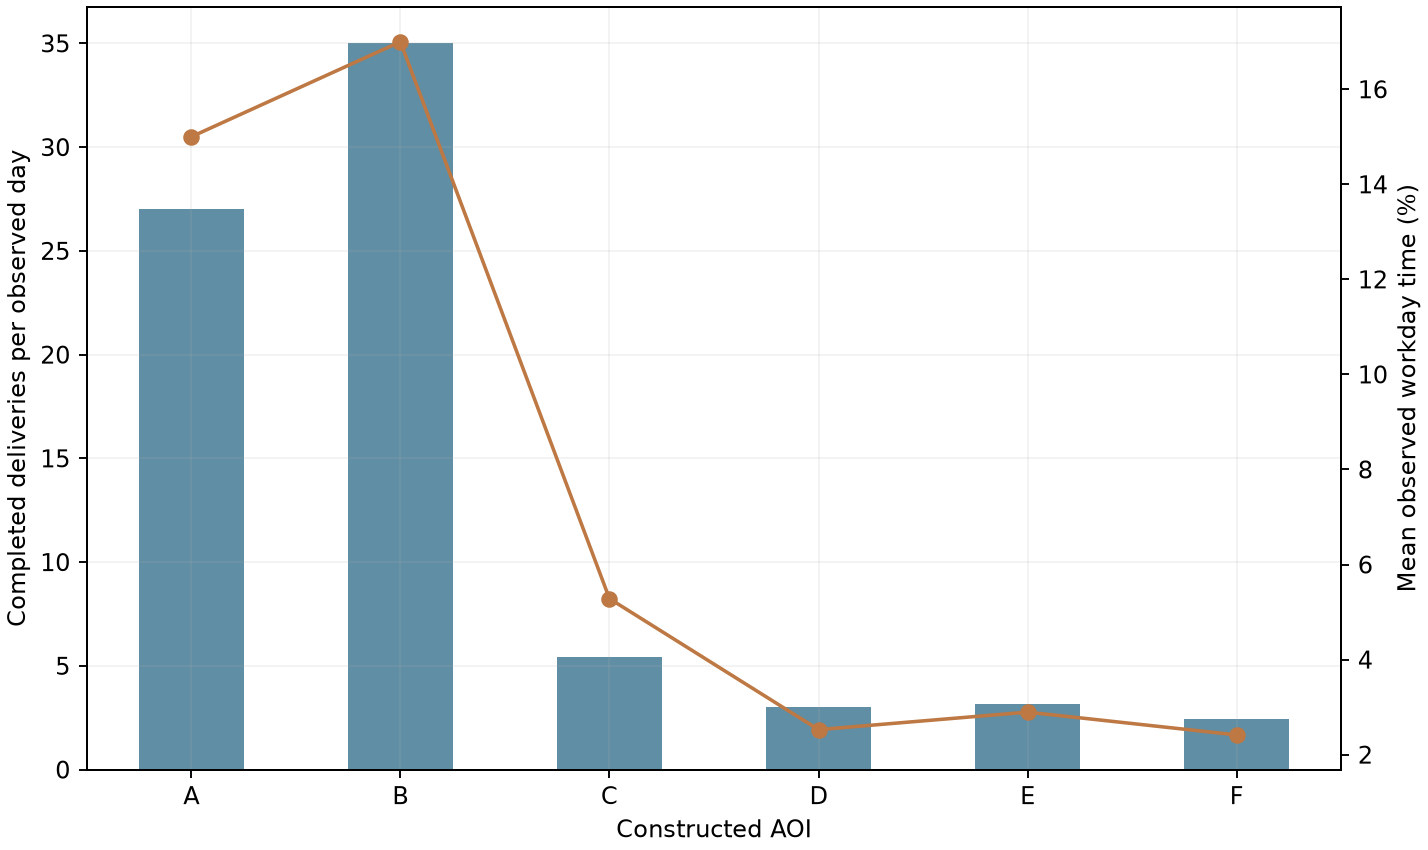

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

legs = pd.read_csv("movement_legs.csv")
visits = pd.read_csv("aoi_visits.csv")
extra = {}
extra["receipt_events"] = pd.read_csv("receipt_events.csv")
extra["aois"] = pd.read_csv("aois.csv")


def evidence(case, index, df, user_df, legs, visits, extra):
    import json
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)
    moving = user_df[user_df.activity_state.eq("travelling")].copy()
    done = df[df.status.eq("completed")].copy()
    value = {}
    if case == 21:
        order = ["primary", "secondary", "tertiary", "residential"]
        moving = moving.merge(
            legs[["leg_id", "period"]], on="leg_id", validate="many_to_one"
        )
        if index == 1:
            summary = (
                moving.groupby("fclass")[["step_distance_km", "step_duration_s"]]
                .sum()
                .reindex(order)
            )
            summary["movement_speed_kmh"] = (
                summary.step_distance_km / summary.step_duration_s * 3600
            )
            summary["completions"] = done.delivery_fclass.value_counts().reindex(
                order, fill_value=0
            )
            summary["completions_per_km"] = (
                summary.completions / summary.step_distance_km
            )
            ax.bar(
                order,
                summary.movement_speed_kmh,
                color="#5c8ea7",
                alpha=0.8,
                label="Movement speed",
            )
            twin = ax.twinx()
            twin.plot(order, summary.completions_per_km, "o-", color="#bd7843")
            ax.set(ylabel="Distance / moving time (km/h)", xlabel="Native OSM fclass")
            twin.set_ylabel("Delivery completions per travelled km", color="#bd7843")
            value = {"road_class_summary": summary.to_dict("index")}
        elif index == 2:
            summary = (
                moving.groupby(["period", "fclass"])
                .step_distance_km.sum()
                .unstack(fill_value=0)
            )
            summary = summary.div(summary.sum(axis=1), axis=0).reindex(
                ["early", "late"]
            )
            summary[order].plot.bar(stacked=True, ax=ax, rot=0)
            ax.set(
                ylabel="Share of all moving distance",
                xlabel="First / second half of scheduled delivery stops",
            )
            tasks = done.merge(
                legs[["leg_id", "period"]], left_on="arrival_leg_id", right_on="leg_id"
            )
            value = {
                "distance_shares": summary.to_dict("index"),
                "completion_counts": tasks.period.value_counts().to_dict(),
            }
        else:
            # Smooth spatial AND temporal event kernel, independently measured
            # from task-completion positions/times rather than a generator label.
            frames = []
            for tid, q in moving.groupby("trajectory_id"):
                t = done[done.trajectory_id.eq(tid)]
                x = q[["lng", "lat"]].to_numpy() * [95.2, 111]
                y = t[["delivery_lng", "delivery_lat"]].to_numpy() * [95.2, 111]
                ds = np.linalg.norm(x[:, None] - y[None, :], axis=2)
                a = (
                    pd.to_datetime(q.gps_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                b = (
                    pd.to_datetime(t.completion_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                dt = abs(a[:, None] - b[None, :]) / 6e10
                q = q.copy()
                q["nearby_activity"] = (np.exp(-ds / 0.30) * np.exp(-dt / 30)).sum(
                    axis=1
                )
                frames.append(q)
            points = pd.concat(frames)
            values = {}
            for cls in order:
                q = points[points.fclass.eq(cls)]
                bins = pd.qcut(q.nearby_activity, 5, duplicates="drop")
                med = q.groupby(bins, observed=True)[
                    ["nearby_activity", "speed_kmh"]
                ].median()
                line = ax.plot(med.nearby_activity, med.speed_kmh, "o-", label=cls)[0]
                sample = q.sample(min(350, len(q)), random_state=17)
                ax.scatter(
                    sample.nearby_activity,
                    sample.speed_kmh,
                    s=6,
                    alpha=0.10,
                    color=line.get_color(),
                )
                values[cls] = {
                    "points": len(q),
                    "spearman": q.nearby_activity.corr(q.speed_kmh, method="spearman"),
                    "low_to_high_activity_speed_drop_kmh": (
                        med.speed_kmh.iloc[0] - med.speed_kmh.iloc[-1]
                    ),
                    "quintile_medians": med.to_dict("list"),
                }
            ax.set(
                xlabel=(
                    "Nearby completion intensity (300 m / 30 min exponential kernel)"
                ),
                ylabel="Median moving speed (km/h)",
            )
            ax.legend()
            value = {"within_class_evidence": values}
    elif case == 22:
        if index == 1:
            counts = (
                done.groupby(["service_date", "aoi_id"]).size().unstack(fill_value=0)
            )
            span = user_df.groupby("trajectory_id").gps_time.agg(["min", "max"])
            duration = (
                pd.to_datetime(span["max"], format="mixed")
                - pd.to_datetime(span["min"], format="mixed")
            ).dt.total_seconds()
            shares = (
                visits.groupby(["trajectory_id", "aoi_id"])
                .duration_s.sum()
                .unstack(fill_value=0)
                .div(duration, axis=0)
            )
            summary = pd.DataFrame(
                {
                    "mean_deliveries_per_day": counts.mean(),
                    "mean_work_time_share": shares.mean(),
                }
            )
            summary.plot.bar(
                y="mean_deliveries_per_day", ax=ax, rot=0, legend=False, color="#608ea4"
            )
            ax.set(
                ylabel="Completed deliveries per observed day", xlabel="Constructed AOI"
            )
            twin = ax.twinx()
            twin.plot(
                np.arange(len(summary)),
                summary.mean_work_time_share * 100,
                "o-",
                color="#bd7843",
            )
            twin.set_ylabel("Mean observed workday time (%)")
            value = {
                "aoi_summary": summary.to_dict("index"),
                "observed_days": counts.shape[0],
                "regular_destination_fclasses": sorted(
                    done[done.regular_aoi.eq("yes")].delivery_fclass.unique().tolist()
                ),
                "fixed_receipt_sites": (
                    extra["receipt_events"]
                    .groupby("aoi_id")[["lng", "lat"]]
                    .nunique()
                    .to_dict("index")
                ),
            }
        elif index == 2:
            q = legs[legs.purpose.eq("delivery")]
            plt.close(fig)
            fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), constrained_layout=True)
            ax = axes[0]
            ax.boxplot(
                [q[q.period.eq(p)].route_directness_ratio for p in ["early", "late"]],
                tick_labels=["Early", "Late"],
            )
            ax.set(
                xlabel="Delivery route phase",
                ylabel="Travelled / straight-line distance",
                title=(
                    "Later delivery routes are more direct\nLower ratio = less detour"
                ),
            )
            dates = sorted(q.service_date.unique())
            totals = moving.groupby("service_date")[
                ["step_distance_km", "step_duration_s"]
            ].sum()
            baseline = totals.step_distance_km / totals.step_duration_s * 3600
            late = q[q.period.eq("late")].copy()
            late["day_mean_movement_speed_kmh"] = late.service_date.map(baseline)
            late["difference_from_day_mean_kmh"] = (
                late.mean_speed_kmh - late.day_mean_movement_speed_kmh
            )
            above = late.difference_from_day_mean_kmh.gt(0)
            x = late.service_date.map({day: i for i, day in enumerate(dates)}).to_numpy(
                dtype=float
            )
            x += np.where(late.groupby("service_date").cumcount().eq(0), -0.12, 0.12)
            axes[1].axhline(
                0,
                color="#555555",
                linewidth=1,
                linestyle="--",
                label="Same as day mean",
            )
            for mask, color, label in [
                (above, "#3976a8", "Above day mean"),
                (~above, "#c77c3d", "At or below day mean"),
            ]:
                axes[1].scatter(
                    x[mask],
                    late.loc[mask, "difference_from_day_mean_kmh"],
                    color=color,
                    s=48,
                    label=f"{label}: {int(mask.sum())}/{len(late)} ({mask.mean():.1%})",
                )
            axes[1].set(
                xticks=np.arange(len(dates)),
                xticklabels=[day[5:] for day in dates],
                xlabel="Workday — each point is a delivery leg as time drew to a close",
                ylabel="Leg speed − day mean movement speed (km/h)",
                title=(
                    "As time drew to a close:\nMore direct does not guarantee"
                    " above-average speed"
                ),
            )
            axes[1].margins(y=0.30)
            axes[1].tick_params(axis="x", rotation=45, labelsize=8)
            axes[1].legend(loc="upper left", fontsize=8, frameon=False)
            axes[1].grid(axis="y", alpha=0.15)
            value = {
                "period_means": (
                    q.groupby("period")[["route_directness_ratio", "mean_speed_kmh"]]
                    .mean()
                    .to_dict("index")
                ),
                "day_mean_definition": (
                    "All moving GPS distance / all moving GPS time, including return"
                    " legs and excluding stops"
                ),
                "daily_mean_movement_speed_kmh": baseline.to_dict(),
                "late_delivery_legs": len(late),
                "late_legs_above_day_mean": int(above.sum()),
                "late_share_above_day_mean": float(above.mean()),
                "late_leg_comparison": (
                    late[
                        [
                            "leg_id",
                            "service_date",
                            "mean_speed_kmh",
                            "day_mean_movement_speed_kmh",
                            "difference_from_day_mean_kmh",
                        ]
                    ].to_dict("records")
                ),
            }
        elif index == 3:
            q = done.copy()
            stamp = pd.to_datetime(q.completion_time, format="mixed")
            q["completion_hour"] = (
                stamp.dt.hour + stamp.dt.minute / 60 + stamp.dt.second / 3600
            )
            q["window_hours"] = (
                pd.to_datetime(q.time_window_end) - pd.to_datetime(q.time_window_start)
            ).dt.total_seconds() / 3600
            plt.close(fig)
            fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5), constrained_layout=True)
            ax = axes[0]
            groups = [
                q[q.regular_aoi.eq("no") & q.window_hours.lt(9)],
                q[q.regular_aoi.eq("no") & q.window_hours.ge(9)],
                q[q.regular_aoi.eq("yes") & q.window_hours.ge(9)],
            ]
            labels = [
                "Non-regular AOIs\nWindow <9 h",
                "Non-regular AOIs\nWindow ≥9 h",
                "Regular AOIs (A/B)\nWindow ≥9 h",
            ]
            colors = ["#4f846c", "#3976a8", "#c77c3d"]
            boxes = ax.boxplot(
                [g.completion_hour for g in groups],
                tick_labels=labels,
                patch_artist=True,
            )
            for box, color in zip(boxes["boxes"], colors):
                box.set_facecolor(color)
                box.set_alpha(0.45)
            for i, g in enumerate(groups, 1):
                median = g.completion_hour.median()
                h = int(median)
                minute = int(round((median - h) * 60))
                ax.text(
                    i,
                    17.8,
                    f"n={len(g)}\nMedian {h:02}:{minute:02}",
                    ha="center",
                    fontsize=9,
                )
            ax.set(
                ylabel="Task completion time (Shanghai)",
                title="Both non-regular window groups finish earlier",
                ylim=(7.5, 18.5),
            )
            ax.yaxis.set_major_formatter(lambda v, _: f"{int(v):02}:00")
            ax.tick_params(axis="x", labelsize=8)
            for g, label, color, marker in zip(groups, labels, colors, ["o", "s", "^"]):
                axes[1].scatter(
                    g.window_hours,
                    g.completion_hour,
                    s=16,
                    alpha=0.45,
                    color=color,
                    marker=marker,
                    label=label.replace("\n", "; "),
                )
            axes[1].set(
                xlabel="Service-window duration (hours)",
                ylabel="Task completion time (Shanghai)",
                title="Wide windows alone do not explain later completion",
                ylim=(7.5, 19.5),
            )
            axes[1].yaxis.set_major_formatter(lambda v, _: f"{int(v):02}:00")
            axes[1].legend(loc="upper left", fontsize=8, frameon=False)
            axes[1].grid(alpha=0.15)
            nvisits = visits.groupby(["service_date", "aoi_id"]).size()
            value = {
                "group_medians": (
                    q.groupby("regular_aoi")[["completion_hour", "window_hours"]]
                    .median()
                    .to_dict("index")
                ),
                "regular_aoi_visits_per_day": (
                    nvisits.unstack(fill_value=0)[["A", "B"]].to_dict("list")
                ),
                "irregular_by_window_median_hour": (
                    q[q.regular_aoi.eq("no")]
                    .assign(
                        window_group=lambda d: np.where(
                            d.window_hours < 9, "Narrower (<9h)", "Wide (9h+)"
                        )
                    )
                    .groupby("window_group")
                    .completion_hour.median()
                    .to_dict()
                ),
                "plotted_groups": {
                    label.replace("\n", "; "): {
                        "tasks": len(g),
                        "median_completion_hour": float(g.completion_hour.median()),
                        "window_hours_min": float(g.window_hours.min()),
                        "window_hours_max": float(g.window_hours.max()),
                    }
                    for label, g in zip(labels, groups)
                },
                "uncompleted_tasks_excluded": int(df.status.ne("completed").sum()),
            }
        else:
            irregular = df[df.regular_aoi.eq("no")]
            summary = (
                irregular.groupby(["service_date", "status"])
                .size()
                .unstack(fill_value=0)
            )
            summary.plot.bar(stacked=True, ax=ax, rot=50)
            ax.set(ylabel="Available irregular-AOI tasks", xlabel="Workday")
            pending = irregular[irregular.status.eq("pending")]
            dates = pending.service_date.unique().tolist()
            min_dist = {}
            for day in dates:
                gps = user_df[user_df.service_date.eq(day)]
                destinations = pending[pending.service_date.eq(day)][
                    ["aoi_id", "delivery_lng", "delivery_lat"]
                ].drop_duplicates()
                for r in destinations.itertuples():
                    ds = np.linalg.norm(
                        (
                            gps[["lng", "lat"]].to_numpy()
                            - [r.delivery_lng, r.delivery_lat]
                        )
                        * [95200, 111000],
                        axis=1,
                    )
                    min_dist[r.aoi_id] = float(ds.min())
            value = {
                "pending_dates": dates,
                "pending_tasks": len(pending),
                "minimum_GPS_distance_to_unvisited_AOI_m": min_dist,
                "anomaly_day_irregular_visit_count": int(
                    len(
                        visits[
                            visits.service_date.isin(dates)
                            & ~visits.aoi_id.isin(["A", "B"])
                        ]
                    )
                ),
            }
    elif case == 23:
        q = legs[legs.purpose.eq("delivery")].copy()
        # Initial departure is not between two completed task locations.
        q = q[q.groupby("trajectory_id").cumcount().gt(0)]
        if index == 1:
            q = q[q.period.ne("exception") & q.separation_km.between(0.7, 1.4)]
            q["oneway_group"] = np.where(
                q.oneway_share >= 0.55,
                "High (55%+)",
                np.where(q.oneway_share <= 0.25, "Low (0–25%)", "Middle"),
            )
            q = q[q.oneway_group.ne("Middle")]
            for name, s in q.groupby("oneway_group"):
                ax.scatter(
                    s.separation_km, s.route_directness_ratio, label=name, alpha=0.6
                )
            ax.set(
                xlabel="Task endpoint separation (km)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "matched_separation_range_km": [0.7, 1.4],
                "group_means": (
                    q.groupby("oneway_group")[
                        ["separation_km", "route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "within_period_group_means": (
                    q.groupby(["period", "oneway_group"])[
                        ["route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .reset_index()
                    .to_dict("records")
                ),
            }
        elif index == 2:
            means = (
                q[q.period.ne("exception")]
                .groupby("period")[["mean_speed_kmh", "route_directness_ratio"]]
                .mean()
                .reindex(["early", "midday", "late"])
            )
            ax.plot(means.index, means.mean_speed_kmh, "o-", color="#608ea4")
            ax.set_ylabel("Mean leg speed (km/h)")
            twin = ax.twinx()
            twin.plot(means.index, means.route_directness_ratio, "s-", color="#bd7843")
            twin.set_ylabel("Mean route directness ratio")
            value = {"period_means": means.to_dict("index")}
        elif index == 3:
            p = (
                q[q.period.ne("exception")]
                .groupby(["service_date", "period"])
                .agg(
                    detour_sd=("route_directness_ratio", "std"),
                    speed_sd=("mean_speed_kmh", "std"),
                    transitions=("fclass_transitions", "sum"),
                    distance=("distance_km", "sum"),
                )
            )
            p["transitions_per_km"] = p.transitions / p.distance
            ax.scatter(
                p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap="viridis", s=50
            )
            fig.colorbar(ax.collections[0], ax=ax, label="Across-leg speed SD (km/h)")
            ax.set(
                xlabel="Native fclass transitions per travelled km",
                ylabel="Within-period route-ratio SD",
            )
            cut = p.transitions_per_km.median()
            p["transition_group"] = np.where(
                p.transitions_per_km > cut, "Frequent", "Less frequent"
            )
            value = {
                "correlation_transition_frequency_detour_sd": p.transitions_per_km.corr(
                    p.detour_sd
                ),
                "group_means": (
                    p.groupby("transition_group")[
                        ["detour_sd", "speed_sd", "transitions_per_km"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "period_count": len(p),
            }
        else:
            normal = q[q.period.ne("exception")]
            exception = q[q.period.eq("exception")]
            ax.scatter(
                normal.oneway_share * 100,
                normal.route_directness_ratio,
                alpha=0.4,
                label="Other task legs",
            )
            ax.scatter(
                exception.oneway_share * 100,
                exception.route_directness_ratio,
                marker="*",
                s=220,
                color="#c66643",
                label="Exceptional period",
            )
            ax.set(
                xlabel="One-way-road distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "exception": (
                    exception[
                        [
                            "leg_id",
                            "route_directness_ratio",
                            "oneway_share",
                            "mean_speed_kmh",
                            "distance_km",
                            "separation_km",
                        ]
                    ].to_dict("records")
                ),
                "normal_speed_10_90_percentiles": (
                    normal.mean_speed_kmh.quantile([0.1, 0.9]).tolist()
                ),
                "schema_oneway_unit_assumption": (
                    "2.01 interpreted provisionally as percent, pending user"
                    " confirmation"
                ),
            }
    elif case == 24:
        if index == 1:
            q = legs[legs.purpose.str.startswith("road_condition")]
            q.boxplot(column="speed_std_kmh", by="purpose", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Road condition",
                ylabel="Short-term GPS speed SD (km/h)",
                title="Stable residential travel versus alternating road classes",
            )
            value = {
                "condition_means": (
                    q.groupby("purpose")[
                        [
                            "speed_std_kmh",
                            "residential_share",
                            "tertiary_share",
                            "fclass_transitions",
                        ]
                    ]
                    .mean()
                    .to_dict("index")
                )
            }
        else:
            q = extra["crossings"].merge(
                legs,
                left_on="crossing_leg_id",
                right_on="leg_id",
                validate="one_to_one",
            )
            low = moving[moving.speed_kmh < 12].groupby("leg_id").step_duration_s.sum()
            q["low_speed_seconds"] = q.leg_id.map(low).fillna(0)
            approach = legs.set_index("leg_id").mean_speed_kmh
            q["speed_drop_kmh"] = q.approach_leg_id.map(approach) - q.mean_speed_kmh
            if index == 2:
                q.boxplot(
                    column="low_speed_seconds", by=["structure_type", "period"], ax=ax
                )
                fig.suptitle("")
                ax.set(
                    xlabel="Same mapped structure / workday phase",
                    ylabel="Time below 12 km/h (seconds)",
                    title="Repeated early and late crossings",
                )
                value = {
                    "structure_period_means": (
                        q.groupby(["structure_osm_way_id", "structure_type", "period"])[
                            ["low_speed_seconds", "speed_std_kmh", "mean_speed_kmh"]
                        ]
                        .mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                    "crossings": len(q),
                    "unique_structures": q.structure_osm_way_id.nunique(),
                }
            else:
                q.boxplot(column="speed_drop_kmh", by="approach_fclass", ax=ax)
                fig.suptitle("")
                ax.set(
                    xlabel="Dominant road class in last 800 m before structure",
                    ylabel="Approach minus crossing speed (km/h)",
                    title="Road approach conditions and crossing slowdowns",
                )
                value = {
                    "approach_means": (
                        q.groupby("approach_fclass")[
                            ["speed_drop_kmh", "approach_dominant_share"]
                        ]
                        .mean()
                        .to_dict("index")
                    ),
                    "within_structure_period_means": (
                        q.groupby(["structure_osm_way_id", "period", "approach_fclass"])
                        .speed_drop_kmh.mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                }
    elif case == 25:
        if index == 1:
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=0.5
                )
            ax.set(
                xlabel="Travelled / straight-line distance",
                ylabel="Leg movement speed (km/h)",
            )
            ax.legend()
            summary = legs.groupby("region_id")[
                ["route_directness_ratio", "mean_speed_kmh"]
            ].mean()
            summary["delivery_volume"] = done.groupby("region_id").size()
            value = {
                "region_means": summary.to_dict("index"),
                "region_role_mapping": (
                    extra["regions"][["region_id", "comparison_role"]].to_dict(
                        "records"
                    )
                ),
            }
        elif index == 2:
            summary = legs.groupby(["region_id", "period"])[
                ["route_directness_ratio", "primary_share", "residential_share"]
            ].mean()
            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)
            ax.set(
                ylabel="Mean travelled / straight-line distance",
                xlabel="Constructed service region",
            )
            value = {"region_period_means": summary.reset_index().to_dict("records")}
        else:
            values = {}
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.oneway_share * 100,
                    q.route_directness_ratio,
                    label=name,
                    alpha=0.5,
                )
                values[name] = {
                    "pearson": q.oneway_share.corr(q.route_directness_ratio),
                    "spearman": q.oneway_share.corr(
                        q.route_directness_ratio, method="spearman"
                    ),
                    "legs": len(q),
                    "oneway_share_unique_values": q.oneway_share.nunique(),
                    "route_ratio_unique_values": q.route_directness_ratio.nunique(),
                }
            ax.set(
                xlabel="One-way-road share of travelled distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {"within_region_associations": values}
    ax.grid(alpha=0.15)
    return json.loads(json.dumps(value, default=lambda x: x.item()))


evidence_value = evidence(22, 1, df, user_df, legs, visits, extra)
print(evidence_value)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (9 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "road_backed_evidence_1",
  "insight_type": "overall_pattern",
  "insight": "The courier follows a regular work AOIs with several fixed recipe and delivery places, which takes a small part of work time but many tasks, located in residential street",
  "insight_value": {
    "aoi_summary": {
      "A": {
        "mean_deliveries_per_day": 27.0,
        "mean_work_time_share": 0.15000000000000274
      },
      "B": {
        "mean_deliveries_per_day": 35.0,
        "mean_work_time_share": 0.17000000000000318
      },
      "C": {
        "mean_deliveries_per_day": 5.428571428571429,
        "mean_work_time_share": 0.05282008564668606
      },
      "D": {
        "mean_deliveries_per_day": 3.0,
        "mean_work_time_share": 0.02525928078054276
      },
      "E": {
        "mean_deliveries_per_day": 3.142857142857143,
        "mean_work_time_share": 0.028940486850575903
      },
      "F": {
        "mean_deliveries_per_day": 2.4285714285714284,
        "mean_work_time_share": 0.02414264385879436
      }
    },
    "observed_days": 14,
    "regular_destination_fclasses": [
      "residential"
    ],
    "fixed_receipt_sites": {
      "A": {
        "lng": 1,
        "lat": 1
      },
      "B": {
        "lng": 1,
        "lat": 1
      },
      "C": {
        "lng": 1,
        "lat": 1
      },
      "D": {
        "lng": 1,
        "lat": 1
      },
      "E": {
        "lng": 1,
        "lat": 1
      },
      "F": {
        "lng": 1,
        "lat": 1
      }
    }
  },
  "question": "What CSV-derived evidence supports insight 1?",
  "actionable_insight": "Interpret the constructed descriptive association, not an estimated causal effect.",
  "plot": {
    "plot_type": "single_evidence_panel",
    "title": "LaDe 22 insight 1",
    "file": "visualizations/insight_1.png",
    "description": "Calculated from emitted task, GPS and support CSVs."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nlegs = pd.read_csv(\"movement_legs.csv\")\nvisits = pd.read_csv(\"aoi_visits.csv\")\nextra = {}\nextra[\"receipt_events\"] = pd.read_csv(\"receipt_events.csv\")\nextra[\"aois\"] = pd.read_csv(\"aois.csv\")\n\ndef evidence(case, index, df, user_df, legs, visits, extra):\n    import json\n    import numpy as np\n    import pandas as pd\n    import matplotlib.pyplot as plt\n\n    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)\n    moving = user_df[user_df.activity_state.eq('travelling')].copy()\n    done = df[df.status.eq('completed')].copy()\n    value = {}\n    if case == 21:\n        order = ['primary', 'secondary', 'tertiary', 'residential']\n        moving = moving.merge(legs[['leg_id', 'period']], on='leg_id', validate='many_to_one')\n        if index == 1:\n            summary = moving.groupby('fclass')[['step_distance_km', 'step_duration_s']].sum().reindex(order)\n            summary['movement_speed_kmh'] = summary.step_distance_km/summary.step_duration_s*3600\n            summary['completions'] = done.delivery_fclass.value_counts().reindex(order, fill_value=0)\n            summary['completions_per_km'] = summary.completions/summary.step_distance_km\n            ax.bar(order, summary.movement_speed_kmh, color='#5c8ea7', alpha=.8, label='Movement speed')\n            twin = ax.twinx(); twin.plot(order, summary.completions_per_km, 'o-', color='#bd7843')\n            ax.set(ylabel='Distance / moving time (km/h)', xlabel='Native OSM fclass')\n            twin.set_ylabel('Delivery completions per travelled km', color='#bd7843')\n            value = {'road_class_summary': summary.to_dict('index')}\n        elif index == 2:\n            summary = moving.groupby(['period', 'fclass']).step_distance_km.sum().unstack(fill_value=0)\n            summary = summary.div(summary.sum(axis=1), axis=0).reindex(['early', 'late'])\n            summary[order].plot.bar(stacked=True, ax=ax, rot=0)\n            ax.set(ylabel='Share of all moving distance', xlabel='First / second half of scheduled delivery stops')\n            tasks = done.merge(legs[['leg_id', 'period']], left_on='arrival_leg_id', right_on='leg_id')\n            value = {'distance_shares': summary.to_dict('index'), 'completion_counts': tasks.period.value_counts().to_dict()}\n        else:\n            # Smooth spatial AND temporal event kernel, independently measured\n            # from task-completion positions/times rather than a generator label.\n            frames = []\n            for tid, q in moving.groupby('trajectory_id'):\n                t = done[done.trajectory_id.eq(tid)]\n                x = q[['lng', 'lat']].to_numpy()*[95.2, 111]\n                y = t[['delivery_lng', 'delivery_lat']].to_numpy()*[95.2, 111]\n                ds = np.linalg.norm(x[:, None]-y[None, :], axis=2)\n                a = pd.to_datetime(q.gps_time, format='mixed').astype('int64').to_numpy()\n                b = pd.to_datetime(t.completion_time, format='mixed').astype('int64').to_numpy()\n                dt = abs(a[:, None]-b[None, :])/6e10\n                q = q.copy(); q['nearby_activity'] = (np.exp(-ds/.30)*np.exp(-dt/30)).sum(axis=1)\n                frames.append(q)\n            points = pd.concat(frames); values = {}\n            for cls in order:\n                q = points[points.fclass.eq(cls)]\n                bins = pd.qcut(q.nearby_activity, 5, duplicates='drop')\n                med = q.groupby(bins, observed=True)[['nearby_activity', 'speed_kmh']].median()\n                line = ax.plot(med.nearby_activity, med.speed_kmh, 'o-', label=cls)[0]\n                sample = q.sample(min(350, len(q)), random_state=17)\n                ax.scatter(sample.nearby_activity, sample.speed_kmh, s=6, alpha=.10, color=line.get_color())\n                values[cls] = {'points': len(q), 'spearman': q.nearby_activity.corr(q.speed_kmh, method='spearman'),\n                    'low_to_high_activity_speed_drop_kmh': med.speed_kmh.iloc[0]-med.speed_kmh.iloc[-1],\n                    'quintile_medians': med.to_dict('list')}\n            ax.set(xlabel='Nearby completion intensity (300 m / 30 min exponential kernel)', ylabel='Median moving speed (km/h)'); ax.legend()\n            value = {'within_class_evidence': values}\n    elif case == 22:\n        if index == 1:\n            counts = done.groupby(['service_date', 'aoi_id']).size().unstack(fill_value=0)\n            span = user_df.groupby('trajectory_id').gps_time.agg(['min', 'max'])\n            duration = (pd.to_datetime(span['max'], format='mixed')-pd.to_datetime(span['min'], format='mixed')).dt.total_seconds()\n            shares = visits.groupby(['trajectory_id', 'aoi_id']).duration_s.sum().unstack(fill_value=0).div(duration, axis=0)\n            summary = pd.DataFrame({'mean_deliveries_per_day': counts.mean(), 'mean_work_time_share': shares.mean()})\n            summary.plot.bar(y='mean_deliveries_per_day', ax=ax, rot=0, legend=False, color='#608ea4')\n            ax.set(ylabel='Completed deliveries per observed day', xlabel='Constructed AOI')\n            twin = ax.twinx(); twin.plot(np.arange(len(summary)), summary.mean_work_time_share*100, 'o-', color='#bd7843'); twin.set_ylabel('Mean observed workday time (%)')\n            value = {'aoi_summary': summary.to_dict('index'), 'observed_days': counts.shape[0],\n                'regular_destination_fclasses': sorted(done[done.regular_aoi.eq('yes')].delivery_fclass.unique().tolist()),\n                'fixed_receipt_sites': extra['receipt_events'].groupby('aoi_id')[['lng', 'lat']].nunique().to_dict('index')}\n        elif index == 2:\n            q = legs[legs.purpose.eq('delivery')]\n            plt.close(fig)\n            fig,axes=plt.subplots(1,2,figsize=(13,5.4),constrained_layout=True);ax=axes[0]\n            ax.boxplot([q[q.period.eq(p)].route_directness_ratio for p in ['early','late']],\n                tick_labels=['Early','Late'])\n            ax.set(xlabel='Delivery route phase',ylabel='Travelled / straight-line distance',\n                title='Later delivery routes are more direct\\nLower ratio = less detour')\n            dates=sorted(q.service_date.unique())\n            totals=moving.groupby('service_date')[['step_distance_km','step_duration_s']].sum()\n            baseline=totals.step_distance_km/totals.step_duration_s*3600\n            late=q[q.period.eq('late')].copy()\n            late['day_mean_movement_speed_kmh']=late.service_date.map(baseline)\n            late['difference_from_day_mean_kmh']=late.mean_speed_kmh-late.day_mean_movement_speed_kmh\n            above=late.difference_from_day_mean_kmh.gt(0)\n            x=late.service_date.map({day:i for i,day in enumerate(dates)}).to_numpy(dtype=float)\n            x+=np.where(late.groupby('service_date').cumcount().eq(0),-.12,.12)\n            axes[1].axhline(0,color='#555555',linewidth=1,linestyle='--',label='Same as day mean')\n            for mask,color,label in [(above,'#3976a8','Above day mean'),(~above,'#c77c3d','At or below day mean')]:\n                axes[1].scatter(x[mask],late.loc[mask,'difference_from_day_mean_kmh'],color=color,s=48,\n                    label=f'{label}: {int(mask.sum())}/{len(late)} ({mask.mean():.1%})')\n            axes[1].set(xticks=np.arange(len(dates)),xticklabels=[day[5:] for day in dates],\n                xlabel='Workday — each point is a delivery leg as time drew to a close',ylabel='Leg speed − day mean movement speed (km/h)',\n                title='As time drew to a close:\\nMore direct does not guarantee above-average speed')\n            axes[1].margins(y=.30)\n            axes[1].tick_params(axis='x',rotation=45,labelsize=8)\n            axes[1].legend(loc='upper left',fontsize=8,frameon=False)\n            axes[1].grid(axis='y',alpha=.15)\n            value = {'period_means': q.groupby('period')[['route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'day_mean_definition':'All moving GPS distance / all moving GPS time, including return legs and excluding stops',\n                'daily_mean_movement_speed_kmh':baseline.to_dict(),\n                'late_delivery_legs':len(late),'late_legs_above_day_mean':int(above.sum()),\n                'late_share_above_day_mean':float(above.mean()),\n                'late_leg_comparison':late[['leg_id','service_date','mean_speed_kmh','day_mean_movement_speed_kmh','difference_from_day_mean_kmh']].to_dict('records')}\n        elif index == 3:\n            q = done.copy(); stamp = pd.to_datetime(q.completion_time, format='mixed')\n            q['completion_hour'] = stamp.dt.hour+stamp.dt.minute/60+stamp.dt.second/3600\n            q['window_hours'] = (pd.to_datetime(q.time_window_end)-pd.to_datetime(q.time_window_start)).dt.total_seconds()/3600\n            plt.close(fig)\n            fig,axes=plt.subplots(1,2,figsize=(13.5,5.5),constrained_layout=True);ax=axes[0]\n            groups=[q[q.regular_aoi.eq('no')&q.window_hours.lt(9)],\n                    q[q.regular_aoi.eq('no')&q.window_hours.ge(9)],q[q.regular_aoi.eq('yes')&q.window_hours.ge(9)]]\n            labels=['Non-regular AOIs\\nWindow <9 h','Non-regular AOIs\\nWindow ≥9 h','Regular AOIs (A/B)\\nWindow ≥9 h']\n            colors=['#4f846c','#3976a8','#c77c3d']\n            boxes=ax.boxplot([g.completion_hour for g in groups],tick_labels=labels,patch_artist=True)\n            for box,color in zip(boxes['boxes'],colors):box.set_facecolor(color);box.set_alpha(.45)\n            for i,g in enumerate(groups,1):\n                median=g.completion_hour.median();h=int(median);minute=int(round((median-h)*60))\n                ax.text(i,17.8,f'n={len(g)}\\nMedian {h:02}:{minute:02}',ha='center',fontsize=9)\n            ax.set(ylabel='Task completion time (Shanghai)',title='Both non-regular window groups finish earlier',ylim=(7.5,18.5))\n            ax.yaxis.set_major_formatter(lambda v,_:f'{int(v):02}:00')\n            ax.tick_params(axis='x',labelsize=8)\n            for g,label,color,marker in zip(groups,labels,colors,['o','s','^']):\n                axes[1].scatter(g.window_hours,g.completion_hour,s=16,alpha=.45,\n                    color=color,marker=marker,label=label.replace('\\n','; '))\n            axes[1].set(xlabel='Service-window duration (hours)',ylabel='Task completion time (Shanghai)',\n                title='Wide windows alone do not explain later completion',ylim=(7.5,19.5))\n            axes[1].yaxis.set_major_formatter(lambda v,_:f'{int(v):02}:00')\n            axes[1].legend(loc='upper left',fontsize=8,frameon=False)\n            axes[1].grid(alpha=.15)\n            nvisits = visits.groupby(['service_date', 'aoi_id']).size()\n            value = {'group_medians': q.groupby('regular_aoi')[['completion_hour', 'window_hours']].median().to_dict('index'),\n                'regular_aoi_visits_per_day': nvisits.unstack(fill_value=0)[['A', 'B']].to_dict('list'),\n                'irregular_by_window_median_hour': q[q.regular_aoi.eq('no')].assign(window_group=lambda d: np.where(d.window_hours < 9, 'Narrower (<9h)', 'Wide (9h+)')).groupby('window_group').completion_hour.median().to_dict(),\n                'plotted_groups':{label.replace('\\n','; '):{'tasks':len(g),'median_completion_hour':float(g.completion_hour.median()),\n                    'window_hours_min':float(g.window_hours.min()),'window_hours_max':float(g.window_hours.max())}\n                    for label,g in zip(labels,groups)},\n                'uncompleted_tasks_excluded':int(df.status.ne('completed').sum())}\n        else:\n            irregular = df[df.regular_aoi.eq('no')]\n            summary = irregular.groupby(['service_date', 'status']).size().unstack(fill_value=0)\n            summary.plot.bar(stacked=True, ax=ax, rot=50)\n            ax.set(ylabel='Available irregular-AOI tasks', xlabel='Workday')\n            pending = irregular[irregular.status.eq('pending')]; dates = pending.service_date.unique().tolist()\n            min_dist = {}\n            for day in dates:\n                gps = user_df[user_df.service_date.eq(day)]\n                destinations = pending[pending.service_date.eq(day)][['aoi_id', 'delivery_lng', 'delivery_lat']].drop_duplicates()\n                for r in destinations.itertuples():\n                    ds = np.linalg.norm((gps[['lng', 'lat']].to_numpy()-[r.delivery_lng, r.delivery_lat])*[95200, 111000], axis=1)\n                    min_dist[r.aoi_id] = float(ds.min())\n            value = {'pending_dates': dates, 'pending_tasks': len(pending), 'minimum_GPS_distance_to_unvisited_AOI_m': min_dist,\n                'anomaly_day_irregular_visit_count': int(len(visits[visits.service_date.isin(dates)&~visits.aoi_id.isin(['A', 'B'])]))}\n    elif case == 23:\n        q = legs[legs.purpose.eq('delivery')].copy()\n        # Initial departure is not between two completed task locations.\n        q = q[q.groupby('trajectory_id').cumcount().gt(0)]\n        if index == 1:\n            q = q[q.period.ne('exception')&q.separation_km.between(.7, 1.4)]\n            q['oneway_group'] = np.where(q.oneway_share >= .55, 'High (55%+)', np.where(q.oneway_share <= .25, 'Low (0–25%)', 'Middle'))\n            q = q[q.oneway_group.ne('Middle')]\n            for name, s in q.groupby('oneway_group'): ax.scatter(s.separation_km, s.route_directness_ratio, label=name, alpha=.6)\n            ax.set(xlabel='Task endpoint separation (km)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'matched_separation_range_km': [.7, 1.4], 'group_means': q.groupby('oneway_group')[['separation_km', 'route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'within_period_group_means': q.groupby(['period', 'oneway_group'])[['route_directness_ratio', 'mean_speed_kmh']].mean().reset_index().to_dict('records')}\n        elif index == 2:\n            means = q[q.period.ne('exception')].groupby('period')[['mean_speed_kmh', 'route_directness_ratio']].mean().reindex(['early', 'midday', 'late'])\n            ax.plot(means.index, means.mean_speed_kmh, 'o-', color='#608ea4'); ax.set_ylabel('Mean leg speed (km/h)')\n            twin = ax.twinx(); twin.plot(means.index, means.route_directness_ratio, 's-', color='#bd7843'); twin.set_ylabel('Mean route directness ratio')\n            value = {'period_means': means.to_dict('index')}\n        elif index == 3:\n            p = q[q.period.ne('exception')].groupby(['service_date', 'period']).agg(detour_sd=('route_directness_ratio', 'std'), speed_sd=('mean_speed_kmh', 'std'), transitions=('fclass_transitions', 'sum'), distance=('distance_km', 'sum'))\n            p['transitions_per_km'] = p.transitions/p.distance\n            ax.scatter(p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap='viridis', s=50)\n            fig.colorbar(ax.collections[0], ax=ax, label='Across-leg speed SD (km/h)')\n            ax.set(xlabel='Native fclass transitions per travelled km', ylabel='Within-period route-ratio SD')\n            cut = p.transitions_per_km.median(); p['transition_group'] = np.where(p.transitions_per_km > cut, 'Frequent', 'Less frequent')\n            value = {'correlation_transition_frequency_detour_sd': p.transitions_per_km.corr(p.detour_sd),\n                'group_means': p.groupby('transition_group')[['detour_sd', 'speed_sd', 'transitions_per_km']].mean().to_dict('index'), 'period_count': len(p)}\n        else:\n            normal = q[q.period.ne('exception')]; exception = q[q.period.eq('exception')]\n            ax.scatter(normal.oneway_share*100, normal.route_directness_ratio, alpha=.4, label='Other task legs')\n            ax.scatter(exception.oneway_share*100, exception.route_directness_ratio, marker='*', s=220, color='#c66643', label='Exceptional period')\n            ax.set(xlabel='One-way-road distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'exception': exception[['leg_id', 'route_directness_ratio', 'oneway_share', 'mean_speed_kmh', 'distance_km', 'separation_km']].to_dict('records'),\n                'normal_speed_10_90_percentiles': normal.mean_speed_kmh.quantile([.1, .9]).tolist(),\n                'schema_oneway_unit_assumption': '2.01 interpreted provisionally as percent, pending user confirmation'}\n    elif case == 24:\n        if index == 1:\n            q = legs[legs.purpose.str.startswith('road_condition')]\n            q.boxplot(column='speed_std_kmh', by='purpose', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Road condition', ylabel='Short-term GPS speed SD (km/h)', title='Stable residential travel versus alternating road classes')\n            value = {'condition_means': q.groupby('purpose')[['speed_std_kmh', 'residential_share', 'tertiary_share', 'fclass_transitions']].mean().to_dict('index')}\n        else:\n            q = extra['crossings'].merge(legs, left_on='crossing_leg_id', right_on='leg_id', validate='one_to_one')\n            low = moving[moving.speed_kmh < 12].groupby('leg_id').step_duration_s.sum()\n            q['low_speed_seconds'] = q.leg_id.map(low).fillna(0)\n            approach = legs.set_index('leg_id').mean_speed_kmh\n            q['speed_drop_kmh'] = q.approach_leg_id.map(approach)-q.mean_speed_kmh\n            if index == 2:\n                q.boxplot(column='low_speed_seconds', by=['structure_type', 'period'], ax=ax); fig.suptitle('')\n                ax.set(xlabel='Same mapped structure / workday phase', ylabel='Time below 12 km/h (seconds)', title='Repeated early and late crossings')\n                value = {'structure_period_means': q.groupby(['structure_osm_way_id', 'structure_type', 'period'])[['low_speed_seconds', 'speed_std_kmh', 'mean_speed_kmh']].mean().reset_index().to_dict('records'),\n                    'crossings': len(q), 'unique_structures': q.structure_osm_way_id.nunique()}\n            else:\n                q.boxplot(column='speed_drop_kmh', by='approach_fclass', ax=ax); fig.suptitle('')\n                ax.set(xlabel='Dominant road class in last 800 m before structure', ylabel='Approach minus crossing speed (km/h)', title='Road approach conditions and crossing slowdowns')\n                value = {'approach_means': q.groupby('approach_fclass')[['speed_drop_kmh', 'approach_dominant_share']].mean().to_dict('index'),\n                    'within_structure_period_means': q.groupby(['structure_osm_way_id', 'period', 'approach_fclass']).speed_drop_kmh.mean().reset_index().to_dict('records')}\n    elif case == 25:\n        if index == 1:\n            for name, q in legs.groupby('region_id'): ax.scatter(q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=.5)\n            ax.set(xlabel='Travelled / straight-line distance', ylabel='Leg movement speed (km/h)'); ax.legend()\n            summary = legs.groupby('region_id')[['route_directness_ratio', 'mean_speed_kmh']].mean()\n            summary['delivery_volume'] = done.groupby('region_id').size()\n            value = {'region_means': summary.to_dict('index'), 'region_role_mapping': extra['regions'][['region_id', 'comparison_role']].to_dict('records')}\n        elif index == 2:\n            summary = legs.groupby(['region_id', 'period'])[['route_directness_ratio', 'primary_share', 'residential_share']].mean()\n            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)\n            ax.set(ylabel='Mean travelled / straight-line distance', xlabel='Constructed service region')\n            value = {'region_period_means': summary.reset_index().to_dict('records')}\n        else:\n            values = {}\n            for name, q in legs.groupby('region_id'):\n                ax.scatter(q.oneway_share*100, q.route_directness_ratio, label=name, alpha=.5)\n                values[name] = {'pearson': q.oneway_share.corr(q.route_directness_ratio),\n                    'spearman': q.oneway_share.corr(q.route_directness_ratio, method='spearman'),\n                    'legs': len(q), 'oneway_share_unique_values': q.oneway_share.nunique(),\n                    'route_ratio_unique_values': q.route_directness_ratio.nunique()}\n            ax.set(xlabel='One-way-road share of travelled distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'within_region_associations': values}\n    ax.grid(alpha=.15)\n    return json.loads(json.dumps(value, default=lambda x: x.item()))\n\nevidence_value = evidence(22, 1, df, user_df, legs, visits, extra)\nprint(evidence_value)\nplt.show()",
  "difficulty_level": 9,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "aoi_id",
    "receipt_position",
    "task_position",
    "completion_time",
    "gps_time",
    "gps_position",
    "fclass",
    "task_id",
    "courier_id"
  ]
}

### **Question 2**: Do later delivery routes become more direct without guaranteeing speed above the day mean?

#### Analysis action

Interpret the constructed descriptive association, not an estimated causal effect.

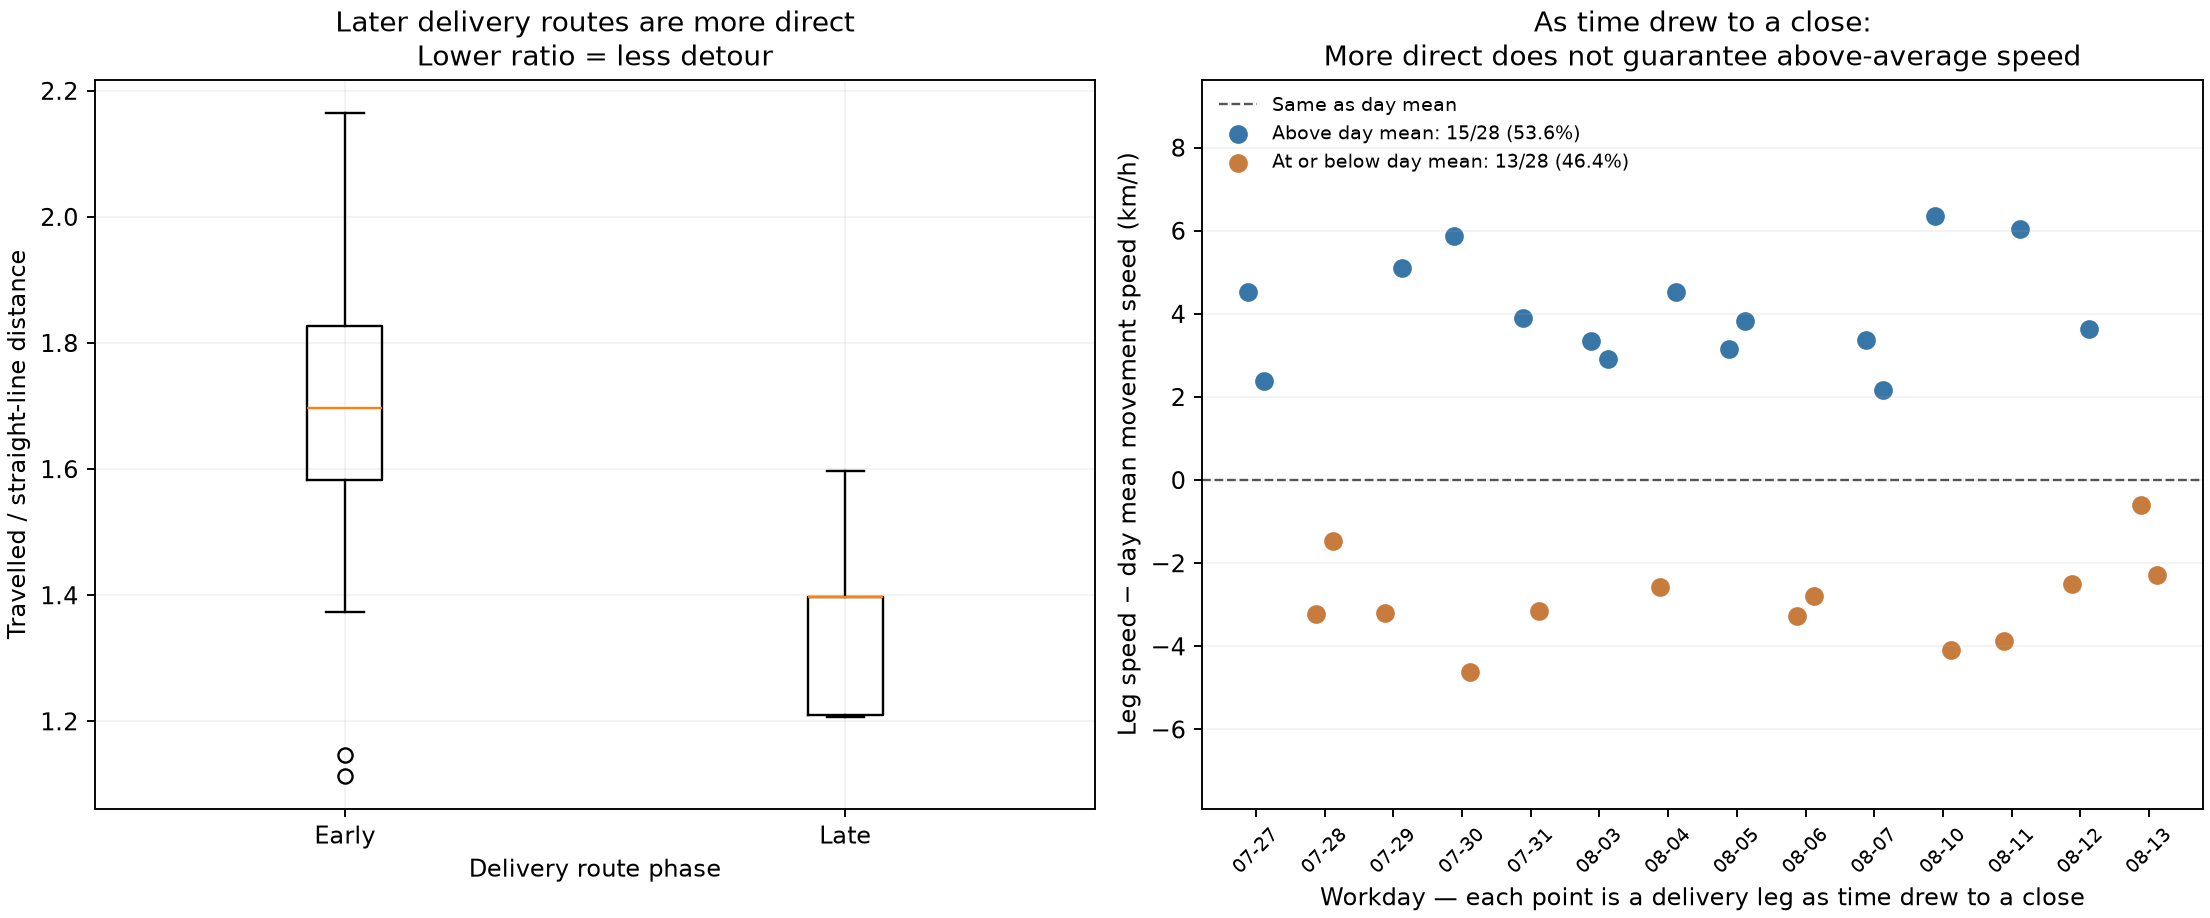

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

legs = pd.read_csv("movement_legs.csv")
visits = pd.read_csv("aoi_visits.csv")
extra = {}
extra["receipt_events"] = pd.read_csv("receipt_events.csv")
extra["aois"] = pd.read_csv("aois.csv")


def evidence(case, index, df, user_df, legs, visits, extra):
    import json
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)
    moving = user_df[user_df.activity_state.eq("travelling")].copy()
    done = df[df.status.eq("completed")].copy()
    value = {}
    if case == 21:
        order = ["primary", "secondary", "tertiary", "residential"]
        moving = moving.merge(
            legs[["leg_id", "period"]], on="leg_id", validate="many_to_one"
        )
        if index == 1:
            summary = (
                moving.groupby("fclass")[["step_distance_km", "step_duration_s"]]
                .sum()
                .reindex(order)
            )
            summary["movement_speed_kmh"] = (
                summary.step_distance_km / summary.step_duration_s * 3600
            )
            summary["completions"] = done.delivery_fclass.value_counts().reindex(
                order, fill_value=0
            )
            summary["completions_per_km"] = (
                summary.completions / summary.step_distance_km
            )
            ax.bar(
                order,
                summary.movement_speed_kmh,
                color="#5c8ea7",
                alpha=0.8,
                label="Movement speed",
            )
            twin = ax.twinx()
            twin.plot(order, summary.completions_per_km, "o-", color="#bd7843")
            ax.set(ylabel="Distance / moving time (km/h)", xlabel="Native OSM fclass")
            twin.set_ylabel("Delivery completions per travelled km", color="#bd7843")
            value = {"road_class_summary": summary.to_dict("index")}
        elif index == 2:
            summary = (
                moving.groupby(["period", "fclass"])
                .step_distance_km.sum()
                .unstack(fill_value=0)
            )
            summary = summary.div(summary.sum(axis=1), axis=0).reindex(
                ["early", "late"]
            )
            summary[order].plot.bar(stacked=True, ax=ax, rot=0)
            ax.set(
                ylabel="Share of all moving distance",
                xlabel="First / second half of scheduled delivery stops",
            )
            tasks = done.merge(
                legs[["leg_id", "period"]], left_on="arrival_leg_id", right_on="leg_id"
            )
            value = {
                "distance_shares": summary.to_dict("index"),
                "completion_counts": tasks.period.value_counts().to_dict(),
            }
        else:
            # Smooth spatial AND temporal event kernel, independently measured
            # from task-completion positions/times rather than a generator label.
            frames = []
            for tid, q in moving.groupby("trajectory_id"):
                t = done[done.trajectory_id.eq(tid)]
                x = q[["lng", "lat"]].to_numpy() * [95.2, 111]
                y = t[["delivery_lng", "delivery_lat"]].to_numpy() * [95.2, 111]
                ds = np.linalg.norm(x[:, None] - y[None, :], axis=2)
                a = (
                    pd.to_datetime(q.gps_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                b = (
                    pd.to_datetime(t.completion_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                dt = abs(a[:, None] - b[None, :]) / 6e10
                q = q.copy()
                q["nearby_activity"] = (np.exp(-ds / 0.30) * np.exp(-dt / 30)).sum(
                    axis=1
                )
                frames.append(q)
            points = pd.concat(frames)
            values = {}
            for cls in order:
                q = points[points.fclass.eq(cls)]
                bins = pd.qcut(q.nearby_activity, 5, duplicates="drop")
                med = q.groupby(bins, observed=True)[
                    ["nearby_activity", "speed_kmh"]
                ].median()
                line = ax.plot(med.nearby_activity, med.speed_kmh, "o-", label=cls)[0]
                sample = q.sample(min(350, len(q)), random_state=17)
                ax.scatter(
                    sample.nearby_activity,
                    sample.speed_kmh,
                    s=6,
                    alpha=0.10,
                    color=line.get_color(),
                )
                values[cls] = {
                    "points": len(q),
                    "spearman": q.nearby_activity.corr(q.speed_kmh, method="spearman"),
                    "low_to_high_activity_speed_drop_kmh": (
                        med.speed_kmh.iloc[0] - med.speed_kmh.iloc[-1]
                    ),
                    "quintile_medians": med.to_dict("list"),
                }
            ax.set(
                xlabel=(
                    "Nearby completion intensity (300 m / 30 min exponential kernel)"
                ),
                ylabel="Median moving speed (km/h)",
            )
            ax.legend()
            value = {"within_class_evidence": values}
    elif case == 22:
        if index == 1:
            counts = (
                done.groupby(["service_date", "aoi_id"]).size().unstack(fill_value=0)
            )
            span = user_df.groupby("trajectory_id").gps_time.agg(["min", "max"])
            duration = (
                pd.to_datetime(span["max"], format="mixed")
                - pd.to_datetime(span["min"], format="mixed")
            ).dt.total_seconds()
            shares = (
                visits.groupby(["trajectory_id", "aoi_id"])
                .duration_s.sum()
                .unstack(fill_value=0)
                .div(duration, axis=0)
            )
            summary = pd.DataFrame(
                {
                    "mean_deliveries_per_day": counts.mean(),
                    "mean_work_time_share": shares.mean(),
                }
            )
            summary.plot.bar(
                y="mean_deliveries_per_day", ax=ax, rot=0, legend=False, color="#608ea4"
            )
            ax.set(
                ylabel="Completed deliveries per observed day", xlabel="Constructed AOI"
            )
            twin = ax.twinx()
            twin.plot(
                np.arange(len(summary)),
                summary.mean_work_time_share * 100,
                "o-",
                color="#bd7843",
            )
            twin.set_ylabel("Mean observed workday time (%)")
            value = {
                "aoi_summary": summary.to_dict("index"),
                "observed_days": counts.shape[0],
                "regular_destination_fclasses": sorted(
                    done[done.regular_aoi.eq("yes")].delivery_fclass.unique().tolist()
                ),
                "fixed_receipt_sites": (
                    extra["receipt_events"]
                    .groupby("aoi_id")[["lng", "lat"]]
                    .nunique()
                    .to_dict("index")
                ),
            }
        elif index == 2:
            q = legs[legs.purpose.eq("delivery")]
            plt.close(fig)
            fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), constrained_layout=True)
            ax = axes[0]
            ax.boxplot(
                [q[q.period.eq(p)].route_directness_ratio for p in ["early", "late"]],
                tick_labels=["Early", "Late"],
            )
            ax.set(
                xlabel="Delivery route phase",
                ylabel="Travelled / straight-line distance",
                title=(
                    "Later delivery routes are more direct\nLower ratio = less detour"
                ),
            )
            dates = sorted(q.service_date.unique())
            totals = moving.groupby("service_date")[
                ["step_distance_km", "step_duration_s"]
            ].sum()
            baseline = totals.step_distance_km / totals.step_duration_s * 3600
            late = q[q.period.eq("late")].copy()
            late["day_mean_movement_speed_kmh"] = late.service_date.map(baseline)
            late["difference_from_day_mean_kmh"] = (
                late.mean_speed_kmh - late.day_mean_movement_speed_kmh
            )
            above = late.difference_from_day_mean_kmh.gt(0)
            x = late.service_date.map({day: i for i, day in enumerate(dates)}).to_numpy(
                dtype=float
            )
            x += np.where(late.groupby("service_date").cumcount().eq(0), -0.12, 0.12)
            axes[1].axhline(
                0,
                color="#555555",
                linewidth=1,
                linestyle="--",
                label="Same as day mean",
            )
            for mask, color, label in [
                (above, "#3976a8", "Above day mean"),
                (~above, "#c77c3d", "At or below day mean"),
            ]:
                axes[1].scatter(
                    x[mask],
                    late.loc[mask, "difference_from_day_mean_kmh"],
                    color=color,
                    s=48,
                    label=f"{label}: {int(mask.sum())}/{len(late)} ({mask.mean():.1%})",
                )
            axes[1].set(
                xticks=np.arange(len(dates)),
                xticklabels=[day[5:] for day in dates],
                xlabel="Workday — each point is a delivery leg as time drew to a close",
                ylabel="Leg speed − day mean movement speed (km/h)",
                title=(
                    "As time drew to a close:\nMore direct does not guarantee"
                    " above-average speed"
                ),
            )
            axes[1].margins(y=0.30)
            axes[1].tick_params(axis="x", rotation=45, labelsize=8)
            axes[1].legend(loc="upper left", fontsize=8, frameon=False)
            axes[1].grid(axis="y", alpha=0.15)
            value = {
                "period_means": (
                    q.groupby("period")[["route_directness_ratio", "mean_speed_kmh"]]
                    .mean()
                    .to_dict("index")
                ),
                "day_mean_definition": (
                    "All moving GPS distance / all moving GPS time, including return"
                    " legs and excluding stops"
                ),
                "daily_mean_movement_speed_kmh": baseline.to_dict(),
                "late_delivery_legs": len(late),
                "late_legs_above_day_mean": int(above.sum()),
                "late_share_above_day_mean": float(above.mean()),
                "late_leg_comparison": (
                    late[
                        [
                            "leg_id",
                            "service_date",
                            "mean_speed_kmh",
                            "day_mean_movement_speed_kmh",
                            "difference_from_day_mean_kmh",
                        ]
                    ].to_dict("records")
                ),
            }
        elif index == 3:
            q = done.copy()
            stamp = pd.to_datetime(q.completion_time, format="mixed")
            q["completion_hour"] = (
                stamp.dt.hour + stamp.dt.minute / 60 + stamp.dt.second / 3600
            )
            q["window_hours"] = (
                pd.to_datetime(q.time_window_end) - pd.to_datetime(q.time_window_start)
            ).dt.total_seconds() / 3600
            plt.close(fig)
            fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5), constrained_layout=True)
            ax = axes[0]
            groups = [
                q[q.regular_aoi.eq("no") & q.window_hours.lt(9)],
                q[q.regular_aoi.eq("no") & q.window_hours.ge(9)],
                q[q.regular_aoi.eq("yes") & q.window_hours.ge(9)],
            ]
            labels = [
                "Non-regular AOIs\nWindow <9 h",
                "Non-regular AOIs\nWindow ≥9 h",
                "Regular AOIs (A/B)\nWindow ≥9 h",
            ]
            colors = ["#4f846c", "#3976a8", "#c77c3d"]
            boxes = ax.boxplot(
                [g.completion_hour for g in groups],
                tick_labels=labels,
                patch_artist=True,
            )
            for box, color in zip(boxes["boxes"], colors):
                box.set_facecolor(color)
                box.set_alpha(0.45)
            for i, g in enumerate(groups, 1):
                median = g.completion_hour.median()
                h = int(median)
                minute = int(round((median - h) * 60))
                ax.text(
                    i,
                    17.8,
                    f"n={len(g)}\nMedian {h:02}:{minute:02}",
                    ha="center",
                    fontsize=9,
                )
            ax.set(
                ylabel="Task completion time (Shanghai)",
                title="Both non-regular window groups finish earlier",
                ylim=(7.5, 18.5),
            )
            ax.yaxis.set_major_formatter(lambda v, _: f"{int(v):02}:00")
            ax.tick_params(axis="x", labelsize=8)
            for g, label, color, marker in zip(groups, labels, colors, ["o", "s", "^"]):
                axes[1].scatter(
                    g.window_hours,
                    g.completion_hour,
                    s=16,
                    alpha=0.45,
                    color=color,
                    marker=marker,
                    label=label.replace("\n", "; "),
                )
            axes[1].set(
                xlabel="Service-window duration (hours)",
                ylabel="Task completion time (Shanghai)",
                title="Wide windows alone do not explain later completion",
                ylim=(7.5, 19.5),
            )
            axes[1].yaxis.set_major_formatter(lambda v, _: f"{int(v):02}:00")
            axes[1].legend(loc="upper left", fontsize=8, frameon=False)
            axes[1].grid(alpha=0.15)
            nvisits = visits.groupby(["service_date", "aoi_id"]).size()
            value = {
                "group_medians": (
                    q.groupby("regular_aoi")[["completion_hour", "window_hours"]]
                    .median()
                    .to_dict("index")
                ),
                "regular_aoi_visits_per_day": (
                    nvisits.unstack(fill_value=0)[["A", "B"]].to_dict("list")
                ),
                "irregular_by_window_median_hour": (
                    q[q.regular_aoi.eq("no")]
                    .assign(
                        window_group=lambda d: np.where(
                            d.window_hours < 9, "Narrower (<9h)", "Wide (9h+)"
                        )
                    )
                    .groupby("window_group")
                    .completion_hour.median()
                    .to_dict()
                ),
                "plotted_groups": {
                    label.replace("\n", "; "): {
                        "tasks": len(g),
                        "median_completion_hour": float(g.completion_hour.median()),
                        "window_hours_min": float(g.window_hours.min()),
                        "window_hours_max": float(g.window_hours.max()),
                    }
                    for label, g in zip(labels, groups)
                },
                "uncompleted_tasks_excluded": int(df.status.ne("completed").sum()),
            }
        else:
            irregular = df[df.regular_aoi.eq("no")]
            summary = (
                irregular.groupby(["service_date", "status"])
                .size()
                .unstack(fill_value=0)
            )
            summary.plot.bar(stacked=True, ax=ax, rot=50)
            ax.set(ylabel="Available irregular-AOI tasks", xlabel="Workday")
            pending = irregular[irregular.status.eq("pending")]
            dates = pending.service_date.unique().tolist()
            min_dist = {}
            for day in dates:
                gps = user_df[user_df.service_date.eq(day)]
                destinations = pending[pending.service_date.eq(day)][
                    ["aoi_id", "delivery_lng", "delivery_lat"]
                ].drop_duplicates()
                for r in destinations.itertuples():
                    ds = np.linalg.norm(
                        (
                            gps[["lng", "lat"]].to_numpy()
                            - [r.delivery_lng, r.delivery_lat]
                        )
                        * [95200, 111000],
                        axis=1,
                    )
                    min_dist[r.aoi_id] = float(ds.min())
            value = {
                "pending_dates": dates,
                "pending_tasks": len(pending),
                "minimum_GPS_distance_to_unvisited_AOI_m": min_dist,
                "anomaly_day_irregular_visit_count": int(
                    len(
                        visits[
                            visits.service_date.isin(dates)
                            & ~visits.aoi_id.isin(["A", "B"])
                        ]
                    )
                ),
            }
    elif case == 23:
        q = legs[legs.purpose.eq("delivery")].copy()
        # Initial departure is not between two completed task locations.
        q = q[q.groupby("trajectory_id").cumcount().gt(0)]
        if index == 1:
            q = q[q.period.ne("exception") & q.separation_km.between(0.7, 1.4)]
            q["oneway_group"] = np.where(
                q.oneway_share >= 0.55,
                "High (55%+)",
                np.where(q.oneway_share <= 0.25, "Low (0–25%)", "Middle"),
            )
            q = q[q.oneway_group.ne("Middle")]
            for name, s in q.groupby("oneway_group"):
                ax.scatter(
                    s.separation_km, s.route_directness_ratio, label=name, alpha=0.6
                )
            ax.set(
                xlabel="Task endpoint separation (km)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "matched_separation_range_km": [0.7, 1.4],
                "group_means": (
                    q.groupby("oneway_group")[
                        ["separation_km", "route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "within_period_group_means": (
                    q.groupby(["period", "oneway_group"])[
                        ["route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .reset_index()
                    .to_dict("records")
                ),
            }
        elif index == 2:
            means = (
                q[q.period.ne("exception")]
                .groupby("period")[["mean_speed_kmh", "route_directness_ratio"]]
                .mean()
                .reindex(["early", "midday", "late"])
            )
            ax.plot(means.index, means.mean_speed_kmh, "o-", color="#608ea4")
            ax.set_ylabel("Mean leg speed (km/h)")
            twin = ax.twinx()
            twin.plot(means.index, means.route_directness_ratio, "s-", color="#bd7843")
            twin.set_ylabel("Mean route directness ratio")
            value = {"period_means": means.to_dict("index")}
        elif index == 3:
            p = (
                q[q.period.ne("exception")]
                .groupby(["service_date", "period"])
                .agg(
                    detour_sd=("route_directness_ratio", "std"),
                    speed_sd=("mean_speed_kmh", "std"),
                    transitions=("fclass_transitions", "sum"),
                    distance=("distance_km", "sum"),
                )
            )
            p["transitions_per_km"] = p.transitions / p.distance
            ax.scatter(
                p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap="viridis", s=50
            )
            fig.colorbar(ax.collections[0], ax=ax, label="Across-leg speed SD (km/h)")
            ax.set(
                xlabel="Native fclass transitions per travelled km",
                ylabel="Within-period route-ratio SD",
            )
            cut = p.transitions_per_km.median()
            p["transition_group"] = np.where(
                p.transitions_per_km > cut, "Frequent", "Less frequent"
            )
            value = {
                "correlation_transition_frequency_detour_sd": p.transitions_per_km.corr(
                    p.detour_sd
                ),
                "group_means": (
                    p.groupby("transition_group")[
                        ["detour_sd", "speed_sd", "transitions_per_km"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "period_count": len(p),
            }
        else:
            normal = q[q.period.ne("exception")]
            exception = q[q.period.eq("exception")]
            ax.scatter(
                normal.oneway_share * 100,
                normal.route_directness_ratio,
                alpha=0.4,
                label="Other task legs",
            )
            ax.scatter(
                exception.oneway_share * 100,
                exception.route_directness_ratio,
                marker="*",
                s=220,
                color="#c66643",
                label="Exceptional period",
            )
            ax.set(
                xlabel="One-way-road distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "exception": (
                    exception[
                        [
                            "leg_id",
                            "route_directness_ratio",
                            "oneway_share",
                            "mean_speed_kmh",
                            "distance_km",
                            "separation_km",
                        ]
                    ].to_dict("records")
                ),
                "normal_speed_10_90_percentiles": (
                    normal.mean_speed_kmh.quantile([0.1, 0.9]).tolist()
                ),
                "schema_oneway_unit_assumption": (
                    "2.01 interpreted provisionally as percent, pending user"
                    " confirmation"
                ),
            }
    elif case == 24:
        if index == 1:
            q = legs[legs.purpose.str.startswith("road_condition")]
            q.boxplot(column="speed_std_kmh", by="purpose", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Road condition",
                ylabel="Short-term GPS speed SD (km/h)",
                title="Stable residential travel versus alternating road classes",
            )
            value = {
                "condition_means": (
                    q.groupby("purpose")[
                        [
                            "speed_std_kmh",
                            "residential_share",
                            "tertiary_share",
                            "fclass_transitions",
                        ]
                    ]
                    .mean()
                    .to_dict("index")
                )
            }
        else:
            q = extra["crossings"].merge(
                legs,
                left_on="crossing_leg_id",
                right_on="leg_id",
                validate="one_to_one",
            )
            low = moving[moving.speed_kmh < 12].groupby("leg_id").step_duration_s.sum()
            q["low_speed_seconds"] = q.leg_id.map(low).fillna(0)
            approach = legs.set_index("leg_id").mean_speed_kmh
            q["speed_drop_kmh"] = q.approach_leg_id.map(approach) - q.mean_speed_kmh
            if index == 2:
                q.boxplot(
                    column="low_speed_seconds", by=["structure_type", "period"], ax=ax
                )
                fig.suptitle("")
                ax.set(
                    xlabel="Same mapped structure / workday phase",
                    ylabel="Time below 12 km/h (seconds)",
                    title="Repeated early and late crossings",
                )
                value = {
                    "structure_period_means": (
                        q.groupby(["structure_osm_way_id", "structure_type", "period"])[
                            ["low_speed_seconds", "speed_std_kmh", "mean_speed_kmh"]
                        ]
                        .mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                    "crossings": len(q),
                    "unique_structures": q.structure_osm_way_id.nunique(),
                }
            else:
                q.boxplot(column="speed_drop_kmh", by="approach_fclass", ax=ax)
                fig.suptitle("")
                ax.set(
                    xlabel="Dominant road class in last 800 m before structure",
                    ylabel="Approach minus crossing speed (km/h)",
                    title="Road approach conditions and crossing slowdowns",
                )
                value = {
                    "approach_means": (
                        q.groupby("approach_fclass")[
                            ["speed_drop_kmh", "approach_dominant_share"]
                        ]
                        .mean()
                        .to_dict("index")
                    ),
                    "within_structure_period_means": (
                        q.groupby(["structure_osm_way_id", "period", "approach_fclass"])
                        .speed_drop_kmh.mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                }
    elif case == 25:
        if index == 1:
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=0.5
                )
            ax.set(
                xlabel="Travelled / straight-line distance",
                ylabel="Leg movement speed (km/h)",
            )
            ax.legend()
            summary = legs.groupby("region_id")[
                ["route_directness_ratio", "mean_speed_kmh"]
            ].mean()
            summary["delivery_volume"] = done.groupby("region_id").size()
            value = {
                "region_means": summary.to_dict("index"),
                "region_role_mapping": (
                    extra["regions"][["region_id", "comparison_role"]].to_dict(
                        "records"
                    )
                ),
            }
        elif index == 2:
            summary = legs.groupby(["region_id", "period"])[
                ["route_directness_ratio", "primary_share", "residential_share"]
            ].mean()
            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)
            ax.set(
                ylabel="Mean travelled / straight-line distance",
                xlabel="Constructed service region",
            )
            value = {"region_period_means": summary.reset_index().to_dict("records")}
        else:
            values = {}
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.oneway_share * 100,
                    q.route_directness_ratio,
                    label=name,
                    alpha=0.5,
                )
                values[name] = {
                    "pearson": q.oneway_share.corr(q.route_directness_ratio),
                    "spearman": q.oneway_share.corr(
                        q.route_directness_ratio, method="spearman"
                    ),
                    "legs": len(q),
                    "oneway_share_unique_values": q.oneway_share.nunique(),
                    "route_ratio_unique_values": q.route_directness_ratio.nunique(),
                }
            ax.set(
                xlabel="One-way-road share of travelled distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {"within_region_associations": values}
    ax.grid(alpha=0.15)
    return json.loads(json.dumps(value, default=lambda x: x.item()))


evidence_value = evidence(22, 2, df, user_df, legs, visits, extra)
print(evidence_value)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "road_backed_evidence_2",
  "insight_type": "temporal_dynamics",
  "insight": "As time drew to a close, the courier tends to choose direct routes to task locations, but not guarantee the higher speed in the day.",
  "insight_value": {
    "period_means": {
      "early": {
        "route_directness_ratio": 1.702683041764458,
        "mean_speed_kmh": 21.512486211666552
      },
      "late": {
        "route_directness_ratio": 1.3375761962845796,
        "mean_speed_kmh": 21.60685757758677
      }
    },
    "day_mean_definition": "All moving GPS distance / all moving GPS time, including return legs and excluding stops",
    "daily_mean_movement_speed_kmh": {
      "2026-07-27": 20.146588555389584,
      "2026-07-28": 21.142029255362036,
      "2026-07-29": 20.620823113395705,
      "2026-07-30": 21.28320899782128,
      "2026-07-31": 19.869383580380585,
      "2026-08-03": 20.81617445332614,
      "2026-08-04": 21.155123162325214,
      "2026-08-05": 20.96186590378553,
      "2026-08-06": 19.876265305324228,
      "2026-08-07": 19.74396221561094,
      "2026-08-10": 22.19851790400305,
      "2026-08-11": 21.49559711830252,
      "2026-08-12": 21.59668561627209,
      "2026-08-13": 19.86510905899246
    },
    "late_delivery_legs": 28,
    "late_legs_above_day_mean": 15,
    "late_share_above_day_mean": 0.5357142857142857,
    "late_leg_comparison": [
      {
        "leg_id": "L22_Shanghai_Puxi_20260727_courier_01_M005",
        "service_date": "2026-07-27",
        "mean_speed_kmh": 24.66761250330273,
        "day_mean_movement_speed_kmh": 20.146588555389584,
        "difference_from_day_mean_kmh": 4.521023947913147
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260727_courier_01_M006",
        "service_date": "2026-07-27",
        "mean_speed_kmh": 22.535397714655517,
        "day_mean_movement_speed_kmh": 20.146588555389584,
        "difference_from_day_mean_kmh": 2.388809159265932
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260728_courier_01_M005",
        "service_date": "2026-07-28",
        "mean_speed_kmh": 17.931765576104088,
        "day_mean_movement_speed_kmh": 21.142029255362036,
        "difference_from_day_mean_kmh": -3.210263679257949
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260728_courier_01_M006",
        "service_date": "2026-07-28",
        "mean_speed_kmh": 19.67258334507241,
        "day_mean_movement_speed_kmh": 21.142029255362036,
        "difference_from_day_mean_kmh": -1.4694459102896253
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260729_courier_01_M005",
        "service_date": "2026-07-29",
        "mean_speed_kmh": 17.427832089432467,
        "day_mean_movement_speed_kmh": 20.620823113395705,
        "difference_from_day_mean_kmh": -3.1929910239632378
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260729_courier_01_M006",
        "service_date": "2026-07-29",
        "mean_speed_kmh": 25.714832761614407,
        "day_mean_movement_speed_kmh": 20.620823113395705,
        "difference_from_day_mean_kmh": 5.094009648218702
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260730_courier_01_M005",
        "service_date": "2026-07-30",
        "mean_speed_kmh": 27.15468304418545,
        "day_mean_movement_speed_kmh": 21.28320899782128,
        "difference_from_day_mean_kmh": 5.87147404636417
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260730_courier_01_M006",
        "service_date": "2026-07-30",
        "mean_speed_kmh": 16.65920908947808,
        "day_mean_movement_speed_kmh": 21.28320899782128,
        "difference_from_day_mean_kmh": -4.623999908343201
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260731_courier_01_M005",
        "service_date": "2026-07-31",
        "mean_speed_kmh": 23.76232655447966,
        "day_mean_movement_speed_kmh": 19.869383580380585,
        "difference_from_day_mean_kmh": 3.892942974099075
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260731_courier_01_M006",
        "service_date": "2026-07-31",
        "mean_speed_kmh": 16.715326647968617,
        "day_mean_movement_speed_kmh": 19.869383580380585,
        "difference_from_day_mean_kmh": -3.1540569324119687
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260803_courier_01_M005",
        "service_date": "2026-08-03",
        "mean_speed_kmh": 24.16324452742389,
        "day_mean_movement_speed_kmh": 20.81617445332614,
        "difference_from_day_mean_kmh": 3.347070074097747
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260803_courier_01_M006",
        "service_date": "2026-08-03",
        "mean_speed_kmh": 23.734136422334306,
        "day_mean_movement_speed_kmh": 20.81617445332614,
        "difference_from_day_mean_kmh": 2.9179619690081644
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260804_courier_01_M005",
        "service_date": "2026-08-04",
        "mean_speed_kmh": 18.59082238429651,
        "day_mean_movement_speed_kmh": 21.155123162325214,
        "difference_from_day_mean_kmh": -2.5643007780287057
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260804_courier_01_M006",
        "service_date": "2026-08-04",
        "mean_speed_kmh": 25.673968863645797,
        "day_mean_movement_speed_kmh": 21.155123162325214,
        "difference_from_day_mean_kmh": 4.518845701320583
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260805_courier_01_M005",
        "service_date": "2026-08-05",
        "mean_speed_kmh": 24.1243298111348,
        "day_mean_movement_speed_kmh": 20.96186590378553,
        "difference_from_day_mean_kmh": 3.16246390734927
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260805_courier_01_M006",
        "service_date": "2026-08-05",
        "mean_speed_kmh": 24.786242099192386,
        "day_mean_movement_speed_kmh": 20.96186590378553,
        "difference_from_day_mean_kmh": 3.824376195406856
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260806_courier_01_M003",
        "service_date": "2026-08-06",
        "mean_speed_kmh": 16.60064600170206,
        "day_mean_movement_speed_kmh": 19.876265305324228,
        "difference_from_day_mean_kmh": -3.275619303622168
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260806_courier_01_M004",
        "service_date": "2026-08-06",
        "mean_speed_kmh": 17.083239395293845,
        "day_mean_movement_speed_kmh": 19.876265305324228,
        "difference_from_day_mean_kmh": -2.7930259100303836
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260807_courier_01_M005",
        "service_date": "2026-08-07",
        "mean_speed_kmh": 23.113017531607927,
        "day_mean_movement_speed_kmh": 19.74396221561094,
        "difference_from_day_mean_kmh": 3.369055315996988
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260807_courier_01_M006",
        "service_date": "2026-08-07",
        "mean_speed_kmh": 21.915100046620186,
        "day_mean_movement_speed_kmh": 19.74396221561094,
        "difference_from_day_mean_kmh": 2.171137831009247
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260810_courier_01_M005",
        "service_date": "2026-08-10",
        "mean_speed_kmh": 28.54438614181963,
        "day_mean_movement_speed_kmh": 22.19851790400305,
        "difference_from_day_mean_kmh": 6.345868237816578
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260810_courier_01_M006",
        "service_date": "2026-08-10",
        "mean_speed_kmh": 18.09868879250753,
        "day_mean_movement_speed_kmh": 22.19851790400305,
        "difference_from_day_mean_kmh": -4.09982911149552
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260811_courier_01_M005",
        "service_date": "2026-08-11",
        "mean_speed_kmh": 17.6304007832325,
        "day_mean_movement_speed_kmh": 21.49559711830252,
        "difference_from_day_mean_kmh": -3.8651963350700207
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260811_courier_01_M006",
        "service_date": "2026-08-11",
        "mean_speed_kmh": 27.53357525297417,
        "day_mean_movement_speed_kmh": 21.49559711830252,
        "difference_from_day_mean_kmh": 6.037978134671651
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260812_courier_01_M005",
        "service_date": "2026-08-12",
        "mean_speed_kmh": 19.091080582536502,
        "day_mean_movement_speed_kmh": 21.59668561627209,
        "difference_from_day_mean_kmh": -2.5056050337355877
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260812_courier_01_M006",
        "service_date": "2026-08-12",
        "mean_speed_kmh": 25.22398821622507,
        "day_mean_movement_speed_kmh": 21.59668561627209,
        "difference_from_day_mean_kmh": 3.62730259995298
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260813_courier_01_M005",
        "service_date": "2026-08-13",
        "mean_speed_kmh": 19.25401692142436,
        "day_mean_movement_speed_kmh": 19.86510905899246,
        "difference_from_day_mean_kmh": -0.6110921375681002
      },
      {
        "leg_id": "L22_Shanghai_Puxi_20260813_courier_01_M006",
        "service_date": "2026-08-13",
        "mean_speed_kmh": 17.589559072164658,
        "day_mean_movement_speed_kmh": 19.86510905899246,
        "difference_from_day_mean_kmh": -2.2755499868278015
      }
    ]
  },
  "question": "Do later delivery routes become more direct without guaranteeing speed above the day mean?",
  "actionable_insight": "Interpret the constructed descriptive association, not an estimated causal effect.",
  "plot": {
    "plot_type": "route_ratio_and_above_day_mean_speed_panels",
    "title": "LaDe 22 insight 2",
    "file": "visualizations/insight_2.png",
    "description": "Left compares early/late delivery route ratios; right shows every delivery leg as time drew to a close (the late route phase), with its day mean subtracted from its speed. The day mean is total moving GPS distance / total moving GPS time, including return and excluding stops. Higher means above this mean, not the maximum. Positive and non-positive observations are both shown; the observed share is not an estimated probability."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nlegs = pd.read_csv(\"movement_legs.csv\")\nvisits = pd.read_csv(\"aoi_visits.csv\")\nextra = {}\nextra[\"receipt_events\"] = pd.read_csv(\"receipt_events.csv\")\nextra[\"aois\"] = pd.read_csv(\"aois.csv\")\n\ndef evidence(case, index, df, user_df, legs, visits, extra):\n    import json\n    import numpy as np\n    import pandas as pd\n    import matplotlib.pyplot as plt\n\n    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)\n    moving = user_df[user_df.activity_state.eq('travelling')].copy()\n    done = df[df.status.eq('completed')].copy()\n    value = {}\n    if case == 21:\n        order = ['primary', 'secondary', 'tertiary', 'residential']\n        moving = moving.merge(legs[['leg_id', 'period']], on='leg_id', validate='many_to_one')\n        if index == 1:\n            summary = moving.groupby('fclass')[['step_distance_km', 'step_duration_s']].sum().reindex(order)\n            summary['movement_speed_kmh'] = summary.step_distance_km/summary.step_duration_s*3600\n            summary['completions'] = done.delivery_fclass.value_counts().reindex(order, fill_value=0)\n            summary['completions_per_km'] = summary.completions/summary.step_distance_km\n            ax.bar(order, summary.movement_speed_kmh, color='#5c8ea7', alpha=.8, label='Movement speed')\n            twin = ax.twinx(); twin.plot(order, summary.completions_per_km, 'o-', color='#bd7843')\n            ax.set(ylabel='Distance / moving time (km/h)', xlabel='Native OSM fclass')\n            twin.set_ylabel('Delivery completions per travelled km', color='#bd7843')\n            value = {'road_class_summary': summary.to_dict('index')}\n        elif index == 2:\n            summary = moving.groupby(['period', 'fclass']).step_distance_km.sum().unstack(fill_value=0)\n            summary = summary.div(summary.sum(axis=1), axis=0).reindex(['early', 'late'])\n            summary[order].plot.bar(stacked=True, ax=ax, rot=0)\n            ax.set(ylabel='Share of all moving distance', xlabel='First / second half of scheduled delivery stops')\n            tasks = done.merge(legs[['leg_id', 'period']], left_on='arrival_leg_id', right_on='leg_id')\n            value = {'distance_shares': summary.to_dict('index'), 'completion_counts': tasks.period.value_counts().to_dict()}\n        else:\n            # Smooth spatial AND temporal event kernel, independently measured\n            # from task-completion positions/times rather than a generator label.\n            frames = []\n            for tid, q in moving.groupby('trajectory_id'):\n                t = done[done.trajectory_id.eq(tid)]\n                x = q[['lng', 'lat']].to_numpy()*[95.2, 111]\n                y = t[['delivery_lng', 'delivery_lat']].to_numpy()*[95.2, 111]\n                ds = np.linalg.norm(x[:, None]-y[None, :], axis=2)\n                a = pd.to_datetime(q.gps_time, format='mixed').astype('int64').to_numpy()\n                b = pd.to_datetime(t.completion_time, format='mixed').astype('int64').to_numpy()\n                dt = abs(a[:, None]-b[None, :])/6e10\n                q = q.copy(); q['nearby_activity'] = (np.exp(-ds/.30)*np.exp(-dt/30)).sum(axis=1)\n                frames.append(q)\n            points = pd.concat(frames); values = {}\n            for cls in order:\n                q = points[points.fclass.eq(cls)]\n                bins = pd.qcut(q.nearby_activity, 5, duplicates='drop')\n                med = q.groupby(bins, observed=True)[['nearby_activity', 'speed_kmh']].median()\n                line = ax.plot(med.nearby_activity, med.speed_kmh, 'o-', label=cls)[0]\n                sample = q.sample(min(350, len(q)), random_state=17)\n                ax.scatter(sample.nearby_activity, sample.speed_kmh, s=6, alpha=.10, color=line.get_color())\n                values[cls] = {'points': len(q), 'spearman': q.nearby_activity.corr(q.speed_kmh, method='spearman'),\n                    'low_to_high_activity_speed_drop_kmh': med.speed_kmh.iloc[0]-med.speed_kmh.iloc[-1],\n                    'quintile_medians': med.to_dict('list')}\n            ax.set(xlabel='Nearby completion intensity (300 m / 30 min exponential kernel)', ylabel='Median moving speed (km/h)'); ax.legend()\n            value = {'within_class_evidence': values}\n    elif case == 22:\n        if index == 1:\n            counts = done.groupby(['service_date', 'aoi_id']).size().unstack(fill_value=0)\n            span = user_df.groupby('trajectory_id').gps_time.agg(['min', 'max'])\n            duration = (pd.to_datetime(span['max'], format='mixed')-pd.to_datetime(span['min'], format='mixed')).dt.total_seconds()\n            shares = visits.groupby(['trajectory_id', 'aoi_id']).duration_s.sum().unstack(fill_value=0).div(duration, axis=0)\n            summary = pd.DataFrame({'mean_deliveries_per_day': counts.mean(), 'mean_work_time_share': shares.mean()})\n            summary.plot.bar(y='mean_deliveries_per_day', ax=ax, rot=0, legend=False, color='#608ea4')\n            ax.set(ylabel='Completed deliveries per observed day', xlabel='Constructed AOI')\n            twin = ax.twinx(); twin.plot(np.arange(len(summary)), summary.mean_work_time_share*100, 'o-', color='#bd7843'); twin.set_ylabel('Mean observed workday time (%)')\n            value = {'aoi_summary': summary.to_dict('index'), 'observed_days': counts.shape[0],\n                'regular_destination_fclasses': sorted(done[done.regular_aoi.eq('yes')].delivery_fclass.unique().tolist()),\n                'fixed_receipt_sites': extra['receipt_events'].groupby('aoi_id')[['lng', 'lat']].nunique().to_dict('index')}\n        elif index == 2:\n            q = legs[legs.purpose.eq('delivery')]\n            plt.close(fig)\n            fig,axes=plt.subplots(1,2,figsize=(13,5.4),constrained_layout=True);ax=axes[0]\n            ax.boxplot([q[q.period.eq(p)].route_directness_ratio for p in ['early','late']],\n                tick_labels=['Early','Late'])\n            ax.set(xlabel='Delivery route phase',ylabel='Travelled / straight-line distance',\n                title='Later delivery routes are more direct\\nLower ratio = less detour')\n            dates=sorted(q.service_date.unique())\n            totals=moving.groupby('service_date')[['step_distance_km','step_duration_s']].sum()\n            baseline=totals.step_distance_km/totals.step_duration_s*3600\n            late=q[q.period.eq('late')].copy()\n            late['day_mean_movement_speed_kmh']=late.service_date.map(baseline)\n            late['difference_from_day_mean_kmh']=late.mean_speed_kmh-late.day_mean_movement_speed_kmh\n            above=late.difference_from_day_mean_kmh.gt(0)\n            x=late.service_date.map({day:i for i,day in enumerate(dates)}).to_numpy(dtype=float)\n            x+=np.where(late.groupby('service_date').cumcount().eq(0),-.12,.12)\n            axes[1].axhline(0,color='#555555',linewidth=1,linestyle='--',label='Same as day mean')\n            for mask,color,label in [(above,'#3976a8','Above day mean'),(~above,'#c77c3d','At or below day mean')]:\n                axes[1].scatter(x[mask],late.loc[mask,'difference_from_day_mean_kmh'],color=color,s=48,\n                    label=f'{label}: {int(mask.sum())}/{len(late)} ({mask.mean():.1%})')\n            axes[1].set(xticks=np.arange(len(dates)),xticklabels=[day[5:] for day in dates],\n                xlabel='Workday — each point is a delivery leg as time drew to a close',ylabel='Leg speed − day mean movement speed (km/h)',\n                title='As time drew to a close:\\nMore direct does not guarantee above-average speed')\n            axes[1].margins(y=.30)\n            axes[1].tick_params(axis='x',rotation=45,labelsize=8)\n            axes[1].legend(loc='upper left',fontsize=8,frameon=False)\n            axes[1].grid(axis='y',alpha=.15)\n            value = {'period_means': q.groupby('period')[['route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'day_mean_definition':'All moving GPS distance / all moving GPS time, including return legs and excluding stops',\n                'daily_mean_movement_speed_kmh':baseline.to_dict(),\n                'late_delivery_legs':len(late),'late_legs_above_day_mean':int(above.sum()),\n                'late_share_above_day_mean':float(above.mean()),\n                'late_leg_comparison':late[['leg_id','service_date','mean_speed_kmh','day_mean_movement_speed_kmh','difference_from_day_mean_kmh']].to_dict('records')}\n        elif index == 3:\n            q = done.copy(); stamp = pd.to_datetime(q.completion_time, format='mixed')\n            q['completion_hour'] = stamp.dt.hour+stamp.dt.minute/60+stamp.dt.second/3600\n            q['window_hours'] = (pd.to_datetime(q.time_window_end)-pd.to_datetime(q.time_window_start)).dt.total_seconds()/3600\n            plt.close(fig)\n            fig,axes=plt.subplots(1,2,figsize=(13.5,5.5),constrained_layout=True);ax=axes[0]\n            groups=[q[q.regular_aoi.eq('no')&q.window_hours.lt(9)],\n                    q[q.regular_aoi.eq('no')&q.window_hours.ge(9)],q[q.regular_aoi.eq('yes')&q.window_hours.ge(9)]]\n            labels=['Non-regular AOIs\\nWindow <9 h','Non-regular AOIs\\nWindow ≥9 h','Regular AOIs (A/B)\\nWindow ≥9 h']\n            colors=['#4f846c','#3976a8','#c77c3d']\n            boxes=ax.boxplot([g.completion_hour for g in groups],tick_labels=labels,patch_artist=True)\n            for box,color in zip(boxes['boxes'],colors):box.set_facecolor(color);box.set_alpha(.45)\n            for i,g in enumerate(groups,1):\n                median=g.completion_hour.median();h=int(median);minute=int(round((median-h)*60))\n                ax.text(i,17.8,f'n={len(g)}\\nMedian {h:02}:{minute:02}',ha='center',fontsize=9)\n            ax.set(ylabel='Task completion time (Shanghai)',title='Both non-regular window groups finish earlier',ylim=(7.5,18.5))\n            ax.yaxis.set_major_formatter(lambda v,_:f'{int(v):02}:00')\n            ax.tick_params(axis='x',labelsize=8)\n            for g,label,color,marker in zip(groups,labels,colors,['o','s','^']):\n                axes[1].scatter(g.window_hours,g.completion_hour,s=16,alpha=.45,\n                    color=color,marker=marker,label=label.replace('\\n','; '))\n            axes[1].set(xlabel='Service-window duration (hours)',ylabel='Task completion time (Shanghai)',\n                title='Wide windows alone do not explain later completion',ylim=(7.5,19.5))\n            axes[1].yaxis.set_major_formatter(lambda v,_:f'{int(v):02}:00')\n            axes[1].legend(loc='upper left',fontsize=8,frameon=False)\n            axes[1].grid(alpha=.15)\n            nvisits = visits.groupby(['service_date', 'aoi_id']).size()\n            value = {'group_medians': q.groupby('regular_aoi')[['completion_hour', 'window_hours']].median().to_dict('index'),\n                'regular_aoi_visits_per_day': nvisits.unstack(fill_value=0)[['A', 'B']].to_dict('list'),\n                'irregular_by_window_median_hour': q[q.regular_aoi.eq('no')].assign(window_group=lambda d: np.where(d.window_hours < 9, 'Narrower (<9h)', 'Wide (9h+)')).groupby('window_group').completion_hour.median().to_dict(),\n                'plotted_groups':{label.replace('\\n','; '):{'tasks':len(g),'median_completion_hour':float(g.completion_hour.median()),\n                    'window_hours_min':float(g.window_hours.min()),'window_hours_max':float(g.window_hours.max())}\n                    for label,g in zip(labels,groups)},\n                'uncompleted_tasks_excluded':int(df.status.ne('completed').sum())}\n        else:\n            irregular = df[df.regular_aoi.eq('no')]\n            summary = irregular.groupby(['service_date', 'status']).size().unstack(fill_value=0)\n            summary.plot.bar(stacked=True, ax=ax, rot=50)\n            ax.set(ylabel='Available irregular-AOI tasks', xlabel='Workday')\n            pending = irregular[irregular.status.eq('pending')]; dates = pending.service_date.unique().tolist()\n            min_dist = {}\n            for day in dates:\n                gps = user_df[user_df.service_date.eq(day)]\n                destinations = pending[pending.service_date.eq(day)][['aoi_id', 'delivery_lng', 'delivery_lat']].drop_duplicates()\n                for r in destinations.itertuples():\n                    ds = np.linalg.norm((gps[['lng', 'lat']].to_numpy()-[r.delivery_lng, r.delivery_lat])*[95200, 111000], axis=1)\n                    min_dist[r.aoi_id] = float(ds.min())\n            value = {'pending_dates': dates, 'pending_tasks': len(pending), 'minimum_GPS_distance_to_unvisited_AOI_m': min_dist,\n                'anomaly_day_irregular_visit_count': int(len(visits[visits.service_date.isin(dates)&~visits.aoi_id.isin(['A', 'B'])]))}\n    elif case == 23:\n        q = legs[legs.purpose.eq('delivery')].copy()\n        # Initial departure is not between two completed task locations.\n        q = q[q.groupby('trajectory_id').cumcount().gt(0)]\n        if index == 1:\n            q = q[q.period.ne('exception')&q.separation_km.between(.7, 1.4)]\n            q['oneway_group'] = np.where(q.oneway_share >= .55, 'High (55%+)', np.where(q.oneway_share <= .25, 'Low (0–25%)', 'Middle'))\n            q = q[q.oneway_group.ne('Middle')]\n            for name, s in q.groupby('oneway_group'): ax.scatter(s.separation_km, s.route_directness_ratio, label=name, alpha=.6)\n            ax.set(xlabel='Task endpoint separation (km)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'matched_separation_range_km': [.7, 1.4], 'group_means': q.groupby('oneway_group')[['separation_km', 'route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'within_period_group_means': q.groupby(['period', 'oneway_group'])[['route_directness_ratio', 'mean_speed_kmh']].mean().reset_index().to_dict('records')}\n        elif index == 2:\n            means = q[q.period.ne('exception')].groupby('period')[['mean_speed_kmh', 'route_directness_ratio']].mean().reindex(['early', 'midday', 'late'])\n            ax.plot(means.index, means.mean_speed_kmh, 'o-', color='#608ea4'); ax.set_ylabel('Mean leg speed (km/h)')\n            twin = ax.twinx(); twin.plot(means.index, means.route_directness_ratio, 's-', color='#bd7843'); twin.set_ylabel('Mean route directness ratio')\n            value = {'period_means': means.to_dict('index')}\n        elif index == 3:\n            p = q[q.period.ne('exception')].groupby(['service_date', 'period']).agg(detour_sd=('route_directness_ratio', 'std'), speed_sd=('mean_speed_kmh', 'std'), transitions=('fclass_transitions', 'sum'), distance=('distance_km', 'sum'))\n            p['transitions_per_km'] = p.transitions/p.distance\n            ax.scatter(p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap='viridis', s=50)\n            fig.colorbar(ax.collections[0], ax=ax, label='Across-leg speed SD (km/h)')\n            ax.set(xlabel='Native fclass transitions per travelled km', ylabel='Within-period route-ratio SD')\n            cut = p.transitions_per_km.median(); p['transition_group'] = np.where(p.transitions_per_km > cut, 'Frequent', 'Less frequent')\n            value = {'correlation_transition_frequency_detour_sd': p.transitions_per_km.corr(p.detour_sd),\n                'group_means': p.groupby('transition_group')[['detour_sd', 'speed_sd', 'transitions_per_km']].mean().to_dict('index'), 'period_count': len(p)}\n        else:\n            normal = q[q.period.ne('exception')]; exception = q[q.period.eq('exception')]\n            ax.scatter(normal.oneway_share*100, normal.route_directness_ratio, alpha=.4, label='Other task legs')\n            ax.scatter(exception.oneway_share*100, exception.route_directness_ratio, marker='*', s=220, color='#c66643', label='Exceptional period')\n            ax.set(xlabel='One-way-road distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'exception': exception[['leg_id', 'route_directness_ratio', 'oneway_share', 'mean_speed_kmh', 'distance_km', 'separation_km']].to_dict('records'),\n                'normal_speed_10_90_percentiles': normal.mean_speed_kmh.quantile([.1, .9]).tolist(),\n                'schema_oneway_unit_assumption': '2.01 interpreted provisionally as percent, pending user confirmation'}\n    elif case == 24:\n        if index == 1:\n            q = legs[legs.purpose.str.startswith('road_condition')]\n            q.boxplot(column='speed_std_kmh', by='purpose', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Road condition', ylabel='Short-term GPS speed SD (km/h)', title='Stable residential travel versus alternating road classes')\n            value = {'condition_means': q.groupby('purpose')[['speed_std_kmh', 'residential_share', 'tertiary_share', 'fclass_transitions']].mean().to_dict('index')}\n        else:\n            q = extra['crossings'].merge(legs, left_on='crossing_leg_id', right_on='leg_id', validate='one_to_one')\n            low = moving[moving.speed_kmh < 12].groupby('leg_id').step_duration_s.sum()\n            q['low_speed_seconds'] = q.leg_id.map(low).fillna(0)\n            approach = legs.set_index('leg_id').mean_speed_kmh\n            q['speed_drop_kmh'] = q.approach_leg_id.map(approach)-q.mean_speed_kmh\n            if index == 2:\n                q.boxplot(column='low_speed_seconds', by=['structure_type', 'period'], ax=ax); fig.suptitle('')\n                ax.set(xlabel='Same mapped structure / workday phase', ylabel='Time below 12 km/h (seconds)', title='Repeated early and late crossings')\n                value = {'structure_period_means': q.groupby(['structure_osm_way_id', 'structure_type', 'period'])[['low_speed_seconds', 'speed_std_kmh', 'mean_speed_kmh']].mean().reset_index().to_dict('records'),\n                    'crossings': len(q), 'unique_structures': q.structure_osm_way_id.nunique()}\n            else:\n                q.boxplot(column='speed_drop_kmh', by='approach_fclass', ax=ax); fig.suptitle('')\n                ax.set(xlabel='Dominant road class in last 800 m before structure', ylabel='Approach minus crossing speed (km/h)', title='Road approach conditions and crossing slowdowns')\n                value = {'approach_means': q.groupby('approach_fclass')[['speed_drop_kmh', 'approach_dominant_share']].mean().to_dict('index'),\n                    'within_structure_period_means': q.groupby(['structure_osm_way_id', 'period', 'approach_fclass']).speed_drop_kmh.mean().reset_index().to_dict('records')}\n    elif case == 25:\n        if index == 1:\n            for name, q in legs.groupby('region_id'): ax.scatter(q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=.5)\n            ax.set(xlabel='Travelled / straight-line distance', ylabel='Leg movement speed (km/h)'); ax.legend()\n            summary = legs.groupby('region_id')[['route_directness_ratio', 'mean_speed_kmh']].mean()\n            summary['delivery_volume'] = done.groupby('region_id').size()\n            value = {'region_means': summary.to_dict('index'), 'region_role_mapping': extra['regions'][['region_id', 'comparison_role']].to_dict('records')}\n        elif index == 2:\n            summary = legs.groupby(['region_id', 'period'])[['route_directness_ratio', 'primary_share', 'residential_share']].mean()\n            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)\n            ax.set(ylabel='Mean travelled / straight-line distance', xlabel='Constructed service region')\n            value = {'region_period_means': summary.reset_index().to_dict('records')}\n        else:\n            values = {}\n            for name, q in legs.groupby('region_id'):\n                ax.scatter(q.oneway_share*100, q.route_directness_ratio, label=name, alpha=.5)\n                values[name] = {'pearson': q.oneway_share.corr(q.route_directness_ratio),\n                    'spearman': q.oneway_share.corr(q.route_directness_ratio, method='spearman'),\n                    'legs': len(q), 'oneway_share_unique_values': q.oneway_share.nunique(),\n                    'route_ratio_unique_values': q.route_directness_ratio.nunique()}\n            ax.set(xlabel='One-way-road share of travelled distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'within_region_associations': values}\n    ax.grid(alpha=.15)\n    return json.loads(json.dumps(value, default=lambda x: x.item()))\n\nevidence_value = evidence(22, 2, df, user_df, legs, visits, extra)\nprint(evidence_value)\nplt.show()",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "completion_time",
    "task_position",
    "gps_time",
    "gps_position",
    "task_id",
    "courier_id"
  ]
}

### **Question 3**: Do both narrower- and wider-window tasks at non-regular AOIs finish earlier than wide-window tasks at regular AOIs?

#### Analysis action

Interpret the constructed descriptive association, not an estimated causal effect.

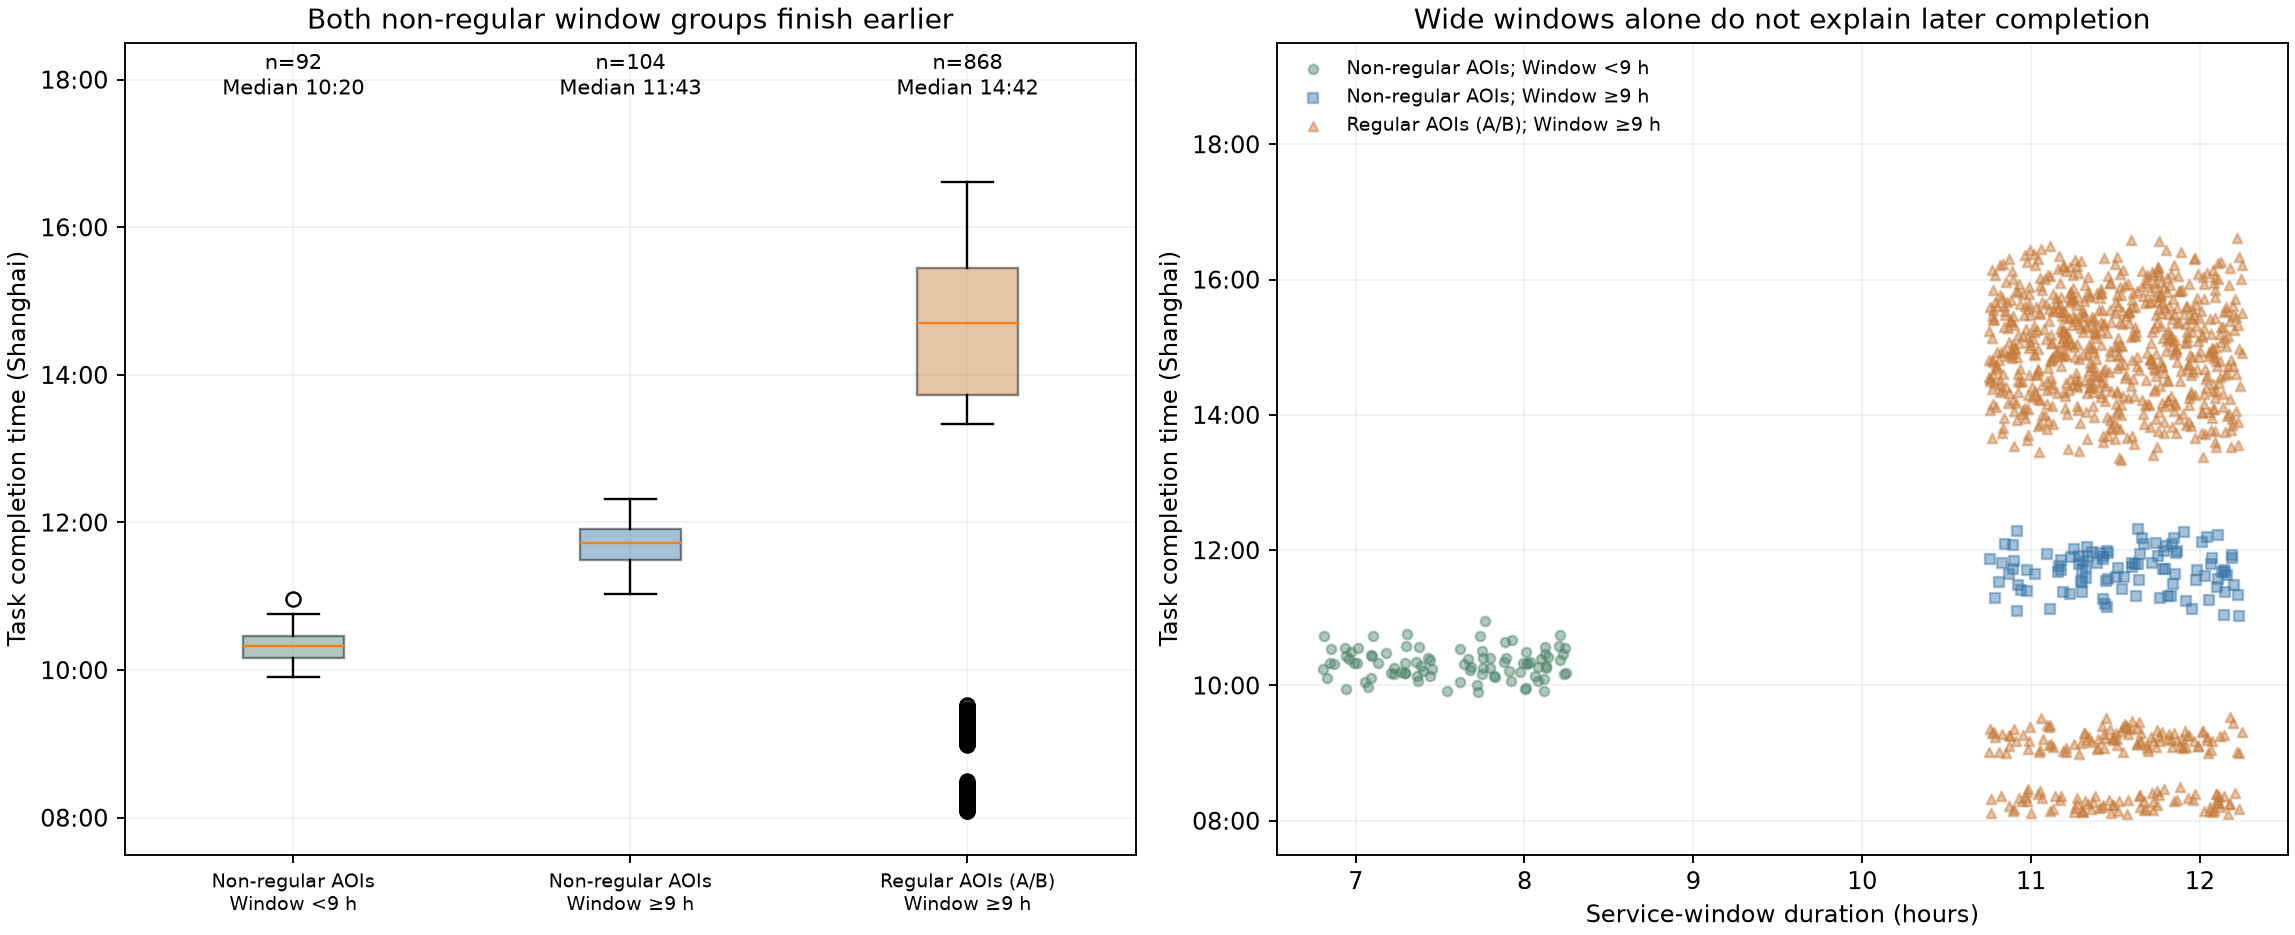

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

legs = pd.read_csv("movement_legs.csv")
visits = pd.read_csv("aoi_visits.csv")
extra = {}
extra["receipt_events"] = pd.read_csv("receipt_events.csv")
extra["aois"] = pd.read_csv("aois.csv")


def evidence(case, index, df, user_df, legs, visits, extra):
    import json
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)
    moving = user_df[user_df.activity_state.eq("travelling")].copy()
    done = df[df.status.eq("completed")].copy()
    value = {}
    if case == 21:
        order = ["primary", "secondary", "tertiary", "residential"]
        moving = moving.merge(
            legs[["leg_id", "period"]], on="leg_id", validate="many_to_one"
        )
        if index == 1:
            summary = (
                moving.groupby("fclass")[["step_distance_km", "step_duration_s"]]
                .sum()
                .reindex(order)
            )
            summary["movement_speed_kmh"] = (
                summary.step_distance_km / summary.step_duration_s * 3600
            )
            summary["completions"] = done.delivery_fclass.value_counts().reindex(
                order, fill_value=0
            )
            summary["completions_per_km"] = (
                summary.completions / summary.step_distance_km
            )
            ax.bar(
                order,
                summary.movement_speed_kmh,
                color="#5c8ea7",
                alpha=0.8,
                label="Movement speed",
            )
            twin = ax.twinx()
            twin.plot(order, summary.completions_per_km, "o-", color="#bd7843")
            ax.set(ylabel="Distance / moving time (km/h)", xlabel="Native OSM fclass")
            twin.set_ylabel("Delivery completions per travelled km", color="#bd7843")
            value = {"road_class_summary": summary.to_dict("index")}
        elif index == 2:
            summary = (
                moving.groupby(["period", "fclass"])
                .step_distance_km.sum()
                .unstack(fill_value=0)
            )
            summary = summary.div(summary.sum(axis=1), axis=0).reindex(
                ["early", "late"]
            )
            summary[order].plot.bar(stacked=True, ax=ax, rot=0)
            ax.set(
                ylabel="Share of all moving distance",
                xlabel="First / second half of scheduled delivery stops",
            )
            tasks = done.merge(
                legs[["leg_id", "period"]], left_on="arrival_leg_id", right_on="leg_id"
            )
            value = {
                "distance_shares": summary.to_dict("index"),
                "completion_counts": tasks.period.value_counts().to_dict(),
            }
        else:
            # Smooth spatial AND temporal event kernel, independently measured
            # from task-completion positions/times rather than a generator label.
            frames = []
            for tid, q in moving.groupby("trajectory_id"):
                t = done[done.trajectory_id.eq(tid)]
                x = q[["lng", "lat"]].to_numpy() * [95.2, 111]
                y = t[["delivery_lng", "delivery_lat"]].to_numpy() * [95.2, 111]
                ds = np.linalg.norm(x[:, None] - y[None, :], axis=2)
                a = (
                    pd.to_datetime(q.gps_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                b = (
                    pd.to_datetime(t.completion_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                dt = abs(a[:, None] - b[None, :]) / 6e10
                q = q.copy()
                q["nearby_activity"] = (np.exp(-ds / 0.30) * np.exp(-dt / 30)).sum(
                    axis=1
                )
                frames.append(q)
            points = pd.concat(frames)
            values = {}
            for cls in order:
                q = points[points.fclass.eq(cls)]
                bins = pd.qcut(q.nearby_activity, 5, duplicates="drop")
                med = q.groupby(bins, observed=True)[
                    ["nearby_activity", "speed_kmh"]
                ].median()
                line = ax.plot(med.nearby_activity, med.speed_kmh, "o-", label=cls)[0]
                sample = q.sample(min(350, len(q)), random_state=17)
                ax.scatter(
                    sample.nearby_activity,
                    sample.speed_kmh,
                    s=6,
                    alpha=0.10,
                    color=line.get_color(),
                )
                values[cls] = {
                    "points": len(q),
                    "spearman": q.nearby_activity.corr(q.speed_kmh, method="spearman"),
                    "low_to_high_activity_speed_drop_kmh": (
                        med.speed_kmh.iloc[0] - med.speed_kmh.iloc[-1]
                    ),
                    "quintile_medians": med.to_dict("list"),
                }
            ax.set(
                xlabel=(
                    "Nearby completion intensity (300 m / 30 min exponential kernel)"
                ),
                ylabel="Median moving speed (km/h)",
            )
            ax.legend()
            value = {"within_class_evidence": values}
    elif case == 22:
        if index == 1:
            counts = (
                done.groupby(["service_date", "aoi_id"]).size().unstack(fill_value=0)
            )
            span = user_df.groupby("trajectory_id").gps_time.agg(["min", "max"])
            duration = (
                pd.to_datetime(span["max"], format="mixed")
                - pd.to_datetime(span["min"], format="mixed")
            ).dt.total_seconds()
            shares = (
                visits.groupby(["trajectory_id", "aoi_id"])
                .duration_s.sum()
                .unstack(fill_value=0)
                .div(duration, axis=0)
            )
            summary = pd.DataFrame(
                {
                    "mean_deliveries_per_day": counts.mean(),
                    "mean_work_time_share": shares.mean(),
                }
            )
            summary.plot.bar(
                y="mean_deliveries_per_day", ax=ax, rot=0, legend=False, color="#608ea4"
            )
            ax.set(
                ylabel="Completed deliveries per observed day", xlabel="Constructed AOI"
            )
            twin = ax.twinx()
            twin.plot(
                np.arange(len(summary)),
                summary.mean_work_time_share * 100,
                "o-",
                color="#bd7843",
            )
            twin.set_ylabel("Mean observed workday time (%)")
            value = {
                "aoi_summary": summary.to_dict("index"),
                "observed_days": counts.shape[0],
                "regular_destination_fclasses": sorted(
                    done[done.regular_aoi.eq("yes")].delivery_fclass.unique().tolist()
                ),
                "fixed_receipt_sites": (
                    extra["receipt_events"]
                    .groupby("aoi_id")[["lng", "lat"]]
                    .nunique()
                    .to_dict("index")
                ),
            }
        elif index == 2:
            q = legs[legs.purpose.eq("delivery")]
            plt.close(fig)
            fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), constrained_layout=True)
            ax = axes[0]
            ax.boxplot(
                [q[q.period.eq(p)].route_directness_ratio for p in ["early", "late"]],
                tick_labels=["Early", "Late"],
            )
            ax.set(
                xlabel="Delivery route phase",
                ylabel="Travelled / straight-line distance",
                title=(
                    "Later delivery routes are more direct\nLower ratio = less detour"
                ),
            )
            dates = sorted(q.service_date.unique())
            totals = moving.groupby("service_date")[
                ["step_distance_km", "step_duration_s"]
            ].sum()
            baseline = totals.step_distance_km / totals.step_duration_s * 3600
            late = q[q.period.eq("late")].copy()
            late["day_mean_movement_speed_kmh"] = late.service_date.map(baseline)
            late["difference_from_day_mean_kmh"] = (
                late.mean_speed_kmh - late.day_mean_movement_speed_kmh
            )
            above = late.difference_from_day_mean_kmh.gt(0)
            x = late.service_date.map({day: i for i, day in enumerate(dates)}).to_numpy(
                dtype=float
            )
            x += np.where(late.groupby("service_date").cumcount().eq(0), -0.12, 0.12)
            axes[1].axhline(
                0,
                color="#555555",
                linewidth=1,
                linestyle="--",
                label="Same as day mean",
            )
            for mask, color, label in [
                (above, "#3976a8", "Above day mean"),
                (~above, "#c77c3d", "At or below day mean"),
            ]:
                axes[1].scatter(
                    x[mask],
                    late.loc[mask, "difference_from_day_mean_kmh"],
                    color=color,
                    s=48,
                    label=f"{label}: {int(mask.sum())}/{len(late)} ({mask.mean():.1%})",
                )
            axes[1].set(
                xticks=np.arange(len(dates)),
                xticklabels=[day[5:] for day in dates],
                xlabel="Workday — each point is a delivery leg as time drew to a close",
                ylabel="Leg speed − day mean movement speed (km/h)",
                title=(
                    "As time drew to a close:\nMore direct does not guarantee"
                    " above-average speed"
                ),
            )
            axes[1].margins(y=0.30)
            axes[1].tick_params(axis="x", rotation=45, labelsize=8)
            axes[1].legend(loc="upper left", fontsize=8, frameon=False)
            axes[1].grid(axis="y", alpha=0.15)
            value = {
                "period_means": (
                    q.groupby("period")[["route_directness_ratio", "mean_speed_kmh"]]
                    .mean()
                    .to_dict("index")
                ),
                "day_mean_definition": (
                    "All moving GPS distance / all moving GPS time, including return"
                    " legs and excluding stops"
                ),
                "daily_mean_movement_speed_kmh": baseline.to_dict(),
                "late_delivery_legs": len(late),
                "late_legs_above_day_mean": int(above.sum()),
                "late_share_above_day_mean": float(above.mean()),
                "late_leg_comparison": (
                    late[
                        [
                            "leg_id",
                            "service_date",
                            "mean_speed_kmh",
                            "day_mean_movement_speed_kmh",
                            "difference_from_day_mean_kmh",
                        ]
                    ].to_dict("records")
                ),
            }
        elif index == 3:
            q = done.copy()
            stamp = pd.to_datetime(q.completion_time, format="mixed")
            q["completion_hour"] = (
                stamp.dt.hour + stamp.dt.minute / 60 + stamp.dt.second / 3600
            )
            q["window_hours"] = (
                pd.to_datetime(q.time_window_end) - pd.to_datetime(q.time_window_start)
            ).dt.total_seconds() / 3600
            plt.close(fig)
            fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5), constrained_layout=True)
            ax = axes[0]
            groups = [
                q[q.regular_aoi.eq("no") & q.window_hours.lt(9)],
                q[q.regular_aoi.eq("no") & q.window_hours.ge(9)],
                q[q.regular_aoi.eq("yes") & q.window_hours.ge(9)],
            ]
            labels = [
                "Non-regular AOIs\nWindow <9 h",
                "Non-regular AOIs\nWindow ≥9 h",
                "Regular AOIs (A/B)\nWindow ≥9 h",
            ]
            colors = ["#4f846c", "#3976a8", "#c77c3d"]
            boxes = ax.boxplot(
                [g.completion_hour for g in groups],
                tick_labels=labels,
                patch_artist=True,
            )
            for box, color in zip(boxes["boxes"], colors):
                box.set_facecolor(color)
                box.set_alpha(0.45)
            for i, g in enumerate(groups, 1):
                median = g.completion_hour.median()
                h = int(median)
                minute = int(round((median - h) * 60))
                ax.text(
                    i,
                    17.8,
                    f"n={len(g)}\nMedian {h:02}:{minute:02}",
                    ha="center",
                    fontsize=9,
                )
            ax.set(
                ylabel="Task completion time (Shanghai)",
                title="Both non-regular window groups finish earlier",
                ylim=(7.5, 18.5),
            )
            ax.yaxis.set_major_formatter(lambda v, _: f"{int(v):02}:00")
            ax.tick_params(axis="x", labelsize=8)
            for g, label, color, marker in zip(groups, labels, colors, ["o", "s", "^"]):
                axes[1].scatter(
                    g.window_hours,
                    g.completion_hour,
                    s=16,
                    alpha=0.45,
                    color=color,
                    marker=marker,
                    label=label.replace("\n", "; "),
                )
            axes[1].set(
                xlabel="Service-window duration (hours)",
                ylabel="Task completion time (Shanghai)",
                title="Wide windows alone do not explain later completion",
                ylim=(7.5, 19.5),
            )
            axes[1].yaxis.set_major_formatter(lambda v, _: f"{int(v):02}:00")
            axes[1].legend(loc="upper left", fontsize=8, frameon=False)
            axes[1].grid(alpha=0.15)
            nvisits = visits.groupby(["service_date", "aoi_id"]).size()
            value = {
                "group_medians": (
                    q.groupby("regular_aoi")[["completion_hour", "window_hours"]]
                    .median()
                    .to_dict("index")
                ),
                "regular_aoi_visits_per_day": (
                    nvisits.unstack(fill_value=0)[["A", "B"]].to_dict("list")
                ),
                "irregular_by_window_median_hour": (
                    q[q.regular_aoi.eq("no")]
                    .assign(
                        window_group=lambda d: np.where(
                            d.window_hours < 9, "Narrower (<9h)", "Wide (9h+)"
                        )
                    )
                    .groupby("window_group")
                    .completion_hour.median()
                    .to_dict()
                ),
                "plotted_groups": {
                    label.replace("\n", "; "): {
                        "tasks": len(g),
                        "median_completion_hour": float(g.completion_hour.median()),
                        "window_hours_min": float(g.window_hours.min()),
                        "window_hours_max": float(g.window_hours.max()),
                    }
                    for label, g in zip(labels, groups)
                },
                "uncompleted_tasks_excluded": int(df.status.ne("completed").sum()),
            }
        else:
            irregular = df[df.regular_aoi.eq("no")]
            summary = (
                irregular.groupby(["service_date", "status"])
                .size()
                .unstack(fill_value=0)
            )
            summary.plot.bar(stacked=True, ax=ax, rot=50)
            ax.set(ylabel="Available irregular-AOI tasks", xlabel="Workday")
            pending = irregular[irregular.status.eq("pending")]
            dates = pending.service_date.unique().tolist()
            min_dist = {}
            for day in dates:
                gps = user_df[user_df.service_date.eq(day)]
                destinations = pending[pending.service_date.eq(day)][
                    ["aoi_id", "delivery_lng", "delivery_lat"]
                ].drop_duplicates()
                for r in destinations.itertuples():
                    ds = np.linalg.norm(
                        (
                            gps[["lng", "lat"]].to_numpy()
                            - [r.delivery_lng, r.delivery_lat]
                        )
                        * [95200, 111000],
                        axis=1,
                    )
                    min_dist[r.aoi_id] = float(ds.min())
            value = {
                "pending_dates": dates,
                "pending_tasks": len(pending),
                "minimum_GPS_distance_to_unvisited_AOI_m": min_dist,
                "anomaly_day_irregular_visit_count": int(
                    len(
                        visits[
                            visits.service_date.isin(dates)
                            & ~visits.aoi_id.isin(["A", "B"])
                        ]
                    )
                ),
            }
    elif case == 23:
        q = legs[legs.purpose.eq("delivery")].copy()
        # Initial departure is not between two completed task locations.
        q = q[q.groupby("trajectory_id").cumcount().gt(0)]
        if index == 1:
            q = q[q.period.ne("exception") & q.separation_km.between(0.7, 1.4)]
            q["oneway_group"] = np.where(
                q.oneway_share >= 0.55,
                "High (55%+)",
                np.where(q.oneway_share <= 0.25, "Low (0–25%)", "Middle"),
            )
            q = q[q.oneway_group.ne("Middle")]
            for name, s in q.groupby("oneway_group"):
                ax.scatter(
                    s.separation_km, s.route_directness_ratio, label=name, alpha=0.6
                )
            ax.set(
                xlabel="Task endpoint separation (km)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "matched_separation_range_km": [0.7, 1.4],
                "group_means": (
                    q.groupby("oneway_group")[
                        ["separation_km", "route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "within_period_group_means": (
                    q.groupby(["period", "oneway_group"])[
                        ["route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .reset_index()
                    .to_dict("records")
                ),
            }
        elif index == 2:
            means = (
                q[q.period.ne("exception")]
                .groupby("period")[["mean_speed_kmh", "route_directness_ratio"]]
                .mean()
                .reindex(["early", "midday", "late"])
            )
            ax.plot(means.index, means.mean_speed_kmh, "o-", color="#608ea4")
            ax.set_ylabel("Mean leg speed (km/h)")
            twin = ax.twinx()
            twin.plot(means.index, means.route_directness_ratio, "s-", color="#bd7843")
            twin.set_ylabel("Mean route directness ratio")
            value = {"period_means": means.to_dict("index")}
        elif index == 3:
            p = (
                q[q.period.ne("exception")]
                .groupby(["service_date", "period"])
                .agg(
                    detour_sd=("route_directness_ratio", "std"),
                    speed_sd=("mean_speed_kmh", "std"),
                    transitions=("fclass_transitions", "sum"),
                    distance=("distance_km", "sum"),
                )
            )
            p["transitions_per_km"] = p.transitions / p.distance
            ax.scatter(
                p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap="viridis", s=50
            )
            fig.colorbar(ax.collections[0], ax=ax, label="Across-leg speed SD (km/h)")
            ax.set(
                xlabel="Native fclass transitions per travelled km",
                ylabel="Within-period route-ratio SD",
            )
            cut = p.transitions_per_km.median()
            p["transition_group"] = np.where(
                p.transitions_per_km > cut, "Frequent", "Less frequent"
            )
            value = {
                "correlation_transition_frequency_detour_sd": p.transitions_per_km.corr(
                    p.detour_sd
                ),
                "group_means": (
                    p.groupby("transition_group")[
                        ["detour_sd", "speed_sd", "transitions_per_km"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "period_count": len(p),
            }
        else:
            normal = q[q.period.ne("exception")]
            exception = q[q.period.eq("exception")]
            ax.scatter(
                normal.oneway_share * 100,
                normal.route_directness_ratio,
                alpha=0.4,
                label="Other task legs",
            )
            ax.scatter(
                exception.oneway_share * 100,
                exception.route_directness_ratio,
                marker="*",
                s=220,
                color="#c66643",
                label="Exceptional period",
            )
            ax.set(
                xlabel="One-way-road distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "exception": (
                    exception[
                        [
                            "leg_id",
                            "route_directness_ratio",
                            "oneway_share",
                            "mean_speed_kmh",
                            "distance_km",
                            "separation_km",
                        ]
                    ].to_dict("records")
                ),
                "normal_speed_10_90_percentiles": (
                    normal.mean_speed_kmh.quantile([0.1, 0.9]).tolist()
                ),
                "schema_oneway_unit_assumption": (
                    "2.01 interpreted provisionally as percent, pending user"
                    " confirmation"
                ),
            }
    elif case == 24:
        if index == 1:
            q = legs[legs.purpose.str.startswith("road_condition")]
            q.boxplot(column="speed_std_kmh", by="purpose", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Road condition",
                ylabel="Short-term GPS speed SD (km/h)",
                title="Stable residential travel versus alternating road classes",
            )
            value = {
                "condition_means": (
                    q.groupby("purpose")[
                        [
                            "speed_std_kmh",
                            "residential_share",
                            "tertiary_share",
                            "fclass_transitions",
                        ]
                    ]
                    .mean()
                    .to_dict("index")
                )
            }
        else:
            q = extra["crossings"].merge(
                legs,
                left_on="crossing_leg_id",
                right_on="leg_id",
                validate="one_to_one",
            )
            low = moving[moving.speed_kmh < 12].groupby("leg_id").step_duration_s.sum()
            q["low_speed_seconds"] = q.leg_id.map(low).fillna(0)
            approach = legs.set_index("leg_id").mean_speed_kmh
            q["speed_drop_kmh"] = q.approach_leg_id.map(approach) - q.mean_speed_kmh
            if index == 2:
                q.boxplot(
                    column="low_speed_seconds", by=["structure_type", "period"], ax=ax
                )
                fig.suptitle("")
                ax.set(
                    xlabel="Same mapped structure / workday phase",
                    ylabel="Time below 12 km/h (seconds)",
                    title="Repeated early and late crossings",
                )
                value = {
                    "structure_period_means": (
                        q.groupby(["structure_osm_way_id", "structure_type", "period"])[
                            ["low_speed_seconds", "speed_std_kmh", "mean_speed_kmh"]
                        ]
                        .mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                    "crossings": len(q),
                    "unique_structures": q.structure_osm_way_id.nunique(),
                }
            else:
                q.boxplot(column="speed_drop_kmh", by="approach_fclass", ax=ax)
                fig.suptitle("")
                ax.set(
                    xlabel="Dominant road class in last 800 m before structure",
                    ylabel="Approach minus crossing speed (km/h)",
                    title="Road approach conditions and crossing slowdowns",
                )
                value = {
                    "approach_means": (
                        q.groupby("approach_fclass")[
                            ["speed_drop_kmh", "approach_dominant_share"]
                        ]
                        .mean()
                        .to_dict("index")
                    ),
                    "within_structure_period_means": (
                        q.groupby(["structure_osm_way_id", "period", "approach_fclass"])
                        .speed_drop_kmh.mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                }
    elif case == 25:
        if index == 1:
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=0.5
                )
            ax.set(
                xlabel="Travelled / straight-line distance",
                ylabel="Leg movement speed (km/h)",
            )
            ax.legend()
            summary = legs.groupby("region_id")[
                ["route_directness_ratio", "mean_speed_kmh"]
            ].mean()
            summary["delivery_volume"] = done.groupby("region_id").size()
            value = {
                "region_means": summary.to_dict("index"),
                "region_role_mapping": (
                    extra["regions"][["region_id", "comparison_role"]].to_dict(
                        "records"
                    )
                ),
            }
        elif index == 2:
            summary = legs.groupby(["region_id", "period"])[
                ["route_directness_ratio", "primary_share", "residential_share"]
            ].mean()
            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)
            ax.set(
                ylabel="Mean travelled / straight-line distance",
                xlabel="Constructed service region",
            )
            value = {"region_period_means": summary.reset_index().to_dict("records")}
        else:
            values = {}
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.oneway_share * 100,
                    q.route_directness_ratio,
                    label=name,
                    alpha=0.5,
                )
                values[name] = {
                    "pearson": q.oneway_share.corr(q.route_directness_ratio),
                    "spearman": q.oneway_share.corr(
                        q.route_directness_ratio, method="spearman"
                    ),
                    "legs": len(q),
                    "oneway_share_unique_values": q.oneway_share.nunique(),
                    "route_ratio_unique_values": q.route_directness_ratio.nunique(),
                }
            ax.set(
                xlabel="One-way-road share of travelled distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {"within_region_associations": values}
    ax.grid(alpha=0.15)
    return json.loads(json.dumps(value, default=lambda x: x.item()))


evidence_value = evidence(22, 3, df, user_df, legs, visits, extra)
print(evidence_value)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "road_backed_evidence_3",
  "insight_type": "overall_pattern",
  "insight": "The courier tends to later complete tasks in regular visited AOIs with large time-windows, prioritizing tasks in unregular visited AOIs regardless of the time constraints.",
  "insight_value": {
    "group_medians": {
      "no": {
        "completion_hour": 11.184444444444445,
        "window_hours": 10.879888202898332
      },
      "yes": {
        "completion_hour": 14.706249999999999,
        "window_hours": 11.480732740522223
      }
    },
    "regular_aoi_visits_per_day": {
      "A": [
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2
      ],
      "B": [
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2
      ]
    },
    "irregular_by_window_median_hour": {
      "Narrower (<9h)": 10.325416666666666,
      "Wide (9h+)": 11.717777777777776
    },
    "plotted_groups": {
      "Non-regular AOIs; Window <9 h": {
        "tasks": 92,
        "median_completion_hour": 10.325416666666666,
        "window_hours_min": 6.8041703370225,
        "window_hours_max": 8.247352111219723
      },
      "Non-regular AOIs; Window ≥9 h": {
        "tasks": 104,
        "median_completion_hour": 11.717777777777776,
        "window_hours_min": 10.754844531029724,
        "window_hours_max": 12.231419884158612
      },
      "Regular AOIs (A/B); Window ≥9 h": {
        "tasks": 868,
        "median_completion_hour": 14.706249999999999,
        "window_hours_min": 10.751128895383333,
        "window_hours_max": 12.249547963983055
      }
    },
    "uncompleted_tasks_excluded": 14
  },
  "question": "Do both narrower- and wider-window tasks at non-regular AOIs finish earlier than wide-window tasks at regular AOIs?",
  "actionable_insight": "Interpret the constructed descriptive association, not an estimated causal effect.",
  "plot": {
    "plot_type": "window_stratified_completion_times",
    "title": "LaDe 22 insight 3",
    "file": "visualizations/insight_3.png",
    "description": "Completed tasks are split into non-regular AOIs with windows below nine hours, non-regular AOIs with windows of at least nine hours, and regular AOIs with wide windows. Left shows completion-time distributions; right shows window duration versus completion time. Pending tasks are excluded and remain available for insight 4."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nlegs = pd.read_csv(\"movement_legs.csv\")\nvisits = pd.read_csv(\"aoi_visits.csv\")\nextra = {}\nextra[\"receipt_events\"] = pd.read_csv(\"receipt_events.csv\")\nextra[\"aois\"] = pd.read_csv(\"aois.csv\")\n\ndef evidence(case, index, df, user_df, legs, visits, extra):\n    import json\n    import numpy as np\n    import pandas as pd\n    import matplotlib.pyplot as plt\n\n    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)\n    moving = user_df[user_df.activity_state.eq('travelling')].copy()\n    done = df[df.status.eq('completed')].copy()\n    value = {}\n    if case == 21:\n        order = ['primary', 'secondary', 'tertiary', 'residential']\n        moving = moving.merge(legs[['leg_id', 'period']], on='leg_id', validate='many_to_one')\n        if index == 1:\n            summary = moving.groupby('fclass')[['step_distance_km', 'step_duration_s']].sum().reindex(order)\n            summary['movement_speed_kmh'] = summary.step_distance_km/summary.step_duration_s*3600\n            summary['completions'] = done.delivery_fclass.value_counts().reindex(order, fill_value=0)\n            summary['completions_per_km'] = summary.completions/summary.step_distance_km\n            ax.bar(order, summary.movement_speed_kmh, color='#5c8ea7', alpha=.8, label='Movement speed')\n            twin = ax.twinx(); twin.plot(order, summary.completions_per_km, 'o-', color='#bd7843')\n            ax.set(ylabel='Distance / moving time (km/h)', xlabel='Native OSM fclass')\n            twin.set_ylabel('Delivery completions per travelled km', color='#bd7843')\n            value = {'road_class_summary': summary.to_dict('index')}\n        elif index == 2:\n            summary = moving.groupby(['period', 'fclass']).step_distance_km.sum().unstack(fill_value=0)\n            summary = summary.div(summary.sum(axis=1), axis=0).reindex(['early', 'late'])\n            summary[order].plot.bar(stacked=True, ax=ax, rot=0)\n            ax.set(ylabel='Share of all moving distance', xlabel='First / second half of scheduled delivery stops')\n            tasks = done.merge(legs[['leg_id', 'period']], left_on='arrival_leg_id', right_on='leg_id')\n            value = {'distance_shares': summary.to_dict('index'), 'completion_counts': tasks.period.value_counts().to_dict()}\n        else:\n            # Smooth spatial AND temporal event kernel, independently measured\n            # from task-completion positions/times rather than a generator label.\n            frames = []\n            for tid, q in moving.groupby('trajectory_id'):\n                t = done[done.trajectory_id.eq(tid)]\n                x = q[['lng', 'lat']].to_numpy()*[95.2, 111]\n                y = t[['delivery_lng', 'delivery_lat']].to_numpy()*[95.2, 111]\n                ds = np.linalg.norm(x[:, None]-y[None, :], axis=2)\n                a = pd.to_datetime(q.gps_time, format='mixed').astype('int64').to_numpy()\n                b = pd.to_datetime(t.completion_time, format='mixed').astype('int64').to_numpy()\n                dt = abs(a[:, None]-b[None, :])/6e10\n                q = q.copy(); q['nearby_activity'] = (np.exp(-ds/.30)*np.exp(-dt/30)).sum(axis=1)\n                frames.append(q)\n            points = pd.concat(frames); values = {}\n            for cls in order:\n                q = points[points.fclass.eq(cls)]\n                bins = pd.qcut(q.nearby_activity, 5, duplicates='drop')\n                med = q.groupby(bins, observed=True)[['nearby_activity', 'speed_kmh']].median()\n                line = ax.plot(med.nearby_activity, med.speed_kmh, 'o-', label=cls)[0]\n                sample = q.sample(min(350, len(q)), random_state=17)\n                ax.scatter(sample.nearby_activity, sample.speed_kmh, s=6, alpha=.10, color=line.get_color())\n                values[cls] = {'points': len(q), 'spearman': q.nearby_activity.corr(q.speed_kmh, method='spearman'),\n                    'low_to_high_activity_speed_drop_kmh': med.speed_kmh.iloc[0]-med.speed_kmh.iloc[-1],\n                    'quintile_medians': med.to_dict('list')}\n            ax.set(xlabel='Nearby completion intensity (300 m / 30 min exponential kernel)', ylabel='Median moving speed (km/h)'); ax.legend()\n            value = {'within_class_evidence': values}\n    elif case == 22:\n        if index == 1:\n            counts = done.groupby(['service_date', 'aoi_id']).size().unstack(fill_value=0)\n            span = user_df.groupby('trajectory_id').gps_time.agg(['min', 'max'])\n            duration = (pd.to_datetime(span['max'], format='mixed')-pd.to_datetime(span['min'], format='mixed')).dt.total_seconds()\n            shares = visits.groupby(['trajectory_id', 'aoi_id']).duration_s.sum().unstack(fill_value=0).div(duration, axis=0)\n            summary = pd.DataFrame({'mean_deliveries_per_day': counts.mean(), 'mean_work_time_share': shares.mean()})\n            summary.plot.bar(y='mean_deliveries_per_day', ax=ax, rot=0, legend=False, color='#608ea4')\n            ax.set(ylabel='Completed deliveries per observed day', xlabel='Constructed AOI')\n            twin = ax.twinx(); twin.plot(np.arange(len(summary)), summary.mean_work_time_share*100, 'o-', color='#bd7843'); twin.set_ylabel('Mean observed workday time (%)')\n            value = {'aoi_summary': summary.to_dict('index'), 'observed_days': counts.shape[0],\n                'regular_destination_fclasses': sorted(done[done.regular_aoi.eq('yes')].delivery_fclass.unique().tolist()),\n                'fixed_receipt_sites': extra['receipt_events'].groupby('aoi_id')[['lng', 'lat']].nunique().to_dict('index')}\n        elif index == 2:\n            q = legs[legs.purpose.eq('delivery')]\n            plt.close(fig)\n            fig,axes=plt.subplots(1,2,figsize=(13,5.4),constrained_layout=True);ax=axes[0]\n            ax.boxplot([q[q.period.eq(p)].route_directness_ratio for p in ['early','late']],\n                tick_labels=['Early','Late'])\n            ax.set(xlabel='Delivery route phase',ylabel='Travelled / straight-line distance',\n                title='Later delivery routes are more direct\\nLower ratio = less detour')\n            dates=sorted(q.service_date.unique())\n            totals=moving.groupby('service_date')[['step_distance_km','step_duration_s']].sum()\n            baseline=totals.step_distance_km/totals.step_duration_s*3600\n            late=q[q.period.eq('late')].copy()\n            late['day_mean_movement_speed_kmh']=late.service_date.map(baseline)\n            late['difference_from_day_mean_kmh']=late.mean_speed_kmh-late.day_mean_movement_speed_kmh\n            above=late.difference_from_day_mean_kmh.gt(0)\n            x=late.service_date.map({day:i for i,day in enumerate(dates)}).to_numpy(dtype=float)\n            x+=np.where(late.groupby('service_date').cumcount().eq(0),-.12,.12)\n            axes[1].axhline(0,color='#555555',linewidth=1,linestyle='--',label='Same as day mean')\n            for mask,color,label in [(above,'#3976a8','Above day mean'),(~above,'#c77c3d','At or below day mean')]:\n                axes[1].scatter(x[mask],late.loc[mask,'difference_from_day_mean_kmh'],color=color,s=48,\n                    label=f'{label}: {int(mask.sum())}/{len(late)} ({mask.mean():.1%})')\n            axes[1].set(xticks=np.arange(len(dates)),xticklabels=[day[5:] for day in dates],\n                xlabel='Workday — each point is a delivery leg as time drew to a close',ylabel='Leg speed − day mean movement speed (km/h)',\n                title='As time drew to a close:\\nMore direct does not guarantee above-average speed')\n            axes[1].margins(y=.30)\n            axes[1].tick_params(axis='x',rotation=45,labelsize=8)\n            axes[1].legend(loc='upper left',fontsize=8,frameon=False)\n            axes[1].grid(axis='y',alpha=.15)\n            value = {'period_means': q.groupby('period')[['route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'day_mean_definition':'All moving GPS distance / all moving GPS time, including return legs and excluding stops',\n                'daily_mean_movement_speed_kmh':baseline.to_dict(),\n                'late_delivery_legs':len(late),'late_legs_above_day_mean':int(above.sum()),\n                'late_share_above_day_mean':float(above.mean()),\n                'late_leg_comparison':late[['leg_id','service_date','mean_speed_kmh','day_mean_movement_speed_kmh','difference_from_day_mean_kmh']].to_dict('records')}\n        elif index == 3:\n            q = done.copy(); stamp = pd.to_datetime(q.completion_time, format='mixed')\n            q['completion_hour'] = stamp.dt.hour+stamp.dt.minute/60+stamp.dt.second/3600\n            q['window_hours'] = (pd.to_datetime(q.time_window_end)-pd.to_datetime(q.time_window_start)).dt.total_seconds()/3600\n            plt.close(fig)\n            fig,axes=plt.subplots(1,2,figsize=(13.5,5.5),constrained_layout=True);ax=axes[0]\n            groups=[q[q.regular_aoi.eq('no')&q.window_hours.lt(9)],\n                    q[q.regular_aoi.eq('no')&q.window_hours.ge(9)],q[q.regular_aoi.eq('yes')&q.window_hours.ge(9)]]\n            labels=['Non-regular AOIs\\nWindow <9 h','Non-regular AOIs\\nWindow ≥9 h','Regular AOIs (A/B)\\nWindow ≥9 h']\n            colors=['#4f846c','#3976a8','#c77c3d']\n            boxes=ax.boxplot([g.completion_hour for g in groups],tick_labels=labels,patch_artist=True)\n            for box,color in zip(boxes['boxes'],colors):box.set_facecolor(color);box.set_alpha(.45)\n            for i,g in enumerate(groups,1):\n                median=g.completion_hour.median();h=int(median);minute=int(round((median-h)*60))\n                ax.text(i,17.8,f'n={len(g)}\\nMedian {h:02}:{minute:02}',ha='center',fontsize=9)\n            ax.set(ylabel='Task completion time (Shanghai)',title='Both non-regular window groups finish earlier',ylim=(7.5,18.5))\n            ax.yaxis.set_major_formatter(lambda v,_:f'{int(v):02}:00')\n            ax.tick_params(axis='x',labelsize=8)\n            for g,label,color,marker in zip(groups,labels,colors,['o','s','^']):\n                axes[1].scatter(g.window_hours,g.completion_hour,s=16,alpha=.45,\n                    color=color,marker=marker,label=label.replace('\\n','; '))\n            axes[1].set(xlabel='Service-window duration (hours)',ylabel='Task completion time (Shanghai)',\n                title='Wide windows alone do not explain later completion',ylim=(7.5,19.5))\n            axes[1].yaxis.set_major_formatter(lambda v,_:f'{int(v):02}:00')\n            axes[1].legend(loc='upper left',fontsize=8,frameon=False)\n            axes[1].grid(alpha=.15)\n            nvisits = visits.groupby(['service_date', 'aoi_id']).size()\n            value = {'group_medians': q.groupby('regular_aoi')[['completion_hour', 'window_hours']].median().to_dict('index'),\n                'regular_aoi_visits_per_day': nvisits.unstack(fill_value=0)[['A', 'B']].to_dict('list'),\n                'irregular_by_window_median_hour': q[q.regular_aoi.eq('no')].assign(window_group=lambda d: np.where(d.window_hours < 9, 'Narrower (<9h)', 'Wide (9h+)')).groupby('window_group').completion_hour.median().to_dict(),\n                'plotted_groups':{label.replace('\\n','; '):{'tasks':len(g),'median_completion_hour':float(g.completion_hour.median()),\n                    'window_hours_min':float(g.window_hours.min()),'window_hours_max':float(g.window_hours.max())}\n                    for label,g in zip(labels,groups)},\n                'uncompleted_tasks_excluded':int(df.status.ne('completed').sum())}\n        else:\n            irregular = df[df.regular_aoi.eq('no')]\n            summary = irregular.groupby(['service_date', 'status']).size().unstack(fill_value=0)\n            summary.plot.bar(stacked=True, ax=ax, rot=50)\n            ax.set(ylabel='Available irregular-AOI tasks', xlabel='Workday')\n            pending = irregular[irregular.status.eq('pending')]; dates = pending.service_date.unique().tolist()\n            min_dist = {}\n            for day in dates:\n                gps = user_df[user_df.service_date.eq(day)]\n                destinations = pending[pending.service_date.eq(day)][['aoi_id', 'delivery_lng', 'delivery_lat']].drop_duplicates()\n                for r in destinations.itertuples():\n                    ds = np.linalg.norm((gps[['lng', 'lat']].to_numpy()-[r.delivery_lng, r.delivery_lat])*[95200, 111000], axis=1)\n                    min_dist[r.aoi_id] = float(ds.min())\n            value = {'pending_dates': dates, 'pending_tasks': len(pending), 'minimum_GPS_distance_to_unvisited_AOI_m': min_dist,\n                'anomaly_day_irregular_visit_count': int(len(visits[visits.service_date.isin(dates)&~visits.aoi_id.isin(['A', 'B'])]))}\n    elif case == 23:\n        q = legs[legs.purpose.eq('delivery')].copy()\n        # Initial departure is not between two completed task locations.\n        q = q[q.groupby('trajectory_id').cumcount().gt(0)]\n        if index == 1:\n            q = q[q.period.ne('exception')&q.separation_km.between(.7, 1.4)]\n            q['oneway_group'] = np.where(q.oneway_share >= .55, 'High (55%+)', np.where(q.oneway_share <= .25, 'Low (0–25%)', 'Middle'))\n            q = q[q.oneway_group.ne('Middle')]\n            for name, s in q.groupby('oneway_group'): ax.scatter(s.separation_km, s.route_directness_ratio, label=name, alpha=.6)\n            ax.set(xlabel='Task endpoint separation (km)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'matched_separation_range_km': [.7, 1.4], 'group_means': q.groupby('oneway_group')[['separation_km', 'route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'within_period_group_means': q.groupby(['period', 'oneway_group'])[['route_directness_ratio', 'mean_speed_kmh']].mean().reset_index().to_dict('records')}\n        elif index == 2:\n            means = q[q.period.ne('exception')].groupby('period')[['mean_speed_kmh', 'route_directness_ratio']].mean().reindex(['early', 'midday', 'late'])\n            ax.plot(means.index, means.mean_speed_kmh, 'o-', color='#608ea4'); ax.set_ylabel('Mean leg speed (km/h)')\n            twin = ax.twinx(); twin.plot(means.index, means.route_directness_ratio, 's-', color='#bd7843'); twin.set_ylabel('Mean route directness ratio')\n            value = {'period_means': means.to_dict('index')}\n        elif index == 3:\n            p = q[q.period.ne('exception')].groupby(['service_date', 'period']).agg(detour_sd=('route_directness_ratio', 'std'), speed_sd=('mean_speed_kmh', 'std'), transitions=('fclass_transitions', 'sum'), distance=('distance_km', 'sum'))\n            p['transitions_per_km'] = p.transitions/p.distance\n            ax.scatter(p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap='viridis', s=50)\n            fig.colorbar(ax.collections[0], ax=ax, label='Across-leg speed SD (km/h)')\n            ax.set(xlabel='Native fclass transitions per travelled km', ylabel='Within-period route-ratio SD')\n            cut = p.transitions_per_km.median(); p['transition_group'] = np.where(p.transitions_per_km > cut, 'Frequent', 'Less frequent')\n            value = {'correlation_transition_frequency_detour_sd': p.transitions_per_km.corr(p.detour_sd),\n                'group_means': p.groupby('transition_group')[['detour_sd', 'speed_sd', 'transitions_per_km']].mean().to_dict('index'), 'period_count': len(p)}\n        else:\n            normal = q[q.period.ne('exception')]; exception = q[q.period.eq('exception')]\n            ax.scatter(normal.oneway_share*100, normal.route_directness_ratio, alpha=.4, label='Other task legs')\n            ax.scatter(exception.oneway_share*100, exception.route_directness_ratio, marker='*', s=220, color='#c66643', label='Exceptional period')\n            ax.set(xlabel='One-way-road distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'exception': exception[['leg_id', 'route_directness_ratio', 'oneway_share', 'mean_speed_kmh', 'distance_km', 'separation_km']].to_dict('records'),\n                'normal_speed_10_90_percentiles': normal.mean_speed_kmh.quantile([.1, .9]).tolist(),\n                'schema_oneway_unit_assumption': '2.01 interpreted provisionally as percent, pending user confirmation'}\n    elif case == 24:\n        if index == 1:\n            q = legs[legs.purpose.str.startswith('road_condition')]\n            q.boxplot(column='speed_std_kmh', by='purpose', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Road condition', ylabel='Short-term GPS speed SD (km/h)', title='Stable residential travel versus alternating road classes')\n            value = {'condition_means': q.groupby('purpose')[['speed_std_kmh', 'residential_share', 'tertiary_share', 'fclass_transitions']].mean().to_dict('index')}\n        else:\n            q = extra['crossings'].merge(legs, left_on='crossing_leg_id', right_on='leg_id', validate='one_to_one')\n            low = moving[moving.speed_kmh < 12].groupby('leg_id').step_duration_s.sum()\n            q['low_speed_seconds'] = q.leg_id.map(low).fillna(0)\n            approach = legs.set_index('leg_id').mean_speed_kmh\n            q['speed_drop_kmh'] = q.approach_leg_id.map(approach)-q.mean_speed_kmh\n            if index == 2:\n                q.boxplot(column='low_speed_seconds', by=['structure_type', 'period'], ax=ax); fig.suptitle('')\n                ax.set(xlabel='Same mapped structure / workday phase', ylabel='Time below 12 km/h (seconds)', title='Repeated early and late crossings')\n                value = {'structure_period_means': q.groupby(['structure_osm_way_id', 'structure_type', 'period'])[['low_speed_seconds', 'speed_std_kmh', 'mean_speed_kmh']].mean().reset_index().to_dict('records'),\n                    'crossings': len(q), 'unique_structures': q.structure_osm_way_id.nunique()}\n            else:\n                q.boxplot(column='speed_drop_kmh', by='approach_fclass', ax=ax); fig.suptitle('')\n                ax.set(xlabel='Dominant road class in last 800 m before structure', ylabel='Approach minus crossing speed (km/h)', title='Road approach conditions and crossing slowdowns')\n                value = {'approach_means': q.groupby('approach_fclass')[['speed_drop_kmh', 'approach_dominant_share']].mean().to_dict('index'),\n                    'within_structure_period_means': q.groupby(['structure_osm_way_id', 'period', 'approach_fclass']).speed_drop_kmh.mean().reset_index().to_dict('records')}\n    elif case == 25:\n        if index == 1:\n            for name, q in legs.groupby('region_id'): ax.scatter(q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=.5)\n            ax.set(xlabel='Travelled / straight-line distance', ylabel='Leg movement speed (km/h)'); ax.legend()\n            summary = legs.groupby('region_id')[['route_directness_ratio', 'mean_speed_kmh']].mean()\n            summary['delivery_volume'] = done.groupby('region_id').size()\n            value = {'region_means': summary.to_dict('index'), 'region_role_mapping': extra['regions'][['region_id', 'comparison_role']].to_dict('records')}\n        elif index == 2:\n            summary = legs.groupby(['region_id', 'period'])[['route_directness_ratio', 'primary_share', 'residential_share']].mean()\n            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)\n            ax.set(ylabel='Mean travelled / straight-line distance', xlabel='Constructed service region')\n            value = {'region_period_means': summary.reset_index().to_dict('records')}\n        else:\n            values = {}\n            for name, q in legs.groupby('region_id'):\n                ax.scatter(q.oneway_share*100, q.route_directness_ratio, label=name, alpha=.5)\n                values[name] = {'pearson': q.oneway_share.corr(q.route_directness_ratio),\n                    'spearman': q.oneway_share.corr(q.route_directness_ratio, method='spearman'),\n                    'legs': len(q), 'oneway_share_unique_values': q.oneway_share.nunique(),\n                    'route_ratio_unique_values': q.route_directness_ratio.nunique()}\n            ax.set(xlabel='One-way-road share of travelled distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'within_region_associations': values}\n    ax.grid(alpha=.15)\n    return json.loads(json.dumps(value, default=lambda x: x.item()))\n\nevidence_value = evidence(22, 3, df, user_df, legs, visits, extra)\nprint(evidence_value)\nplt.show()",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "aoi_id",
    "completion_time",
    "time_window_start",
    "time_window_end",
    "task_id"
  ]
}

### **Question 4**: What CSV-derived evidence supports insight 4?

#### Analysis action

Interpret the constructed descriptive association, not an estimated causal effect.

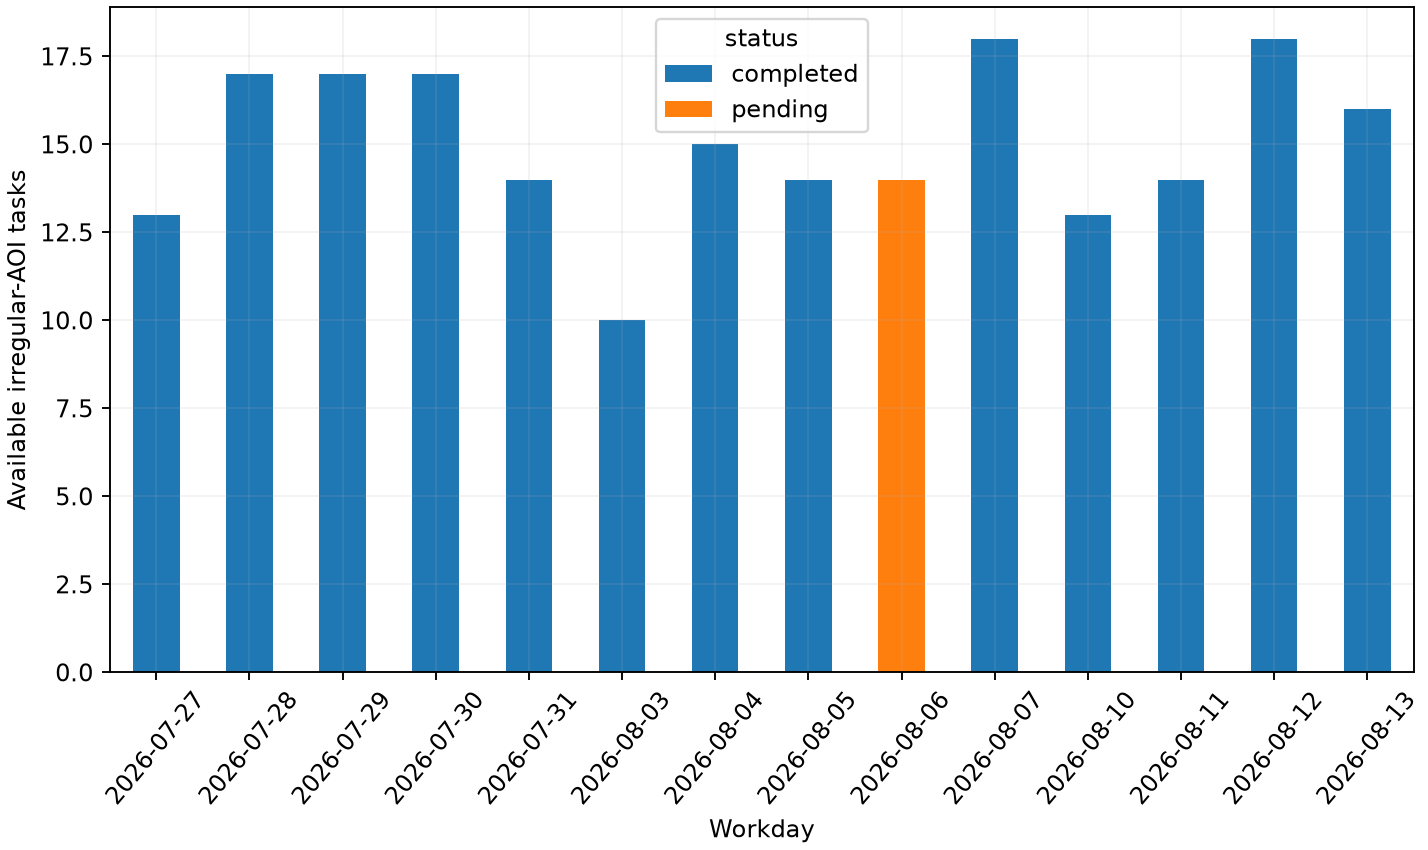

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

legs = pd.read_csv("movement_legs.csv")
visits = pd.read_csv("aoi_visits.csv")
extra = {}
extra["receipt_events"] = pd.read_csv("receipt_events.csv")
extra["aois"] = pd.read_csv("aois.csv")


def evidence(case, index, df, user_df, legs, visits, extra):
    import json
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)
    moving = user_df[user_df.activity_state.eq("travelling")].copy()
    done = df[df.status.eq("completed")].copy()
    value = {}
    if case == 21:
        order = ["primary", "secondary", "tertiary", "residential"]
        moving = moving.merge(
            legs[["leg_id", "period"]], on="leg_id", validate="many_to_one"
        )
        if index == 1:
            summary = (
                moving.groupby("fclass")[["step_distance_km", "step_duration_s"]]
                .sum()
                .reindex(order)
            )
            summary["movement_speed_kmh"] = (
                summary.step_distance_km / summary.step_duration_s * 3600
            )
            summary["completions"] = done.delivery_fclass.value_counts().reindex(
                order, fill_value=0
            )
            summary["completions_per_km"] = (
                summary.completions / summary.step_distance_km
            )
            ax.bar(
                order,
                summary.movement_speed_kmh,
                color="#5c8ea7",
                alpha=0.8,
                label="Movement speed",
            )
            twin = ax.twinx()
            twin.plot(order, summary.completions_per_km, "o-", color="#bd7843")
            ax.set(ylabel="Distance / moving time (km/h)", xlabel="Native OSM fclass")
            twin.set_ylabel("Delivery completions per travelled km", color="#bd7843")
            value = {"road_class_summary": summary.to_dict("index")}
        elif index == 2:
            summary = (
                moving.groupby(["period", "fclass"])
                .step_distance_km.sum()
                .unstack(fill_value=0)
            )
            summary = summary.div(summary.sum(axis=1), axis=0).reindex(
                ["early", "late"]
            )
            summary[order].plot.bar(stacked=True, ax=ax, rot=0)
            ax.set(
                ylabel="Share of all moving distance",
                xlabel="First / second half of scheduled delivery stops",
            )
            tasks = done.merge(
                legs[["leg_id", "period"]], left_on="arrival_leg_id", right_on="leg_id"
            )
            value = {
                "distance_shares": summary.to_dict("index"),
                "completion_counts": tasks.period.value_counts().to_dict(),
            }
        else:
            # Smooth spatial AND temporal event kernel, independently measured
            # from task-completion positions/times rather than a generator label.
            frames = []
            for tid, q in moving.groupby("trajectory_id"):
                t = done[done.trajectory_id.eq(tid)]
                x = q[["lng", "lat"]].to_numpy() * [95.2, 111]
                y = t[["delivery_lng", "delivery_lat"]].to_numpy() * [95.2, 111]
                ds = np.linalg.norm(x[:, None] - y[None, :], axis=2)
                a = (
                    pd.to_datetime(q.gps_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                b = (
                    pd.to_datetime(t.completion_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                dt = abs(a[:, None] - b[None, :]) / 6e10
                q = q.copy()
                q["nearby_activity"] = (np.exp(-ds / 0.30) * np.exp(-dt / 30)).sum(
                    axis=1
                )
                frames.append(q)
            points = pd.concat(frames)
            values = {}
            for cls in order:
                q = points[points.fclass.eq(cls)]
                bins = pd.qcut(q.nearby_activity, 5, duplicates="drop")
                med = q.groupby(bins, observed=True)[
                    ["nearby_activity", "speed_kmh"]
                ].median()
                line = ax.plot(med.nearby_activity, med.speed_kmh, "o-", label=cls)[0]
                sample = q.sample(min(350, len(q)), random_state=17)
                ax.scatter(
                    sample.nearby_activity,
                    sample.speed_kmh,
                    s=6,
                    alpha=0.10,
                    color=line.get_color(),
                )
                values[cls] = {
                    "points": len(q),
                    "spearman": q.nearby_activity.corr(q.speed_kmh, method="spearman"),
                    "low_to_high_activity_speed_drop_kmh": (
                        med.speed_kmh.iloc[0] - med.speed_kmh.iloc[-1]
                    ),
                    "quintile_medians": med.to_dict("list"),
                }
            ax.set(
                xlabel=(
                    "Nearby completion intensity (300 m / 30 min exponential kernel)"
                ),
                ylabel="Median moving speed (km/h)",
            )
            ax.legend()
            value = {"within_class_evidence": values}
    elif case == 22:
        if index == 1:
            counts = (
                done.groupby(["service_date", "aoi_id"]).size().unstack(fill_value=0)
            )
            span = user_df.groupby("trajectory_id").gps_time.agg(["min", "max"])
            duration = (
                pd.to_datetime(span["max"], format="mixed")
                - pd.to_datetime(span["min"], format="mixed")
            ).dt.total_seconds()
            shares = (
                visits.groupby(["trajectory_id", "aoi_id"])
                .duration_s.sum()
                .unstack(fill_value=0)
                .div(duration, axis=0)
            )
            summary = pd.DataFrame(
                {
                    "mean_deliveries_per_day": counts.mean(),
                    "mean_work_time_share": shares.mean(),
                }
            )
            summary.plot.bar(
                y="mean_deliveries_per_day", ax=ax, rot=0, legend=False, color="#608ea4"
            )
            ax.set(
                ylabel="Completed deliveries per observed day", xlabel="Constructed AOI"
            )
            twin = ax.twinx()
            twin.plot(
                np.arange(len(summary)),
                summary.mean_work_time_share * 100,
                "o-",
                color="#bd7843",
            )
            twin.set_ylabel("Mean observed workday time (%)")
            value = {
                "aoi_summary": summary.to_dict("index"),
                "observed_days": counts.shape[0],
                "regular_destination_fclasses": sorted(
                    done[done.regular_aoi.eq("yes")].delivery_fclass.unique().tolist()
                ),
                "fixed_receipt_sites": (
                    extra["receipt_events"]
                    .groupby("aoi_id")[["lng", "lat"]]
                    .nunique()
                    .to_dict("index")
                ),
            }
        elif index == 2:
            q = legs[legs.purpose.eq("delivery")]
            plt.close(fig)
            fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), constrained_layout=True)
            ax = axes[0]
            ax.boxplot(
                [q[q.period.eq(p)].route_directness_ratio for p in ["early", "late"]],
                tick_labels=["Early", "Late"],
            )
            ax.set(
                xlabel="Delivery route phase",
                ylabel="Travelled / straight-line distance",
                title=(
                    "Later delivery routes are more direct\nLower ratio = less detour"
                ),
            )
            dates = sorted(q.service_date.unique())
            totals = moving.groupby("service_date")[
                ["step_distance_km", "step_duration_s"]
            ].sum()
            baseline = totals.step_distance_km / totals.step_duration_s * 3600
            late = q[q.period.eq("late")].copy()
            late["day_mean_movement_speed_kmh"] = late.service_date.map(baseline)
            late["difference_from_day_mean_kmh"] = (
                late.mean_speed_kmh - late.day_mean_movement_speed_kmh
            )
            above = late.difference_from_day_mean_kmh.gt(0)
            x = late.service_date.map({day: i for i, day in enumerate(dates)}).to_numpy(
                dtype=float
            )
            x += np.where(late.groupby("service_date").cumcount().eq(0), -0.12, 0.12)
            axes[1].axhline(
                0,
                color="#555555",
                linewidth=1,
                linestyle="--",
                label="Same as day mean",
            )
            for mask, color, label in [
                (above, "#3976a8", "Above day mean"),
                (~above, "#c77c3d", "At or below day mean"),
            ]:
                axes[1].scatter(
                    x[mask],
                    late.loc[mask, "difference_from_day_mean_kmh"],
                    color=color,
                    s=48,
                    label=f"{label}: {int(mask.sum())}/{len(late)} ({mask.mean():.1%})",
                )
            axes[1].set(
                xticks=np.arange(len(dates)),
                xticklabels=[day[5:] for day in dates],
                xlabel="Workday — each point is a delivery leg as time drew to a close",
                ylabel="Leg speed − day mean movement speed (km/h)",
                title=(
                    "As time drew to a close:\nMore direct does not guarantee"
                    " above-average speed"
                ),
            )
            axes[1].margins(y=0.30)
            axes[1].tick_params(axis="x", rotation=45, labelsize=8)
            axes[1].legend(loc="upper left", fontsize=8, frameon=False)
            axes[1].grid(axis="y", alpha=0.15)
            value = {
                "period_means": (
                    q.groupby("period")[["route_directness_ratio", "mean_speed_kmh"]]
                    .mean()
                    .to_dict("index")
                ),
                "day_mean_definition": (
                    "All moving GPS distance / all moving GPS time, including return"
                    " legs and excluding stops"
                ),
                "daily_mean_movement_speed_kmh": baseline.to_dict(),
                "late_delivery_legs": len(late),
                "late_legs_above_day_mean": int(above.sum()),
                "late_share_above_day_mean": float(above.mean()),
                "late_leg_comparison": (
                    late[
                        [
                            "leg_id",
                            "service_date",
                            "mean_speed_kmh",
                            "day_mean_movement_speed_kmh",
                            "difference_from_day_mean_kmh",
                        ]
                    ].to_dict("records")
                ),
            }
        elif index == 3:
            q = done.copy()
            stamp = pd.to_datetime(q.completion_time, format="mixed")
            q["completion_hour"] = (
                stamp.dt.hour + stamp.dt.minute / 60 + stamp.dt.second / 3600
            )
            q["window_hours"] = (
                pd.to_datetime(q.time_window_end) - pd.to_datetime(q.time_window_start)
            ).dt.total_seconds() / 3600
            plt.close(fig)
            fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5), constrained_layout=True)
            ax = axes[0]
            groups = [
                q[q.regular_aoi.eq("no") & q.window_hours.lt(9)],
                q[q.regular_aoi.eq("no") & q.window_hours.ge(9)],
                q[q.regular_aoi.eq("yes") & q.window_hours.ge(9)],
            ]
            labels = [
                "Non-regular AOIs\nWindow <9 h",
                "Non-regular AOIs\nWindow ≥9 h",
                "Regular AOIs (A/B)\nWindow ≥9 h",
            ]
            colors = ["#4f846c", "#3976a8", "#c77c3d"]
            boxes = ax.boxplot(
                [g.completion_hour for g in groups],
                tick_labels=labels,
                patch_artist=True,
            )
            for box, color in zip(boxes["boxes"], colors):
                box.set_facecolor(color)
                box.set_alpha(0.45)
            for i, g in enumerate(groups, 1):
                median = g.completion_hour.median()
                h = int(median)
                minute = int(round((median - h) * 60))
                ax.text(
                    i,
                    17.8,
                    f"n={len(g)}\nMedian {h:02}:{minute:02}",
                    ha="center",
                    fontsize=9,
                )
            ax.set(
                ylabel="Task completion time (Shanghai)",
                title="Both non-regular window groups finish earlier",
                ylim=(7.5, 18.5),
            )
            ax.yaxis.set_major_formatter(lambda v, _: f"{int(v):02}:00")
            ax.tick_params(axis="x", labelsize=8)
            for g, label, color, marker in zip(groups, labels, colors, ["o", "s", "^"]):
                axes[1].scatter(
                    g.window_hours,
                    g.completion_hour,
                    s=16,
                    alpha=0.45,
                    color=color,
                    marker=marker,
                    label=label.replace("\n", "; "),
                )
            axes[1].set(
                xlabel="Service-window duration (hours)",
                ylabel="Task completion time (Shanghai)",
                title="Wide windows alone do not explain later completion",
                ylim=(7.5, 19.5),
            )
            axes[1].yaxis.set_major_formatter(lambda v, _: f"{int(v):02}:00")
            axes[1].legend(loc="upper left", fontsize=8, frameon=False)
            axes[1].grid(alpha=0.15)
            nvisits = visits.groupby(["service_date", "aoi_id"]).size()
            value = {
                "group_medians": (
                    q.groupby("regular_aoi")[["completion_hour", "window_hours"]]
                    .median()
                    .to_dict("index")
                ),
                "regular_aoi_visits_per_day": (
                    nvisits.unstack(fill_value=0)[["A", "B"]].to_dict("list")
                ),
                "irregular_by_window_median_hour": (
                    q[q.regular_aoi.eq("no")]
                    .assign(
                        window_group=lambda d: np.where(
                            d.window_hours < 9, "Narrower (<9h)", "Wide (9h+)"
                        )
                    )
                    .groupby("window_group")
                    .completion_hour.median()
                    .to_dict()
                ),
                "plotted_groups": {
                    label.replace("\n", "; "): {
                        "tasks": len(g),
                        "median_completion_hour": float(g.completion_hour.median()),
                        "window_hours_min": float(g.window_hours.min()),
                        "window_hours_max": float(g.window_hours.max()),
                    }
                    for label, g in zip(labels, groups)
                },
                "uncompleted_tasks_excluded": int(df.status.ne("completed").sum()),
            }
        else:
            irregular = df[df.regular_aoi.eq("no")]
            summary = (
                irregular.groupby(["service_date", "status"])
                .size()
                .unstack(fill_value=0)
            )
            summary.plot.bar(stacked=True, ax=ax, rot=50)
            ax.set(ylabel="Available irregular-AOI tasks", xlabel="Workday")
            pending = irregular[irregular.status.eq("pending")]
            dates = pending.service_date.unique().tolist()
            min_dist = {}
            for day in dates:
                gps = user_df[user_df.service_date.eq(day)]
                destinations = pending[pending.service_date.eq(day)][
                    ["aoi_id", "delivery_lng", "delivery_lat"]
                ].drop_duplicates()
                for r in destinations.itertuples():
                    ds = np.linalg.norm(
                        (
                            gps[["lng", "lat"]].to_numpy()
                            - [r.delivery_lng, r.delivery_lat]
                        )
                        * [95200, 111000],
                        axis=1,
                    )
                    min_dist[r.aoi_id] = float(ds.min())
            value = {
                "pending_dates": dates,
                "pending_tasks": len(pending),
                "minimum_GPS_distance_to_unvisited_AOI_m": min_dist,
                "anomaly_day_irregular_visit_count": int(
                    len(
                        visits[
                            visits.service_date.isin(dates)
                            & ~visits.aoi_id.isin(["A", "B"])
                        ]
                    )
                ),
            }
    elif case == 23:
        q = legs[legs.purpose.eq("delivery")].copy()
        # Initial departure is not between two completed task locations.
        q = q[q.groupby("trajectory_id").cumcount().gt(0)]
        if index == 1:
            q = q[q.period.ne("exception") & q.separation_km.between(0.7, 1.4)]
            q["oneway_group"] = np.where(
                q.oneway_share >= 0.55,
                "High (55%+)",
                np.where(q.oneway_share <= 0.25, "Low (0–25%)", "Middle"),
            )
            q = q[q.oneway_group.ne("Middle")]
            for name, s in q.groupby("oneway_group"):
                ax.scatter(
                    s.separation_km, s.route_directness_ratio, label=name, alpha=0.6
                )
            ax.set(
                xlabel="Task endpoint separation (km)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "matched_separation_range_km": [0.7, 1.4],
                "group_means": (
                    q.groupby("oneway_group")[
                        ["separation_km", "route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "within_period_group_means": (
                    q.groupby(["period", "oneway_group"])[
                        ["route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .reset_index()
                    .to_dict("records")
                ),
            }
        elif index == 2:
            means = (
                q[q.period.ne("exception")]
                .groupby("period")[["mean_speed_kmh", "route_directness_ratio"]]
                .mean()
                .reindex(["early", "midday", "late"])
            )
            ax.plot(means.index, means.mean_speed_kmh, "o-", color="#608ea4")
            ax.set_ylabel("Mean leg speed (km/h)")
            twin = ax.twinx()
            twin.plot(means.index, means.route_directness_ratio, "s-", color="#bd7843")
            twin.set_ylabel("Mean route directness ratio")
            value = {"period_means": means.to_dict("index")}
        elif index == 3:
            p = (
                q[q.period.ne("exception")]
                .groupby(["service_date", "period"])
                .agg(
                    detour_sd=("route_directness_ratio", "std"),
                    speed_sd=("mean_speed_kmh", "std"),
                    transitions=("fclass_transitions", "sum"),
                    distance=("distance_km", "sum"),
                )
            )
            p["transitions_per_km"] = p.transitions / p.distance
            ax.scatter(
                p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap="viridis", s=50
            )
            fig.colorbar(ax.collections[0], ax=ax, label="Across-leg speed SD (km/h)")
            ax.set(
                xlabel="Native fclass transitions per travelled km",
                ylabel="Within-period route-ratio SD",
            )
            cut = p.transitions_per_km.median()
            p["transition_group"] = np.where(
                p.transitions_per_km > cut, "Frequent", "Less frequent"
            )
            value = {
                "correlation_transition_frequency_detour_sd": p.transitions_per_km.corr(
                    p.detour_sd
                ),
                "group_means": (
                    p.groupby("transition_group")[
                        ["detour_sd", "speed_sd", "transitions_per_km"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "period_count": len(p),
            }
        else:
            normal = q[q.period.ne("exception")]
            exception = q[q.period.eq("exception")]
            ax.scatter(
                normal.oneway_share * 100,
                normal.route_directness_ratio,
                alpha=0.4,
                label="Other task legs",
            )
            ax.scatter(
                exception.oneway_share * 100,
                exception.route_directness_ratio,
                marker="*",
                s=220,
                color="#c66643",
                label="Exceptional period",
            )
            ax.set(
                xlabel="One-way-road distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "exception": (
                    exception[
                        [
                            "leg_id",
                            "route_directness_ratio",
                            "oneway_share",
                            "mean_speed_kmh",
                            "distance_km",
                            "separation_km",
                        ]
                    ].to_dict("records")
                ),
                "normal_speed_10_90_percentiles": (
                    normal.mean_speed_kmh.quantile([0.1, 0.9]).tolist()
                ),
                "schema_oneway_unit_assumption": (
                    "2.01 interpreted provisionally as percent, pending user"
                    " confirmation"
                ),
            }
    elif case == 24:
        if index == 1:
            q = legs[legs.purpose.str.startswith("road_condition")]
            q.boxplot(column="speed_std_kmh", by="purpose", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Road condition",
                ylabel="Short-term GPS speed SD (km/h)",
                title="Stable residential travel versus alternating road classes",
            )
            value = {
                "condition_means": (
                    q.groupby("purpose")[
                        [
                            "speed_std_kmh",
                            "residential_share",
                            "tertiary_share",
                            "fclass_transitions",
                        ]
                    ]
                    .mean()
                    .to_dict("index")
                )
            }
        else:
            q = extra["crossings"].merge(
                legs,
                left_on="crossing_leg_id",
                right_on="leg_id",
                validate="one_to_one",
            )
            low = moving[moving.speed_kmh < 12].groupby("leg_id").step_duration_s.sum()
            q["low_speed_seconds"] = q.leg_id.map(low).fillna(0)
            approach = legs.set_index("leg_id").mean_speed_kmh
            q["speed_drop_kmh"] = q.approach_leg_id.map(approach) - q.mean_speed_kmh
            if index == 2:
                q.boxplot(
                    column="low_speed_seconds", by=["structure_type", "period"], ax=ax
                )
                fig.suptitle("")
                ax.set(
                    xlabel="Same mapped structure / workday phase",
                    ylabel="Time below 12 km/h (seconds)",
                    title="Repeated early and late crossings",
                )
                value = {
                    "structure_period_means": (
                        q.groupby(["structure_osm_way_id", "structure_type", "period"])[
                            ["low_speed_seconds", "speed_std_kmh", "mean_speed_kmh"]
                        ]
                        .mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                    "crossings": len(q),
                    "unique_structures": q.structure_osm_way_id.nunique(),
                }
            else:
                q.boxplot(column="speed_drop_kmh", by="approach_fclass", ax=ax)
                fig.suptitle("")
                ax.set(
                    xlabel="Dominant road class in last 800 m before structure",
                    ylabel="Approach minus crossing speed (km/h)",
                    title="Road approach conditions and crossing slowdowns",
                )
                value = {
                    "approach_means": (
                        q.groupby("approach_fclass")[
                            ["speed_drop_kmh", "approach_dominant_share"]
                        ]
                        .mean()
                        .to_dict("index")
                    ),
                    "within_structure_period_means": (
                        q.groupby(["structure_osm_way_id", "period", "approach_fclass"])
                        .speed_drop_kmh.mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                }
    elif case == 25:
        if index == 1:
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=0.5
                )
            ax.set(
                xlabel="Travelled / straight-line distance",
                ylabel="Leg movement speed (km/h)",
            )
            ax.legend()
            summary = legs.groupby("region_id")[
                ["route_directness_ratio", "mean_speed_kmh"]
            ].mean()
            summary["delivery_volume"] = done.groupby("region_id").size()
            value = {
                "region_means": summary.to_dict("index"),
                "region_role_mapping": (
                    extra["regions"][["region_id", "comparison_role"]].to_dict(
                        "records"
                    )
                ),
            }
        elif index == 2:
            summary = legs.groupby(["region_id", "period"])[
                ["route_directness_ratio", "primary_share", "residential_share"]
            ].mean()
            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)
            ax.set(
                ylabel="Mean travelled / straight-line distance",
                xlabel="Constructed service region",
            )
            value = {"region_period_means": summary.reset_index().to_dict("records")}
        else:
            values = {}
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.oneway_share * 100,
                    q.route_directness_ratio,
                    label=name,
                    alpha=0.5,
                )
                values[name] = {
                    "pearson": q.oneway_share.corr(q.route_directness_ratio),
                    "spearman": q.oneway_share.corr(
                        q.route_directness_ratio, method="spearman"
                    ),
                    "legs": len(q),
                    "oneway_share_unique_values": q.oneway_share.nunique(),
                    "route_ratio_unique_values": q.route_directness_ratio.nunique(),
                }
            ax.set(
                xlabel="One-way-road share of travelled distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {"within_region_associations": values}
    ax.grid(alpha=0.15)
    return json.loads(json.dumps(value, default=lambda x: x.item()))


evidence_value = evidence(22, 4, df, user_df, legs, visits, extra)
print(evidence_value)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_4.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "road_backed_evidence_4",
  "insight_type": "exception_deviation",
  "insight": "The courier did not go to unregular visited AOIs one day, even there were available tasks.",
  "insight_value": {
    "pending_dates": [
      "2026-08-06"
    ],
    "pending_tasks": 14,
    "minimum_GPS_distance_to_unvisited_AOI_m": {
      "C": 1828.5788533958028,
      "D": 2039.268950575152
    },
    "anomaly_day_irregular_visit_count": 0
  },
  "question": "What CSV-derived evidence supports insight 4?",
  "actionable_insight": "Interpret the constructed descriptive association, not an estimated causal effect.",
  "plot": {
    "plot_type": "single_evidence_panel",
    "title": "LaDe 22 insight 4",
    "file": "visualizations/insight_4.png",
    "description": "Calculated from emitted task, GPS and support CSVs."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nlegs = pd.read_csv(\"movement_legs.csv\")\nvisits = pd.read_csv(\"aoi_visits.csv\")\nextra = {}\nextra[\"receipt_events\"] = pd.read_csv(\"receipt_events.csv\")\nextra[\"aois\"] = pd.read_csv(\"aois.csv\")\n\ndef evidence(case, index, df, user_df, legs, visits, extra):\n    import json\n    import numpy as np\n    import pandas as pd\n    import matplotlib.pyplot as plt\n\n    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)\n    moving = user_df[user_df.activity_state.eq('travelling')].copy()\n    done = df[df.status.eq('completed')].copy()\n    value = {}\n    if case == 21:\n        order = ['primary', 'secondary', 'tertiary', 'residential']\n        moving = moving.merge(legs[['leg_id', 'period']], on='leg_id', validate='many_to_one')\n        if index == 1:\n            summary = moving.groupby('fclass')[['step_distance_km', 'step_duration_s']].sum().reindex(order)\n            summary['movement_speed_kmh'] = summary.step_distance_km/summary.step_duration_s*3600\n            summary['completions'] = done.delivery_fclass.value_counts().reindex(order, fill_value=0)\n            summary['completions_per_km'] = summary.completions/summary.step_distance_km\n            ax.bar(order, summary.movement_speed_kmh, color='#5c8ea7', alpha=.8, label='Movement speed')\n            twin = ax.twinx(); twin.plot(order, summary.completions_per_km, 'o-', color='#bd7843')\n            ax.set(ylabel='Distance / moving time (km/h)', xlabel='Native OSM fclass')\n            twin.set_ylabel('Delivery completions per travelled km', color='#bd7843')\n            value = {'road_class_summary': summary.to_dict('index')}\n        elif index == 2:\n            summary = moving.groupby(['period', 'fclass']).step_distance_km.sum().unstack(fill_value=0)\n            summary = summary.div(summary.sum(axis=1), axis=0).reindex(['early', 'late'])\n            summary[order].plot.bar(stacked=True, ax=ax, rot=0)\n            ax.set(ylabel='Share of all moving distance', xlabel='First / second half of scheduled delivery stops')\n            tasks = done.merge(legs[['leg_id', 'period']], left_on='arrival_leg_id', right_on='leg_id')\n            value = {'distance_shares': summary.to_dict('index'), 'completion_counts': tasks.period.value_counts().to_dict()}\n        else:\n            # Smooth spatial AND temporal event kernel, independently measured\n            # from task-completion positions/times rather than a generator label.\n            frames = []\n            for tid, q in moving.groupby('trajectory_id'):\n                t = done[done.trajectory_id.eq(tid)]\n                x = q[['lng', 'lat']].to_numpy()*[95.2, 111]\n                y = t[['delivery_lng', 'delivery_lat']].to_numpy()*[95.2, 111]\n                ds = np.linalg.norm(x[:, None]-y[None, :], axis=2)\n                a = pd.to_datetime(q.gps_time, format='mixed').astype('int64').to_numpy()\n                b = pd.to_datetime(t.completion_time, format='mixed').astype('int64').to_numpy()\n                dt = abs(a[:, None]-b[None, :])/6e10\n                q = q.copy(); q['nearby_activity'] = (np.exp(-ds/.30)*np.exp(-dt/30)).sum(axis=1)\n                frames.append(q)\n            points = pd.concat(frames); values = {}\n            for cls in order:\n                q = points[points.fclass.eq(cls)]\n                bins = pd.qcut(q.nearby_activity, 5, duplicates='drop')\n                med = q.groupby(bins, observed=True)[['nearby_activity', 'speed_kmh']].median()\n                line = ax.plot(med.nearby_activity, med.speed_kmh, 'o-', label=cls)[0]\n                sample = q.sample(min(350, len(q)), random_state=17)\n                ax.scatter(sample.nearby_activity, sample.speed_kmh, s=6, alpha=.10, color=line.get_color())\n                values[cls] = {'points': len(q), 'spearman': q.nearby_activity.corr(q.speed_kmh, method='spearman'),\n                    'low_to_high_activity_speed_drop_kmh': med.speed_kmh.iloc[0]-med.speed_kmh.iloc[-1],\n                    'quintile_medians': med.to_dict('list')}\n            ax.set(xlabel='Nearby completion intensity (300 m / 30 min exponential kernel)', ylabel='Median moving speed (km/h)'); ax.legend()\n            value = {'within_class_evidence': values}\n    elif case == 22:\n        if index == 1:\n            counts = done.groupby(['service_date', 'aoi_id']).size().unstack(fill_value=0)\n            span = user_df.groupby('trajectory_id').gps_time.agg(['min', 'max'])\n            duration = (pd.to_datetime(span['max'], format='mixed')-pd.to_datetime(span['min'], format='mixed')).dt.total_seconds()\n            shares = visits.groupby(['trajectory_id', 'aoi_id']).duration_s.sum().unstack(fill_value=0).div(duration, axis=0)\n            summary = pd.DataFrame({'mean_deliveries_per_day': counts.mean(), 'mean_work_time_share': shares.mean()})\n            summary.plot.bar(y='mean_deliveries_per_day', ax=ax, rot=0, legend=False, color='#608ea4')\n            ax.set(ylabel='Completed deliveries per observed day', xlabel='Constructed AOI')\n            twin = ax.twinx(); twin.plot(np.arange(len(summary)), summary.mean_work_time_share*100, 'o-', color='#bd7843'); twin.set_ylabel('Mean observed workday time (%)')\n            value = {'aoi_summary': summary.to_dict('index'), 'observed_days': counts.shape[0],\n                'regular_destination_fclasses': sorted(done[done.regular_aoi.eq('yes')].delivery_fclass.unique().tolist()),\n                'fixed_receipt_sites': extra['receipt_events'].groupby('aoi_id')[['lng', 'lat']].nunique().to_dict('index')}\n        elif index == 2:\n            q = legs[legs.purpose.eq('delivery')]\n            plt.close(fig)\n            fig,axes=plt.subplots(1,2,figsize=(13,5.4),constrained_layout=True);ax=axes[0]\n            ax.boxplot([q[q.period.eq(p)].route_directness_ratio for p in ['early','late']],\n                tick_labels=['Early','Late'])\n            ax.set(xlabel='Delivery route phase',ylabel='Travelled / straight-line distance',\n                title='Later delivery routes are more direct\\nLower ratio = less detour')\n            dates=sorted(q.service_date.unique())\n            totals=moving.groupby('service_date')[['step_distance_km','step_duration_s']].sum()\n            baseline=totals.step_distance_km/totals.step_duration_s*3600\n            late=q[q.period.eq('late')].copy()\n            late['day_mean_movement_speed_kmh']=late.service_date.map(baseline)\n            late['difference_from_day_mean_kmh']=late.mean_speed_kmh-late.day_mean_movement_speed_kmh\n            above=late.difference_from_day_mean_kmh.gt(0)\n            x=late.service_date.map({day:i for i,day in enumerate(dates)}).to_numpy(dtype=float)\n            x+=np.where(late.groupby('service_date').cumcount().eq(0),-.12,.12)\n            axes[1].axhline(0,color='#555555',linewidth=1,linestyle='--',label='Same as day mean')\n            for mask,color,label in [(above,'#3976a8','Above day mean'),(~above,'#c77c3d','At or below day mean')]:\n                axes[1].scatter(x[mask],late.loc[mask,'difference_from_day_mean_kmh'],color=color,s=48,\n                    label=f'{label}: {int(mask.sum())}/{len(late)} ({mask.mean():.1%})')\n            axes[1].set(xticks=np.arange(len(dates)),xticklabels=[day[5:] for day in dates],\n                xlabel='Workday — each point is a delivery leg as time drew to a close',ylabel='Leg speed − day mean movement speed (km/h)',\n                title='As time drew to a close:\\nMore direct does not guarantee above-average speed')\n            axes[1].margins(y=.30)\n            axes[1].tick_params(axis='x',rotation=45,labelsize=8)\n            axes[1].legend(loc='upper left',fontsize=8,frameon=False)\n            axes[1].grid(axis='y',alpha=.15)\n            value = {'period_means': q.groupby('period')[['route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'day_mean_definition':'All moving GPS distance / all moving GPS time, including return legs and excluding stops',\n                'daily_mean_movement_speed_kmh':baseline.to_dict(),\n                'late_delivery_legs':len(late),'late_legs_above_day_mean':int(above.sum()),\n                'late_share_above_day_mean':float(above.mean()),\n                'late_leg_comparison':late[['leg_id','service_date','mean_speed_kmh','day_mean_movement_speed_kmh','difference_from_day_mean_kmh']].to_dict('records')}\n        elif index == 3:\n            q = done.copy(); stamp = pd.to_datetime(q.completion_time, format='mixed')\n            q['completion_hour'] = stamp.dt.hour+stamp.dt.minute/60+stamp.dt.second/3600\n            q['window_hours'] = (pd.to_datetime(q.time_window_end)-pd.to_datetime(q.time_window_start)).dt.total_seconds()/3600\n            plt.close(fig)\n            fig,axes=plt.subplots(1,2,figsize=(13.5,5.5),constrained_layout=True);ax=axes[0]\n            groups=[q[q.regular_aoi.eq('no')&q.window_hours.lt(9)],\n                    q[q.regular_aoi.eq('no')&q.window_hours.ge(9)],q[q.regular_aoi.eq('yes')&q.window_hours.ge(9)]]\n            labels=['Non-regular AOIs\\nWindow <9 h','Non-regular AOIs\\nWindow ≥9 h','Regular AOIs (A/B)\\nWindow ≥9 h']\n            colors=['#4f846c','#3976a8','#c77c3d']\n            boxes=ax.boxplot([g.completion_hour for g in groups],tick_labels=labels,patch_artist=True)\n            for box,color in zip(boxes['boxes'],colors):box.set_facecolor(color);box.set_alpha(.45)\n            for i,g in enumerate(groups,1):\n                median=g.completion_hour.median();h=int(median);minute=int(round((median-h)*60))\n                ax.text(i,17.8,f'n={len(g)}\\nMedian {h:02}:{minute:02}',ha='center',fontsize=9)\n            ax.set(ylabel='Task completion time (Shanghai)',title='Both non-regular window groups finish earlier',ylim=(7.5,18.5))\n            ax.yaxis.set_major_formatter(lambda v,_:f'{int(v):02}:00')\n            ax.tick_params(axis='x',labelsize=8)\n            for g,label,color,marker in zip(groups,labels,colors,['o','s','^']):\n                axes[1].scatter(g.window_hours,g.completion_hour,s=16,alpha=.45,\n                    color=color,marker=marker,label=label.replace('\\n','; '))\n            axes[1].set(xlabel='Service-window duration (hours)',ylabel='Task completion time (Shanghai)',\n                title='Wide windows alone do not explain later completion',ylim=(7.5,19.5))\n            axes[1].yaxis.set_major_formatter(lambda v,_:f'{int(v):02}:00')\n            axes[1].legend(loc='upper left',fontsize=8,frameon=False)\n            axes[1].grid(alpha=.15)\n            nvisits = visits.groupby(['service_date', 'aoi_id']).size()\n            value = {'group_medians': q.groupby('regular_aoi')[['completion_hour', 'window_hours']].median().to_dict('index'),\n                'regular_aoi_visits_per_day': nvisits.unstack(fill_value=0)[['A', 'B']].to_dict('list'),\n                'irregular_by_window_median_hour': q[q.regular_aoi.eq('no')].assign(window_group=lambda d: np.where(d.window_hours < 9, 'Narrower (<9h)', 'Wide (9h+)')).groupby('window_group').completion_hour.median().to_dict(),\n                'plotted_groups':{label.replace('\\n','; '):{'tasks':len(g),'median_completion_hour':float(g.completion_hour.median()),\n                    'window_hours_min':float(g.window_hours.min()),'window_hours_max':float(g.window_hours.max())}\n                    for label,g in zip(labels,groups)},\n                'uncompleted_tasks_excluded':int(df.status.ne('completed').sum())}\n        else:\n            irregular = df[df.regular_aoi.eq('no')]\n            summary = irregular.groupby(['service_date', 'status']).size().unstack(fill_value=0)\n            summary.plot.bar(stacked=True, ax=ax, rot=50)\n            ax.set(ylabel='Available irregular-AOI tasks', xlabel='Workday')\n            pending = irregular[irregular.status.eq('pending')]; dates = pending.service_date.unique().tolist()\n            min_dist = {}\n            for day in dates:\n                gps = user_df[user_df.service_date.eq(day)]\n                destinations = pending[pending.service_date.eq(day)][['aoi_id', 'delivery_lng', 'delivery_lat']].drop_duplicates()\n                for r in destinations.itertuples():\n                    ds = np.linalg.norm((gps[['lng', 'lat']].to_numpy()-[r.delivery_lng, r.delivery_lat])*[95200, 111000], axis=1)\n                    min_dist[r.aoi_id] = float(ds.min())\n            value = {'pending_dates': dates, 'pending_tasks': len(pending), 'minimum_GPS_distance_to_unvisited_AOI_m': min_dist,\n                'anomaly_day_irregular_visit_count': int(len(visits[visits.service_date.isin(dates)&~visits.aoi_id.isin(['A', 'B'])]))}\n    elif case == 23:\n        q = legs[legs.purpose.eq('delivery')].copy()\n        # Initial departure is not between two completed task locations.\n        q = q[q.groupby('trajectory_id').cumcount().gt(0)]\n        if index == 1:\n            q = q[q.period.ne('exception')&q.separation_km.between(.7, 1.4)]\n            q['oneway_group'] = np.where(q.oneway_share >= .55, 'High (55%+)', np.where(q.oneway_share <= .25, 'Low (0–25%)', 'Middle'))\n            q = q[q.oneway_group.ne('Middle')]\n            for name, s in q.groupby('oneway_group'): ax.scatter(s.separation_km, s.route_directness_ratio, label=name, alpha=.6)\n            ax.set(xlabel='Task endpoint separation (km)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'matched_separation_range_km': [.7, 1.4], 'group_means': q.groupby('oneway_group')[['separation_km', 'route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'within_period_group_means': q.groupby(['period', 'oneway_group'])[['route_directness_ratio', 'mean_speed_kmh']].mean().reset_index().to_dict('records')}\n        elif index == 2:\n            means = q[q.period.ne('exception')].groupby('period')[['mean_speed_kmh', 'route_directness_ratio']].mean().reindex(['early', 'midday', 'late'])\n            ax.plot(means.index, means.mean_speed_kmh, 'o-', color='#608ea4'); ax.set_ylabel('Mean leg speed (km/h)')\n            twin = ax.twinx(); twin.plot(means.index, means.route_directness_ratio, 's-', color='#bd7843'); twin.set_ylabel('Mean route directness ratio')\n            value = {'period_means': means.to_dict('index')}\n        elif index == 3:\n            p = q[q.period.ne('exception')].groupby(['service_date', 'period']).agg(detour_sd=('route_directness_ratio', 'std'), speed_sd=('mean_speed_kmh', 'std'), transitions=('fclass_transitions', 'sum'), distance=('distance_km', 'sum'))\n            p['transitions_per_km'] = p.transitions/p.distance\n            ax.scatter(p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap='viridis', s=50)\n            fig.colorbar(ax.collections[0], ax=ax, label='Across-leg speed SD (km/h)')\n            ax.set(xlabel='Native fclass transitions per travelled km', ylabel='Within-period route-ratio SD')\n            cut = p.transitions_per_km.median(); p['transition_group'] = np.where(p.transitions_per_km > cut, 'Frequent', 'Less frequent')\n            value = {'correlation_transition_frequency_detour_sd': p.transitions_per_km.corr(p.detour_sd),\n                'group_means': p.groupby('transition_group')[['detour_sd', 'speed_sd', 'transitions_per_km']].mean().to_dict('index'), 'period_count': len(p)}\n        else:\n            normal = q[q.period.ne('exception')]; exception = q[q.period.eq('exception')]\n            ax.scatter(normal.oneway_share*100, normal.route_directness_ratio, alpha=.4, label='Other task legs')\n            ax.scatter(exception.oneway_share*100, exception.route_directness_ratio, marker='*', s=220, color='#c66643', label='Exceptional period')\n            ax.set(xlabel='One-way-road distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'exception': exception[['leg_id', 'route_directness_ratio', 'oneway_share', 'mean_speed_kmh', 'distance_km', 'separation_km']].to_dict('records'),\n                'normal_speed_10_90_percentiles': normal.mean_speed_kmh.quantile([.1, .9]).tolist(),\n                'schema_oneway_unit_assumption': '2.01 interpreted provisionally as percent, pending user confirmation'}\n    elif case == 24:\n        if index == 1:\n            q = legs[legs.purpose.str.startswith('road_condition')]\n            q.boxplot(column='speed_std_kmh', by='purpose', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Road condition', ylabel='Short-term GPS speed SD (km/h)', title='Stable residential travel versus alternating road classes')\n            value = {'condition_means': q.groupby('purpose')[['speed_std_kmh', 'residential_share', 'tertiary_share', 'fclass_transitions']].mean().to_dict('index')}\n        else:\n            q = extra['crossings'].merge(legs, left_on='crossing_leg_id', right_on='leg_id', validate='one_to_one')\n            low = moving[moving.speed_kmh < 12].groupby('leg_id').step_duration_s.sum()\n            q['low_speed_seconds'] = q.leg_id.map(low).fillna(0)\n            approach = legs.set_index('leg_id').mean_speed_kmh\n            q['speed_drop_kmh'] = q.approach_leg_id.map(approach)-q.mean_speed_kmh\n            if index == 2:\n                q.boxplot(column='low_speed_seconds', by=['structure_type', 'period'], ax=ax); fig.suptitle('')\n                ax.set(xlabel='Same mapped structure / workday phase', ylabel='Time below 12 km/h (seconds)', title='Repeated early and late crossings')\n                value = {'structure_period_means': q.groupby(['structure_osm_way_id', 'structure_type', 'period'])[['low_speed_seconds', 'speed_std_kmh', 'mean_speed_kmh']].mean().reset_index().to_dict('records'),\n                    'crossings': len(q), 'unique_structures': q.structure_osm_way_id.nunique()}\n            else:\n                q.boxplot(column='speed_drop_kmh', by='approach_fclass', ax=ax); fig.suptitle('')\n                ax.set(xlabel='Dominant road class in last 800 m before structure', ylabel='Approach minus crossing speed (km/h)', title='Road approach conditions and crossing slowdowns')\n                value = {'approach_means': q.groupby('approach_fclass')[['speed_drop_kmh', 'approach_dominant_share']].mean().to_dict('index'),\n                    'within_structure_period_means': q.groupby(['structure_osm_way_id', 'period', 'approach_fclass']).speed_drop_kmh.mean().reset_index().to_dict('records')}\n    elif case == 25:\n        if index == 1:\n            for name, q in legs.groupby('region_id'): ax.scatter(q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=.5)\n            ax.set(xlabel='Travelled / straight-line distance', ylabel='Leg movement speed (km/h)'); ax.legend()\n            summary = legs.groupby('region_id')[['route_directness_ratio', 'mean_speed_kmh']].mean()\n            summary['delivery_volume'] = done.groupby('region_id').size()\n            value = {'region_means': summary.to_dict('index'), 'region_role_mapping': extra['regions'][['region_id', 'comparison_role']].to_dict('records')}\n        elif index == 2:\n            summary = legs.groupby(['region_id', 'period'])[['route_directness_ratio', 'primary_share', 'residential_share']].mean()\n            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)\n            ax.set(ylabel='Mean travelled / straight-line distance', xlabel='Constructed service region')\n            value = {'region_period_means': summary.reset_index().to_dict('records')}\n        else:\n            values = {}\n            for name, q in legs.groupby('region_id'):\n                ax.scatter(q.oneway_share*100, q.route_directness_ratio, label=name, alpha=.5)\n                values[name] = {'pearson': q.oneway_share.corr(q.route_directness_ratio),\n                    'spearman': q.oneway_share.corr(q.route_directness_ratio, method='spearman'),\n                    'legs': len(q), 'oneway_share_unique_values': q.oneway_share.nunique(),\n                    'route_ratio_unique_values': q.route_directness_ratio.nunique()}\n            ax.set(xlabel='One-way-road share of travelled distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'within_region_associations': values}\n    ax.grid(alpha=.15)\n    return json.loads(json.dumps(value, default=lambda x: x.item()))\n\nevidence_value = evidence(22, 4, df, user_df, legs, visits, extra)\nprint(evidence_value)\nplt.show()",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "aoi_id",
    "accept_time",
    "completion_time",
    "gps_time",
    "gps_position",
    "task_id",
    "courier_id"
  ]
}

### Summary of Findings (Flag 22)

The courier follows a regular work AOIs with several fixed recipe and delivery places, which takes a small part of work time but many tasks, located in residential street As time drew to a close, the courier tends to choose direct routes to task locations, but not guarantee the higher speed in the day. The courier tends to later complete tasks in regular visited AOIs with large time-windows, prioritizing tasks in unregular visited AOIs regardless of the time constraints. The courier did not go to unregular visited AOIs one day, even there were available tasks.